In the previous notebook, we went through some fundamental natural language processing concepts. The main ones being **tokenization** (turning words into numbers) and **creating embeddings** (creating a numerical representation of words).

In this project, we're going to be putting what we've learned into practice.

More specifically, we're going to be replicating the deep learning model behind the 2017 paper [*PubMed 200k RCT: a Dataset for Sequential Sentence Classification in Medical Abstracts*](https://arxiv.org/abs/1710.06071).

When it was released, the paper presented a new dataset called PubMed 200k RCT which consists of ~200,000 labelled Randomized Controlled Trial (RCT) abstracts.

The goal of the dataset was to explore the ability of NLP models to classify sentences which appear in sequential order.

In other words, given the abstract of a RCT, what role does each sentence serve in the abstract?

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/09-skimlit-overview-input-and-output.png)
*Example inputs ([harder to read abstract from PubMed](https://pubmed.ncbi.nlm.nih.gov/28942748/)) and outputs ([easier to read abstract](https://pubmed.ncbi.nlm.nih.gov/32537182/) of the model we're going to build. The model will take an abstract wall of text and predict the section label each sentence should have.*

## Model Input

For example, can we train an NLP model which takes the following input (note: the following samples has had all numerical symbols replaced with "@"):

>To investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( OA ). A total of @ patients with primary knee OA were randomized @:@ ; @ received @ mg/day of prednisolone and @ received placebo for @ weeks. Outcome measures included pain reduction and improvement in function scores and systemic inflammation markers. Pain was assessed using the visual analog pain scale ( @-@ mm ). Secondary outcome measures included the Western Ontario and McMaster Universities Osteoarthritis Index scores , patient global assessment ( PGA ) of the severity of knee OA , and @-min walk distance ( @MWD )., Serum levels of interleukin @ ( IL-@ ) , IL-@ , tumor necrosis factor ( TNF ) - , and high-sensitivity C-reactive protein ( hsCRP ) were measured. There was a clinically relevant reduction in the intervention group compared to the placebo group for knee pain , physical function , PGA , and @MWD at @ weeks. The mean difference between treatment arms ( @ % CI ) was @ ( @-@ @ ) , p < @ ; @ ( @-@ @ ) , p < @ ; @ ( @-@ @ ) , p < @ ; and @ ( @-@ @ ) , p < @ , respectively. Further , there was a clinically relevant reduction in the serum levels of IL-@ , IL-@ , TNF - , and hsCRP at @ weeks in the intervention group when compared to the placebo group. These differences remained significant at @ weeks. The Outcome Measures in Rheumatology Clinical Trials-Osteoarthritis Research Society International responder rate was @ % in the intervention group and @ % in the placebo group ( p < @ ). Low-dose oral prednisolone had both a short-term and a longer sustained effect resulting in less knee pain , better physical function , and attenuation of systemic inflammation in older patients with knee OA ( ClinicalTrials.gov identifier NCT@ ).

## Model Output

And returns the following output:

```
['###24293578\n',
 'OBJECTIVE\tTo investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .\n',
 'METHODS\tA total of @ patients with primary knee OA were randomized @:@ ; @ received @ mg/day of prednisolone and @ received placebo for @ weeks .\n',
 'METHODS\tOutcome measures included pain reduction and improvement in function scores and systemic inflammation markers .\n',
 'METHODS\tPain was assessed using the visual analog pain scale ( @-@ mm ) .\n',
 'METHODS\tSecondary outcome measures included the Western Ontario and McMaster Universities Osteoarthritis Index scores , patient global assessment ( PGA ) of the severity of knee OA , and @-min walk distance ( @MWD ) .\n',
 'METHODS\tSerum levels of interleukin @ ( IL-@ ) , IL-@ , tumor necrosis factor ( TNF ) - , and high-sensitivity C-reactive protein ( hsCRP ) were measured .\n',
 'RESULTS\tThere was a clinically relevant reduction in the intervention group compared to the placebo group for knee pain , physical function , PGA , and @MWD at @ weeks .\n',
 'RESULTS\tThe mean difference between treatment arms ( @ % CI ) was @ ( @-@ @ ) , p < @ ; @ ( @-@ @ ) , p < @ ; @ ( @-@ @ ) , p < @ ; and @ ( @-@ @ ) , p < @ , respectively .\n',
 'RESULTS\tFurther , there was a clinically relevant reduction in the serum levels of IL-@ , IL-@ , TNF - , and hsCRP at @ weeks in the intervention group when compared to the placebo group .\n',
 'RESULTS\tThese differences remained significant at @ weeks .\n',
 'RESULTS\tThe Outcome Measures in Rheumatology Clinical Trials-Osteoarthritis Research Society International responder rate was @ % in the intervention group and @ % in the placebo group ( p < @ ) .\n',
 'CONCLUSIONS\tLow-dose oral prednisolone had both a short-term and a longer sustained effect resulting in less knee pain , better physical function , and attenuation of systemic inflammation in older patients with knee OA ( ClinicalTrials.gov identifier NCT@ ) .\n',
 '\n']
```

## Problem in a sentence

The number of RCT papers released is continuing to increase, those without structured abstracts can be hard to read and in turn slow down researchers moving through the literature.

## Solution in a sentence

Create an NLP model to classifiy abstract sentences into the role they play (e.g. objective, methods, results, etc) to enable researchers to skim through the literature (hence SkimLit 😳🔥) and dive deeper when neccessary.
1. Where our data is coming from: [PubMed 200k RCT: a Dataset for Sequential Sentence Classification in Medical Abstracts](https://arxiv.org/abs/1710.06071)

2. Where our model is coming from: [Neural Networks for joint sentence classification in medical paper abstracts](https://arxiv.org/pdf/1612.05251.pdf).

> 📖 **Resrources:** Before going through the code in this notebook, you might want to get a background of what we're going to be doing. To do so, spend an hour (or two) going through the following papers and then return to this notebook.

# What we're going to cover

Time to take what we've learned in the NLP fundamentals notebook and build our biggest NLP model yet:
* Downloading a text dataset ([PubMed RCT 200k from GitHub](https://github.com/Franck-Dernoncourt/pubmed-rct))

* Writing a preprocessing function to prepare our data for modelling

* Setting up a series of modelling experiments
  * Making a baseline (TF-IDF classifier)
  
  * Deep models with different combinations of: token embeddings, character embeddings, pretrained embeddings, positional embeddings

* Building our first multimodal model (taking multiple types of data inputs)
  
  * Replicating the model architecture from https://arxiv.org/abs/1612.05251

* Find the most wrong predictions

* Making predictions on PubMed abstracts from the wild.

In [ ]:
# confirming access to a GPU
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-8b535acd-6f6b-5945-5ef6-de605b74e404)


In [ ]:
# to train the USE model as it uses legacy keras 2 architecture
# a custom layer causes massive memory leaks

# !pip install tf-keras
# import os
# os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
# import tensorflow_hub as hub
# from tensorflow.keras import layers

## Get data

Before we can start building a model, we've got to download the PubMed 200k RCT dataset.

In a phenomenal act of kindness, the authors of the paper have made the data they used for their research available publically and for free in the form of `.txt` files [on GitHub](https://github.com/Franck-Dernoncourt/pubmed-rct).

We can copy them to our local directory using `git clone https://github.com/Franck-Dernoncourt/pubmed-rct`.

In [ ]:
!git clone https://github.com/Franck-Dernoncourt/pubmed-rct.git
!ls pubmed-rct

Cloning into 'pubmed-rct'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 39 (delta 8), reused 5 (delta 5), pack-reused 25 (from 1)
Receiving objects: 100% (39/39), 177.08 MiB | 25.68 MiB/s, done.
Resolving deltas: 100% (15/15), done.
PubMed_200k_RCT
PubMed_200k_RCT_numbers_replaced_with_at_sign
PubMed_20k_RCT
PubMed_20k_RCT_numbers_replaced_with_at_sign
README.md


Checking the contents of the downloaded repository, you can see there are four folders.

Each contains a different version of the PubMed 200k RCT dataset.

Looking at the [README file](https://github.com/Franck-Dernoncourt/pubmed-rct) from the GitHub page, we get the following information:
* PubMed 20k is a subset of PubMed 200k i.e., any abstract present in PubMed 20K is also present in PubMed 200k.

* `PubMed_200k_RCT` is the same as `PubMed_200k_RCT_numbers_replaced_with_at_sign`, except that in the latter all numbers had been replaced by `@`. (same for `PubMed_20k_RCT` vs `PubMed_20k_RCT_numbers_replaced_with_at_sign`).

* Since GitHub file size limit is 100 MiB, we had to compress `PubMed_200k_RCT\train.7z` and `PubMed_200k_RCT_numbers_repaced_with_at_sign\train.zip`. To uncompress `train.7z`, you may use 7-Zip on windows, Keka on Mac OS, or p7zip on Linux.

To begin with, the dataset we're going to be focused on is `PubMed_20k_RCT_numbers_replaced_with_at_sign`.

Why this one?

Rather than working with the whole 200k dataset, we'll keep our experiments quick by starting with a small subset. We could've chosen the dataset with numbers instead of having them replaced with `@` but we didn't.

Let's check the file contents.

In [ ]:
# check what files are in the PubMed_20k dataset
!ls pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/

dev.txt  test.txt  train.txt


Beautiful, looks like we've got three separate text files:
* `train.txt` - training samples.

* `dev.txt` - dev is short for development set, which is another name for validation set (in our case, we'll be using and referring to this file as our validation set).

* `test.txt` - test samples.

To save ourselves typing out the filepath to our target directory each time, let's turn it into a variable.

In [ ]:
# start by using the 20k dataset
data_dir = 'pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/'

In [ ]:
# check all of the filenames in the target directory
import os
filenames = [data_dir + filename for filename in os.listdir(data_dir)]
filenames

['pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/dev.txt',
 'pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/train.txt',
 'pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/test.txt']

## Preprocess data

Okay, now we've downloaded some text data, do you think we're ready to model it?

Wait...

We've downloaded the data but we haven't even looked at it yet.

What's the motto for getting familiar with any new dataset?

I'll give you a clue, the word begins with "v" and we say it three times.

> Vibe, vibe, vibe?

Sort of... we've definetly got to feel the vibe of our data.

> Values, values, values?

Right again, we want to see lots of values but not quite what we're looking for.

> Visualize, visualize, visualize?

Boom! That's it. To get gamiliar and understant how we have to prepare our data for our deep learning models, we've got to visualize it.

Because our data is in the form of text files, let's write some code to read each of the lines in a target file.

In [ ]:
# create function to read the lines of a document
def get_lines(filename):
  """
  Reads filename (a text file) and returns the lines of text as a list.

  Args:
    filename: a string containing the target filepath to read.

  Returns:
    A list of strings with one string per line from the target fielname.
    for example:
    ["this is the first line of filename",
     "this is the second line of filename",
     "..."]
  """
  with open(filename, "r") as f:
    return f.readlines()

Alright, we've got a little function `get_lines()` which takes the filepath of a text file, opens it, reads each of the lines and returns them.

Let's try it out on the training data (`train.txt`).

In [ ]:
train_lines = get_lines(data_dir + 'train.txt')
train_lines[:20] # the while first example of an abstract + a little more of the next one

['###24293578\n',
 'OBJECTIVE\tTo investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .\n',
 'METHODS\tA total of @ patients with primary knee OA were randomized @:@ ; @ received @ mg/day of prednisolone and @ received placebo for @ weeks .\n',
 'METHODS\tOutcome measures included pain reduction and improvement in function scores and systemic inflammation markers .\n',
 'METHODS\tPain was assessed using the visual analog pain scale ( @-@ mm ) .\n',
 'METHODS\tSecondary outcome measures included the Western Ontario and McMaster Universities Osteoarthritis Index scores , patient global assessment ( PGA ) of the severity of knee OA , and @-min walk distance ( @MWD ) .\n',
 'METHODS\tSerum levels of interleukin @ ( IL-@ ) , IL-@ , tumor necrosis factor ( TNF ) - , and 

Reading the lines from the training text file results in a litst of strings containing different abstarct samples, the sentences in a sample along with the role the sentence plays in the abstract.

The role of each sentence is prefixed at the start of each line separated by a tab (`\t`) and each sentence finishes with a new line (`\n`).

Diffferent abstracts are separated by abstarct IDs (lines beginning with `###`) and newlines (`\n`).

Knowing this, it looks like we've got a couple of streps to do to get our samples ready to pass as training data to our machine learning model.

Let's write a function to perform the following steps:
* Take a target file of abstract samples.

* Read the lines in the target file.

* For each line in the target file:
  * If the line begins with `###` mark it is an abstract ID and the beginning of a new abstract.
    * Keep count of the number of lines in a sample.

  * If the lines begins with `\n` mark it is the end of an abstract sample.
    * Keep count of the total lines in a sample.

  * Record the text before the `\t` as the label of the line.

  * Record the text after the `\t` as the text of the line.

* Return all of the lines in the target text file as a list of dictionaries containing the kay/value pairs:
  * `"line_number"` - the position of the line in the abstract (e.g. `3`)

  * `"target"` - the role of the line in the abstract (e.g. `OBJECTIVE`)

  * `"text"` - the text of the line in the abstract

  * `"total_lines"` - the total lines in an abstract sample (e.g. `14`)

* Abstract IDs and newlines should be omitted from the returnes preprocessed data.

Example returned preprocessed sample (a single line from an abstract):
```
[{'line_number': 0,
  'target': 'OBJECTIVE',
  'text': 'to investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( oa ) .',
  'total_lines': 11},
  ...]
```

In [ ]:
def preprocess_text_with_line_numbers(filename):
  """
  Returns a list of dictionaries of abstract line data.

  Takes in filename, reads its contents and sorts through each line,
  extracting things like the target label, the text of the sentence,
  how many sentences are in the current abstarct and what sentence number
  the target line is.

  Args:
    filename: a string of the target text file to read and extract line
    data from.

  Returns:
    A list of dictionaries each containing a line from an abstract,
    the line's label, the line's position in the abstract and the total number
    of lines in the abstract where the line is from. For example:

    [{'target': 'CONCLUSION',
      'text': 'The study couldn't have gone better, turns out people are kinder than you think',
      'line_nuber': 8,
      'total_lines': 8}]
  """
  input_lines = get_lines(filename) # get all lines from filename
  abstract_lines = "" # create an empty abstract
  abstract_samples = [] # create an empty list of abstracts

  # loop through each line in target file
  for line in input_lines:
    if line.startswith("###"): # check to see if line is an ID line
      abstract_id = line
      abstract_lines = "" # reset the abstract string

    elif line.isspace(): # check to see if line is a new line
      abstract_line_split = abstract_lines.splitlines() # split abstract into separate lines

      # iterate through each line in abstract and count them at the same time
      for abstract_line_number, abstract_line in enumerate(abstract_line_split):
        line_data = {} # create empty dict to store data from line

        target_text_split = abstract_line.split('\t') # split target label from text

        line_data['target'] = target_text_split[0] # get the target label
        line_data['text'] = target_text_split[1].lower() # get target text and lower it
        line_data['line_number'] = abstract_line_number # what number line does the line appear in the abstract?
        line_data['total_lines'] = len(abstract_line_split) - 1 # how many total lines are in the abstract? (start from 0)

        abstract_samples.append(line_data) # add line data to abstract samples list

    else: # if the above conditions aren't fulfilled, the line contains a labelled sentence
        abstract_lines += line

  return abstract_samples


Beautiful! That's one good looking function. Let's use it to preprocess each of our RCT 20k datasets.

In [ ]:
# get data from file and preprocess it
%%time
train_samples = preprocess_text_with_line_numbers(data_dir + 'train.txt')
val_samples = preprocess_text_with_line_numbers(data_dir + 'dev.txt') # dev is another name for validation set
test_samples = preprocess_text_with_line_numbers(data_dir + 'test.txt')
len(train_samples), len(val_samples), len(test_samples)

CPU times: user 527 ms, sys: 72.2 ms, total: 599 ms
Wall time: 600 ms


(180040, 30212, 30135)

How do our training samples look?

In [ ]:
# check the first abstract of our training data
train_samples[:14]

[{'target': 'OBJECTIVE',
  'text': 'to investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( oa ) .',
  'line_number': 0,
  'total_lines': 11},
 {'target': 'METHODS',
  'text': 'a total of @ patients with primary knee oa were randomized @:@ ; @ received @ mg/day of prednisolone and @ received placebo for @ weeks .',
  'line_number': 1,
  'total_lines': 11},
 {'target': 'METHODS',
  'text': 'outcome measures included pain reduction and improvement in function scores and systemic inflammation markers .',
  'line_number': 2,
  'total_lines': 11},
 {'target': 'METHODS',
  'text': 'pain was assessed using the visual analog pain scale ( @-@ mm ) .',
  'line_number': 3,
  'total_lines': 11},
 {'target': 'METHODS',
  'text': 'secondary outcome measures included the western ontari

Fantastic! Looks like our `preprocess_text_with_line_numbers()` function worked great.

How about we turn our list of dictionaries into pandas DataFrames so we visualize them better?

In [ ]:
import pandas as pd
train_df = pd.DataFrame(train_samples)
val_df = pd.DataFrame(val_samples)
test_df = pd.DataFrame(test_samples)
train_df.head(14)

,target,text,line_number,total_lines
0,OBJECTIVE,to investigate the efficacy of @ weeks of dail...,0,11
1,METHODS,a total of @ patients with primary knee oa wer...,1,11
2,METHODS,outcome measures included pain reduction and i...,2,11
3,METHODS,pain was assessed using the visual analog pain...,3,11
4,METHODS,secondary outcome measures included the wester...,4,11
5,METHODS,"serum levels of interleukin @ ( il-@ ) , il-@ ...",5,11
6,RESULTS,there was a clinically relevant reduction in t...,6,11
7,RESULTS,the mean difference between treatment arms ( @...,7,11
8,RESULTS,"further , there was a clinically relevant redu...",8,11
9,RESULTS,these differences remained significant at @ we...,9,11


Now our data is in DataFrane form, we can perform some data analysis on it.

In [ ]:
# Distribution of labels in training data
train_df.target.value_counts()

,count
target,
METHODS,59353
RESULTS,57953
CONCLUSIONS,27168
BACKGROUND,21727
OBJECTIVE,13839


Looks like sentences with the `OBJECTIVE` label are the least common.

How about we check the distribution of our abstract lengths?

<Axes: >

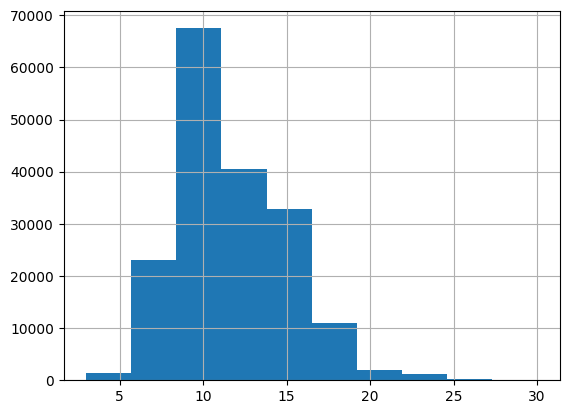

In [ ]:
train_df.total_lines.hist()

Okay, looks like most of the abstracts are around 7 to 15 sentences in length.

It's good to check these things out to make sure when we do train a model or test it on unseen samples, our results aren't outlandish.

## Get lists of sentences

When we build our deep learning model, one of its main inputs will be a list of strings (the lines of an abstract).

We can get these easily from our DataFrames by calling the `tolist()` method on our `"text"` columns.

In [ ]:
# convert abstract text lines into lists
train_sentences = train_df['text'].tolist()
val_sentences = val_df['text'].tolist()
test_sentences = test_df['text'].tolist()

len(train_sentences), len(val_sentences), len(test_sentences)

(180040, 30212, 30135)

In [ ]:
# view first 10 lines of training sentences
train_sentences[:10]

['to investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( oa ) .',
 'a total of @ patients with primary knee oa were randomized @:@ ; @ received @ mg/day of prednisolone and @ received placebo for @ weeks .',
 'outcome measures included pain reduction and improvement in function scores and systemic inflammation markers .',
 'pain was assessed using the visual analog pain scale ( @-@ mm ) .',
 'secondary outcome measures included the western ontario and mcmaster universities osteoarthritis index scores , patient global assessment ( pga ) of the severity of knee oa , and @-min walk distance ( @mwd ) .',
 'serum levels of interleukin @ ( il-@ ) , il-@ , tumor necrosis factor ( tnf ) - , and high-sensitivity c-reactive protein ( hscrp ) were measured .',
 'there was a clinic

Alright, we've separated our text samples. As you might've guessed, we'll have to write code to cnvert the text to numbers before we can use it with our machine learning models, we'll get to this soon.

## Make numeric labels (ML models require numeric labels)

We're going to create one hot and label encoded labels.

We could get away with just making label encoded labels, however, TensorFlow's Categorical Crossentropy loss function likes to have one hot encoded labels (this will enable us to use label smoothing later on).

To numerically encode labels we'll use Scikit-Learn's [`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) and [`LabelEncoder`](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html) classes.

In [ ]:
# one hot encode labels
from sklearn.preprocessing import OneHotEncoder

one_hot_encoder = OneHotEncoder(sparse_output=False)

train_labels_one_hot = one_hot_encoder.fit_transform(train_df['target'].to_numpy().reshape(-1, 1))
val_labels_one_hot = one_hot_encoder.transform(val_df['target'].to_numpy().reshape(-1, 1))
test_labels_one_hot = one_hot_encoder.transform(test_df['target'].to_numpy().reshape(-1, 1))

# check what training labels look like
train_labels_one_hot

array([[0., 0., 0., 1., 0.],
       [0., 0., 1., 0., 0.],
       [0., 0., 1., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.]])

## Label encode labels

In [ ]:
# extract labels ('target' columns) and encode them into integers
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

train_labels_encoded = label_encoder.fit_transform(train_df['target'].to_numpy())
val_labels_encoded = label_encoder.transform(val_df['target'].to_numpy())
test_labels_encoded = label_encoder.transform(test_df['target'].to_numpy())

# check what training labels look like
train_labels_encoded

array([3, 2, 2, ..., 4, 1, 1])

Now we've trained an instance of `LabelEncoder`, we can get the class names and number of classes using the `classes_` attribute.

In [ ]:
# get class names and number of classes from LabelEncoder instance
num_classes = len(label_encoder.classes_)
class_names = label_encoder.classes_
num_classes, class_names

(5,
 array(['BACKGROUND', 'CONCLUSIONS', 'METHODS', 'OBJECTIVE', 'RESULTS'],
       dtype=object))

## Creating a series of model experiments

We've preprocessed our data so now, in true machine learning fashion, it's time to setup a series of modelling experiments.

We'll start by creating a simple baseline model to obtain a score we'll try to beat by building more and more complex models as we move towards replicating the sequence model outlined in [*Neural networks for joint sentence classification in medical paper abstracts*](https://arxiv.org/pdf/1612.05251.pdf).

For each odel, we'll train it on the training data and evaluate it on the validation data.

### Model 0: Getting a baseline

Our first model will be a TF_IDF Multinomial Naive Bayes as recommeded by [Scikit-Learn's nachine learning map](https://scikit-learn.org/stable/tutorial/machine_learning_map/index.html).

To build it, we'll create a Scikit-Learn `Pipeline` which uses the [`TfidfVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) class to convert our abstract sentences to numbers using the TF-IDF (term frequency-inverse document frequency) algorithm and then learn's to classify our sentences using the [`MultinomialNB`](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html) algorithm.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

# create a pipeline
model_0 = Pipeline([
    ('tf-idf', TfidfVectorizer()),
    ('clf', MultinomialNB())
])

# fit the pipeline to the training data
model_0.fit(X=train_sentences,
            y=train_labels_encoded)

Pipeline(steps=[('tf-idf', TfidfVectorizer()), ('clf', MultinomialNB())])

Due to the speed of the Multinomial Naive Bayes algorithm, it trains very quicklu=y.

We can evaluate our model's accuracy on the validation dataset using the `score()` method.

In [ ]:
# evaluate baseline on validation dataset
model_0.score(X=val_sentences,
              y=val_labels_encoded)

0.7218323844829869

Nice! Looks like 72.2% accuracy will be the number to beat with our deeper models.

Now let's make some predictions with our baseline model to further evaluate it.

In [ ]:
# Make predictions
baseline_preds = model_0.predict(val_sentences)
baseline_preds

array([4, 1, 3, ..., 4, 4, 1])

To evaluate our baseline's predictions, we'll import the `calculate_results()` function we created in the previous notebook and added it to our [`helper_functions.py` script](https://github.com/mrdbourke/tensorflow-deep-learning/blob/main/extras/helper_functions.py) to compare them to the ground truth labels.

More specifically the `calculate_results()` function will help us obtain the following:
* Accuracy
* Precision
* Recall
* F1-score

## Download helper functions script

Let's get our `helper_functions.py` script we've been using to store helper functions we've created in previous notebooks.

In [ ]:
# Download helper functions script
!wget https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/helper_functions.py

--2026-09-19 14:55:01--  https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/helper_functions.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10246 (10K) [text/plain]
Saving to: ‘helper_functions.py’

helper_functions.py 100%[===================>]  10.01K  --.-KB/s    in 0s      

2026-09-19 14:55:01 (28.4 MB/s) - ‘helper_functions.py’ saved [10246/10246]



Now we've got the helper functions script we can import the `calculate_results()` function and see how our baseline model went.

In [ ]:
# import calculate_Results helper functions
from helper_functions import calculate_results

In [ ]:
# calculate baseline results
baseline_results = calculate_results(y_true=val_labels_encoded,
                                     y_pred=baseline_preds)

baseline_results

{'accuracy': 72.1832384482987,
 'precision': 0.7186466952323352,
 'recall': 0.7218323844829869,
 'f1': 0.6989250353450294}

## Preparing our data for deep sequence models

Excellent! We've got a working baseline to try and improve upon.

But before we start building deeper models, we've got to create vectorization and embedding layers.

The vectorization layer will convert our text to numbers and the embedding layer will capture the relationships between those numbers.

To start creating our vectorization and embedding layers, we'll need to import the appropriate libraries (namely TensorFlow and NumPy)

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers

Since we'll be turning our sentences into numbers, it's a good idea to figure out how many words are in each sentence.

When our model goes through our sentences, it works best when they're all the same length (this is important for creating batches of same size tensors).

For example, if one sentence is eight words longs and another is 29 words long,  we want to pad the eight word sentence with zeroes so it ends up being the same length as the 29 words sentence.

Let's write some code to find the average length of sentences in the training set.

In [ ]:
# how long is each sentence on average?
sent_lengths = [len(sentence.split()) for sentence in train_sentences]
avg_sent_len = np.mean(sent_lengths)
max_sent_len = np.max(sent_lengths)
min_sent_len = np.min(sent_lengths)

avg_sent_len, max_sent_len, min_sent_len # returns min, avg and max sentence lengths (in tokens)

(np.float64(26.338269273494777), np.int64(296), np.int64(1))

How about the distribution of sentence lengths?

(array([1.5999e+05, 1.8760e+04, 1.1510e+03, 9.9000e+01, 2.8000e+01,
        1.0000e+01, 2.0000e+00]),
 array([  1.        ,  43.14285714,  85.28571429, 127.42857143,
        169.57142857, 211.71428571, 253.85714286, 296.        ]),
 <BarContainer object of 7 artists>)

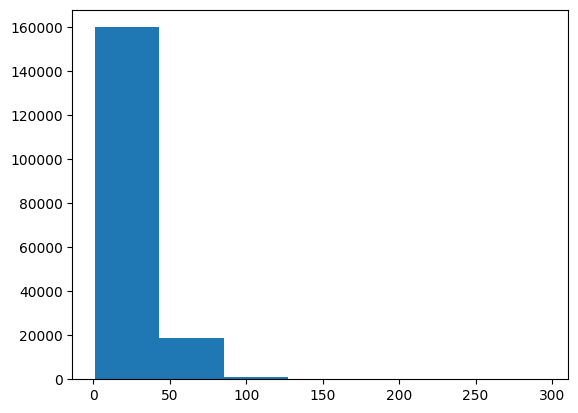

In [ ]:
# what does the distibution look like?
import matplotlib.pyplot as plt
plt.hist(sent_lengths, bins=7)

Looks like the vast majority of sentences are between 0 and 50 tokens in length.

We can use NumPy's [`percentile`](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html) to find the value which covers 95% of the sentence lengths.

In [ ]:
# how long of a sentence convers 95% of the lengths?
output_seq_len = int(np.percentile(sent_lengths, 95))
output_seq_len

55

Wonderful! It looks like 95% of the sentences in our training set have a length of 55 tokens or less.

When we create our tokenization layer, we'll use this value to turn all of our sentences into the same lenght. Meaning sentences with a length of below 55 get padded with zeroes and sentences with a lenght above 55 get truncated (words after 55 get cut off).

> 🤔 **Question:** Why 95%?

We could use the max sentence length of the sentences in the training set.

In [ ]:
# maximum sentence length in the training set
max_sent_len

np.int64(296)

However, since hardly any sentences even come close to the max length, it would mean the majority of the data we pass to our model would be zeroes (since all sentences below the max length would get padded with zeroes).

> 🔑 **Note:** The steps we've gone through are good practice when working with a text corpus for an NLP problem. You want to know how long your samples are and what the distribution of them is. See section 4 Data Analysis of the[PubMed 200k RCT paper](https://arxiv.org/pdf/1710.06071.pdf) for further examples.

## Create text vecotrizer

Now we've got a little more information about oru texts, let's create a way to turn it into numbers.

To do so, we'll use the [`TextVectorization`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/experimental/preprocessing/TextVectorization) layer from TensorFlow.

We'll keep all the parameters default except for `max_tokens` (the number of unique words in our dataset) and `output_sequence_length` (our desired output length for each vectorized sentence).

Section 3.2 of the [PubMed 200k RCT paper](https://arxiv.org/pdf/1710.06071.pdf) states the vocabulary size of the PubMed 20k dataset as 68,000. So we'll use that as our `max_tokens` parameter.

In [ ]:
# how many words are in our vocabulary? (taken from 3.2 in https://arxiv.org/pdf/1710.06071.pdf)
max_tokens = 68000

And since we discovered a sentence length of 55 covers 95% of the training sentences, we'll use that as our `output_sequence_length` parameter.

In [ ]:
# create text vecotrizer

from tensorflow.keras.layers import TextVectorization

text_vectorizer = TextVectorization(max_tokens=max_tokens, # number of words in the vocabulary
                                    output_sequence_length=55) # desired output length of vectorized sequences

Great! Looks like our `text_vectorizer` is ready, let's adapt it to the training data (let it read the training data and figure out what number should represent what word) and then text it out.

In [ ]:
# adapt text vectorizer to training sentences
text_vectorizer.adapt(train_sentences)

In [ ]:
# test out text vectorizer
import random
target_sentence = random.choice(train_sentences)

print(f"Text:\n{target_sentence}")
print(f"\nLength of text: {len(target_sentence.split())}")
print(f"\nVectorized text:\n{text_vectorizer([target_sentence])}")

Text:
the long-term estimate also predicts increased costs , but considerably less in the intervention group : us$ -@,@ ( @ % ci : us$ -@,@ to us$ -@,@ ) in the societal , and us$ -@,@ ( @ % ci : us$ -@,@ to us$ @,@ ) in the health care perspective .

Length of text: 53

Vectorized text:
[[   2  335 1455  138 4307   96  577   72 4795  211    5    2   38   13
   850   50  850    6  850    5    2 3766    3  850   50  850    6  850
     5    2   97   77 2440    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0]]


Cool, we;ve now got a way to turn our sequences into numbers.

> 🛠️ Exercise: Try running the cell above a dozen or so times. What do you notice about sequences with a length less than 55?

Using the [`get_vocabulary()`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/experimental/preprocessing/TextVectorization) method of our `text_vectorizer` we can find out a few different tidbits about our text.

In [ ]:
# how many words in our training vocabulary?
rct_20k_text_vocab = text_vectorizer.get_vocabulary()

print(f"Number of words in vocabulary: {len(rct_20k_text_vocab)}")
print(f"Most common words in the vocabulary: {rct_20k_text_vocab[:5]}")
print(f"Least common words in the vocabulary: {rct_20k_text_vocab[-5:]}")

Number of words in vocabulary: 64841
Most common words in the vocabulary: ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('of')]
Least common words in the vocabulary: [np.str_('aainduced'), np.str_('aaigroup'), np.str_('aachener'), np.str_('aachen'), np.str_('aaacp')]


And if we wanted to figure out the configuration of our `text_vecotrizer` we can use the `get_config()` method.

In [ ]:
# get the configuration of our text vectorizer
text_vectorizer.get_config()

{'name': 'text_vectorization',
 'trainable': True,
 'dtype': 'string',
 'batch_input_shape': (None,),
 'max_tokens': 68000,
 'standardize': 'lower_and_strip_punctuation',
 'split': 'whitespace',
 'ngrams': None,
 'output_mode': 'int',
 'output_sequence_length': 55,
 'pad_to_max_tokens': False,
 'sparse': False,
 'ragged': False,
 'vocabulary': None,
 'idf_weights': None,
 'encoding': 'utf-8',
 'vocabulary_size': 64841}

## Create custom text embedding

Our `token_vectorization` layer maps the words in our text directly to numbers. However, this doesn't necessarily capture the relationships between those numbers.

To create a richer numerical representation of our text, we can use an **embedding**.

As our model learns (by going through many different examples of abstract sentences and their labels), it'll update its embedding to better represent the relationships between tokens in our corpus.

We can create a trainable embedding layer using TensorFlow's [`Embedding`](https://www.tensorflow.org/tutorials/text/word_embeddings) layer.

Once again, the main paramters we're concerned with here are the inputs and outputs of our `Embedding` layer.

The `input_dim` paramter defines the size of our vocabulary. And the `output_dim` paramter defines the dimension of the embedding output.

Once created, our embedding layer will take the integer outputs of our `text_vectorization` layer as unputs and convert them to feature vectors of size `output_dim`.

Let's see it in action.

In [ ]:
# create token embedding layer
token_embed = layers.Embedding(input_dim=len(rct_20k_text_vocab), # length of vocabulary
                               output_dim=128, # Note: different embedding sizes result in drastically different number of parameters to train
                               # Ysemasking to handle variable sequence lengths (saves space)
                               mask_zero=True,
                               name='token_embedding')

# show example embedding
print(f"Sentence before vectorization:\n{target_sentence}\n")

vectorized_sentence = text_vectorizer([target_sentence])
print(f"Sentence after vectorization (before embedding):\n{vectorized_sentence}\n")

embedded_sentence = token_embed(vectorized_sentence)
print(f"Sentence after embedding:\n{embedded_sentence}\n")
print(f"Embedded sentence shape: {embedded_sentence.shape}")

Sentence before vectorization:
the long-term estimate also predicts increased costs , but considerably less in the intervention group : us$ -@,@ ( @ % ci : us$ -@,@ to us$ -@,@ ) in the societal , and us$ -@,@ ( @ % ci : us$ -@,@ to us$ @,@ ) in the health care perspective .

Sentence after vectorization (before embedding):
[[   2  335 1455  138 4307   96  577   72 4795  211    5    2   38   13
   850   50  850    6  850    5    2 3766    3  850   50  850    6  850
     5    2   97   77 2440    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0]]

Sentence after embedding:
[[[-0.04903716 -0.03772451 -0.03924221 ...  0.0313993   0.04352826
    0.00312891]
  [-0.02167685  0.00303216  0.04750733 ... -0.02052847  0.02555202
    0.00193588]
  [ 0.03002502  0.04636678  0.02974112 ...  0.02130829 -0.0342593
   -0.01984043]
  ...
  [ 0.0012082  -0.01535194  0.00492469 ...  0.0455392   0.0369673
    0.02290124]
  [ 0.0012082  -0.01535194

## Create datasets (as fast as possible)

We've gone through all the trouble of preprocessing our datasets to be used with a machine learning model, however, there are still a few steps we can use to make them work fast with out models.

Namely, the `tf.data` API provides methods which enable faster data loaded.

> 📖 **Resource:** For best practices on data loading in TensorFlow, check out the following:
* [tf.data: Build TensorFlow input pipelines](https://www.tensorflow.org/guide/data)

* [Better performance with the tf.data API](https://www.tensorflow.org/guide/data_performance)

The main steps we'll want to use with our data is to turn it into a `PrefetchDataset` of batches.

Doing so we'll ensure TensorFlow loads our data onto GPU as fast as possible, in turn leading to faster training time.

To create a batched `PrefetchDataset` we can use the methods [`batch()`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#batch) and [`prefetch()`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#prefetch), the paramter [`tf.data.AUTOTUNE`](https://www.tensorflow.org/api_docs/python/tf/data#AUTOTUNE) will also allow TensorFlow to determine the optimal amount to use to prepare datasets.

In [ ]:
# turn our data into TensorFlow datasets
train_dataset = tf.data.Dataset.from_tensor_slices((train_sentences, train_labels_one_hot))
valid_dataset = tf.data.Dataset.from_tensor_slices((val_sentences, val_labels_one_hot))
test_dataset = tf.data.Dataset.from_tensor_slices((test_sentences, test_labels_one_hot))

train_dataset

<_TensorSliceDataset element_spec=(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(5,), dtype=tf.float64, name=None))>

In [ ]:
# take the TensorSliceDataset's and turn them into prefetched batches
train_dataset = train_dataset.batch(32).prefetch(tf.data.AUTOTUNE)
valid_dataset = valid_dataset.batch(32).prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(32).prefetch(tf.data.AUTOTUNE)

train_dataset

<_PrefetchDataset element_spec=(TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None, 5), dtype=tf.float64, name=None))>

## Model 1: Conv1D with token embeddings

Alright, we've now got a way to numerically represent our text and labels, time to build a series of deep learning models to try and improve upon our baseline.

All of our deep models will follow a similar structure:
```
Input (text) -> Tokenize -> Embedding -> Layers -> Output (labek probability)
```

The main component we'll be changing throughout is the `Layers` component. Because any modern deep NLP model requires text to be converted into an embedding before meaningful patterns can be discovered within.

The first model we're going to build is a 1-dimensional Convolutional Neural Network.

We're also going to be following a standar machine learning workflow of:
* Build model
* Train model
* Evaluate model (make predictions and compare to ground truth)

In [ ]:
# create 1D convolutional model to process sequences
inputs = layers.Input(shape=(1,), dtype=tf.string)

text_vectors = text_vectorizer(inputs) # vectorize text inputs
token_embeddings = token_embed(text_vectors) # create embedding

x = layers.Conv1D(64, kernel_size=5, padding='same', activation='relu')(token_embeddings)
x = layers.GlobalAveragePooling1D()(x) # condense the output of our feature vector

outputs = layers.Dense(num_classes, activation='softmax')(x)

model_1 = tf.keras.Model(inputs, outputs)

# compile
model_1.compile(loss='categorical_crossentropy', # if your labels are integer type (not one hot) use sparse_categorical_crossentropy
                optimizer='adam',
                metrics=['accuracy'])

In [ ]:
# get summary of Conv1D model
model_1.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 1)]               0         
                                                                 
 text_vectorization (TextVe  (None, 55)                0         
 ctorization)                                                    
                                                                 
 token_embedding (Embedding  (None, 55, 128)           8299648   
 )                                                               
                                                                 
 conv1d (Conv1D)             (None, 55, 64)            41024     
                                                                 
 global_average_pooling1d (  (None, 64)                0         
 GlobalAveragePooling1D)                                         
                                                             

Wonderful! We've got our first deep sequence model built and ready to go.

Checking out the model summary, you'll notice the majority of the trainable paramters are within the embedding layer.

If we were to increase the size of the embedding (by increasing the `output_dim` parameter of the `Embedding` layer), the number of trainable parameters would increase dramatically.

It's time to fit our model to the training data but we're going to make a mindful change.

Since our training data contrainings nearly 200,000 sentences, fitting a deep model may take a while even with a GPU. So to keep our experiments swift, we're going to run them on a subset of the training dataset.

More specifically, we'll only use the first 10% of batches (about 18,000 samples) of the training set to train on and the first 10% batches of the validation set to validate on.

> 🔑 **Note:** It's a standard practice in machine learning to test your models on smaller subsets of data first to make sure they work before scaling them to larger amounts of data. You should aim to run many smaller experiments rather than only a handful of large experiments. And since your time is limited, one of the best ways to run smaller experiments is to reduce the amount of data you're working with (10% of the full datasset is usually a good amount, as long as it covers a similar distribution).

In [ ]:
# fit the model
model_1_history = model_1.fit(train_dataset,
                              steps_per_epoch=int(0.1 * len(train_dataset)), # only fir on 10% of batches for faster training times
                              epochs=3,
                              validation_data=valid_dataset,
                              validation_steps=int(0.1 * len(valid_dataset))) # only validate on 10% of batches

Epoch 1/3
562/562 [==============================] - 28s 45ms/step - loss: 0.9219 - accuracy: 0.6346 - val_loss: 0.6827 - val_accuracy: 0.7367
Epoch 2/3
562/562 [==============================] - 6s 11ms/step - loss: 0.6515 - accuracy: 0.7595 - val_loss: 0.6249 - val_accuracy: 0.7736
Epoch 3/3
562/562 [==============================] - 6s 10ms/step - loss: 0.6110 - accuracy: 0.7785 - val_loss: 0.5952 - val_accuracy: 0.7852


Brilliant! We've got our first trained deep sequence model, and it didn't take too long (and if we didn't prefetch our batched data, ti would've taken longer).

Time to make some predictions with our model and then evaluate them.

In [ ]:
# evaluate on whole validation dataset (we only validated on 10% of batches during training)
model_1.evaluate(valid_dataset)

945/945 [==============================] - 3s 3ms/step - loss: 0.5942 - accuracy: 0.7871


[0.5941907167434692, 0.7870713472366333]

In [ ]:
# make predictions (our model outputs prediction probabilities for each class)
model_1_pred_probs = model_1.predict(valid_dataset)
model_1_pred_probs

945/945 [==============================] - 2s 2ms/step


array([[4.5313132e-01, 1.4835808e-01, 7.3559262e-02, 3.0182639e-01,
        2.3125006e-02],
       [4.2292592e-01, 2.7580398e-01, 1.4560591e-02, 2.7720961e-01,
        9.4999522e-03],
       [1.2475848e-01, 1.0069456e-02, 1.1344030e-03, 8.6400604e-01,
        3.1669148e-05],
       ...,
       [7.8116100e-06, 4.5595216e-04, 4.5751611e-04, 4.5525148e-06,
        9.9907410e-01],
       [6.3238576e-02, 4.2462528e-01, 1.0300105e-01, 8.5047401e-02,
        3.2408768e-01],
       [1.3623032e-01, 7.5725257e-01, 3.1173535e-02, 3.1781740e-02,
        4.3561824e-02]], dtype=float32)

In [ ]:
# convert pred probs to classes
model_1_preds = tf.argmax(model_1_pred_probs, axis=1)
model_1_preds

<tf.Tensor: shape=(30212,), dtype=int64, numpy=array([0, 0, 3, ..., 4, 1, 1])>

In [ ]:
# calculate model_1 results
model_1_results = calculate_results(y_true=val_labels_encoded,
                                    y_pred=model_1_preds)
model_1_results

{'accuracy': 78.70713623725672,
 'precision': 0.7843097834920143,
 'recall': 0.7870713623725671,
 'f1': 0.7846874516371526}

## Model 2: Feature extraction with pretrained token embeddings

Training our own embeddings took a little while to run, slowing our experiments down.

Since we're moving towards replicating the model architecture in [Neural Netowrks for Joint Sentence Classification in Medical Paper Abstracts](https://arxiv.org/pdf/1612.05251.pdf), it mentions they used a [pretrained GloVe embedding](https://nlp.stanford.edu/projects/glove/) as a way to initialize their token embeddings.

To emulate this, let's see what results we can get with the [pretrained Universal Sentence Encoder embeddings from TensorFlow Hub](https://tfhub.dev/google/universal-sentence-encoder/4).

> 🔑 **Note:** We could use GloVe embeddings as per the paper but since we are working with TensorFlow, we'll use what's available from TensorFlow Hub (GloVe embeddings aren't). We'll save [using pretrained GloVe embeddings](https://keras.io/examples/nlp/pretrained_word_embeddings/) as an extension.

The model will look like:
```
Inputs (string) -> Pretrained embeddings from TensorFlow Hub (Universal Sentence Encoder) -> Layers -> Output (prediction probabilities)
```

You'll notice the lack of tokenization layer we've used in a previous model. This is because the Universal Sentence Encoder (USE) takes care of tokenization for us.

This type of model is called transfer learning, more specifically, **feature extraction transfer learning**. In other words, taking the patterns a model has learned elsewhere and applying it to our own problem.

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/09-model-tf-hub-USE-to-dense-layer.png)
*The feature extractor model we're building using a pretrained embedding from TensorFlow Hub.*

To download the pretrained USE into a layer we can use in our model, we can use the [`hub.KerasLayer`](https://www.tensorflow.org/hub/api_docs/python/hub/KerasLayer) class.

We'll keep the pretrained embeddings frozen (by setting `trainable=False`) and add a couple of trainable layers on the top to tailor the model outputs to our own data.

>🔑 **Note:** Due to having to download a relatively large model (~916 MB), the cell below may take a little while to run.

In [ ]:
# Download pretrained TensorFlow Hub USE
import tensorflow_hub as hub
tf_hub_embedding_layer = hub.KerasLayer("https://tfhub.dev/google/universal-sentence-encoder/4",
                                        trainable=False,
                                        name="universal_sentence_encoder")

Beautiful, now our pretrained USE is downloaded and instantiated as a `hub.KerasLayer` instance, let's test it out on a random sentence.

In [ ]:
# test out the embedding on a random sentence
random_training_sentence = random.choice(train_sentences)
print(f"Random training sentence:\n{random_training_sentence}\n")

use_embedded_sentence = tf_hub_embedding_layer([random_training_sentence])
print(f"Sentence after embedding:\n{use_embedded_sentence[0][:30]} (truncated output)...\n")
print(f"Length of sentence embedding: \n{len(use_embedded_sentence[0])}")

Random training sentence:
time from randomization to the first relapse event ( time to relapse ) in the db phase .

Sentence after embedding:
[ 0.06592436 -0.05460121 -0.03405702 -0.02549915 -0.0498423   0.01312745
  0.03903611 -0.01536277  0.04793787  0.07610413 -0.01103771 -0.00422196
  0.02346219  0.02148262  0.0086836  -0.01907803 -0.04139708 -0.02118148
 -0.00753633  0.05436851 -0.08027104  0.0053263  -0.02018791 -0.01514559
 -0.00517496  0.02214541 -0.06689079  0.00379113 -0.03558023 -0.06541738] (truncated output)...

Length of sentence embedding: 
512


Nice! As we mentioned before the pretrained USE module from TensorFlow Hub takes care of tokenizing our text for us and outputs a 512 dimensional embedding vector.

Let's put together and compile a model using our `tf_hub_embedding_layer`.

Building and fitting an NLP feature extraction model from TensorFlow Hub

In [ ]:
# define feature extractor model using TF Hub layer
inputs = layers.Input(shape=[], dtype=tf.string)

pretrained_embedding = tf_hub_embedding_layer(inputs) # tokenize text and create embedding

x = layers.Dense(128, activation='relu')(pretrained_embedding) # add a fully connected layer on top of the embedding
# Note: we can add more layers here if we want to

outputs = layers.Dense(5, activation='softmax')(x) # create the output layer

model_2 = tf.keras.Model(inputs=inputs,
                         outputs=outputs)

# compile the model
model_2.compile(loss='categorical_crossentropy',
                optimizer='adam',
                metrics=['accuracy'])

In [ ]:
# get a summary of the model
model_2.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None,)]                 0         
                                                                 
 universal_sentence_encoder  (None, 512)               256797824 
  (KerasLayer)                                                   
                                                                 
 dense_1 (Dense)             (None, 128)               65664     
                                                                 
 dense_2 (Dense)             (None, 5)                 645       
                                                                 
Total params: 256864133 (979.86 MB)
Trainable params: 66309 (259.02 KB)
Non-trainable params: 256797824 (979.61 MB)
_________________________________________________________________


Checking the summary of our model we can see there's a large number of total paramters, however, the majority of these are non-trainable. This is becase we set `training=False` when we instantiated our USE feature extractor layer.

So when we train our model, only the top two output layers will be trained.

In [ ]:
# fit the feature extractor model for 3 epochs
model_2_history = model_2.fit(train_dataset,
                              steps_per_epoch=int(0.1 * len(train_dataset)),
                              epochs=3,
                              validation_data=valid_dataset,
                              validation_steps=int(0.1 * len(valid_dataset)))

Epoch 1/3
562/562 [==============================] - 13s 16ms/step - loss: 0.9185 - accuracy: 0.6491 - val_loss: 0.7953 - val_accuracy: 0.6908
Epoch 2/3
562/562 [==============================] - 10s 18ms/step - loss: 0.7684 - accuracy: 0.7028 - val_loss: 0.7515 - val_accuracy: 0.7081
Epoch 3/3
562/562 [==============================] - 11s 19ms/step - loss: 0.7485 - accuracy: 0.7137 - val_loss: 0.7350 - val_accuracy: 0.7154


In [ ]:
# evaluate on whole validation dataset
model_2.evaluate(valid_dataset)

945/945 [==============================] - 12s 13ms/step - loss: 0.7383 - accuracy: 0.7152


[0.7382960319519043, 0.7151793837547302]

Since we aren't training our own custom embedding layer, training is much quicker.

Let's make some predictions and evaluate our feature extraction model.

In [ ]:
# make predictions with feafture extraction model
model_2_pred_probs = model_2.predict(valid_dataset)
model_2_pred_probs

945/945 [==============================] - 12s 12ms/step


array([[4.4080287e-01, 3.5411155e-01, 2.2124010e-03, 1.9382331e-01,
        9.0498421e-03],
       [2.9813451e-01, 5.3698385e-01, 4.5288899e-03, 1.5706964e-01,
        3.2830799e-03],
       [2.1890317e-01, 1.5283422e-01, 1.3596372e-02, 5.7616585e-01,
        3.8500391e-02],
       ...,
       [1.7897572e-03, 5.8015492e-03, 4.6750519e-02, 7.2438072e-04,
        9.4493377e-01],
       [4.2855218e-03, 4.5880731e-02, 1.9716093e-01, 1.5094642e-03,
        7.5116336e-01],
       [1.5891482e-01, 2.2830901e-01, 5.3718197e-01, 6.2769521e-03,
        6.9317199e-02]], dtype=float32)

In [ ]:
# convert the predictions with feature extraction model to classes
model_2_preds = tf.argmax(model_2_pred_probs, axis=1)
model_2_preds

<tf.Tensor: shape=(30212,), dtype=int64, numpy=array([0, 1, 3, ..., 4, 4, 2])>

In [ ]:
# calculate results from TF Hub pretrained embeddings results on validation set
model_2_results = calculate_results(val_labels_encoded,
                                    model_2_preds)
model_2_results

{'accuracy': 71.51793989143387,
 'precision': 0.7155376013152608,
 'recall': 0.7151793989143387,
 'f1': 0.7122709045787224}

## Model 3: Conv1D with character embeddings

**Creating a character-level tokenizer**

The [*Neural Networks for Joing Sentence Classification in Medical Paper Abstracts*](https://arxiv.org/pdf/1612.05251.pdf) paper mentions their model uses a hybrid of token and character embeddings.

We've built models with a custom token embedding and a pretrained token embedding, how about we build one using a character embedding?

The difference between a character and token embedding is that the **charcter embedding** is created using sequences split into charcters (e.g. `hello` -> [`h`, `e`, `l`, `l`, `o`]) where as a **token embedding is created on sequences split into tokens**.

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/09-token-vs-character-embeddings.png)
*Token level embeddings split sequences into tokens (words) and embeds each of them, charcter embeddings split sequences into characters and creates a feature vector for each.*

We can create a character level embedding by first vectorizing our sequences (after they've been split into characters) using the [`TextVectorization`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/experimental/preprocessing/TextVectorization) class and then passing those vectorized sequences through an [`Embedding`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Embedding) layer.

Before we can vectorize our sequences on a character level we'll need to split them into characters. Let's write a function to do so.

In [ ]:
# make function to split sentences into characters
def split_chars(text):
  return " ".join(list(text))

# split_chars(random_training_sentence)

Great! Looks like our character-splitting function works. Let's create character-level embedding datasets by splitting our sequence datasets into characters.

In [ ]:
# split sequence-level data splits into character-level data splits
train_chars = [split_chars(sentence) for sentence in train_sentences]
val_chars = [split_chars(sentence) for sentence in val_sentences]
test_chars = [split_chars(sentence) for sentence in test_sentences]

print(train_chars[0])

t o   i n v e s t i g a t e   t h e   e f f i c a c y   o f   @   w e e k s   o f   d a i l y   l o w - d o s e   o r a l   p r e d n i s o l o n e   i n   i m p r o v i n g   p a i n   ,   m o b i l i t y   ,   a n d   s y s t e m i c   l o w - g r a d e   i n f l a m m a t i o n   i n   t h e   s h o r t   t e r m   a n d   w h e t h e r   t h e   e f f e c t   w o u l d   b e   s u s t a i n e d   a t   @   w e e k s   i n   o l d e r   a d u l t s   w i t h   m o d e r a t e   t o   s e v e r e   k n e e   o s t e o a r t h r i t i s   (   o a   )   .


To figure out how long our vectorized character sequences should be, let's check the distribution of our character sequence lengths.

In [ ]:
# what's the average character length?
char_lens = [len(sentence) for sentence in train_sentences]
mean_char_len = np.mean(char_lens)
min_char_len = np.min(char_lens)
max_char_len = np.max(char_lens)

mean_char_len, min_char_len, max_char_len

(np.float64(149.3662574983337), np.int64(1), np.int64(1386))

(array([1.41175e+05, 3.71110e+04, 1.60000e+03, 1.27000e+02, 2.10000e+01,
        5.00000e+00, 1.00000e+00]),
 array([1.00000000e+00, 1.98857143e+02, 3.96714286e+02, 5.94571429e+02,
        7.92428571e+02, 9.90285714e+02, 1.18814286e+03, 1.38600000e+03]),
 <BarContainer object of 7 artists>)

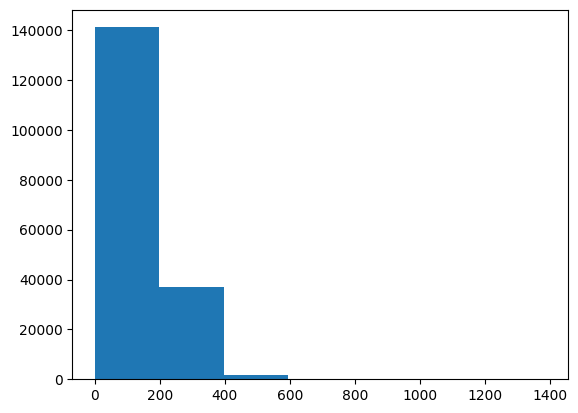

In [ ]:
# check the distribution of our sequences at character-leve
import matplotlib.pyplot as plt
plt.hist(char_lens, bins=7)

Okay, looks like most of our sequences are between 0 and 200 characters long.

Let's use NumPy's percentile to figure out what length covers 95% of our sequences.

In [ ]:
import numpy as np
# find what character length covers 95% of sequences
output_seq_char_len = int(np.percentile(char_lens, 95))
output_seq_char_len

290

Wonderful, now we know the sequence length which covers 95% of sequences, we'll use that in our `TextVectorization` layer as the `output_sequence_length` paramter.

> 🔑 **Note:** You can experiment here to figure out what the optimal `output_sequence_length` should be, perfaps using the mean results in as good results as using the 95% percentile.

We'll set `max_tokens` (the total number of different characters in our sequences) to 28, in other words, 26 letters of the alphabet + space + OOV (out of vocabulary or unknown) tokens.

In [ ]:
# get all keyboard characters for char-level embedding
import string
alphabet = string.ascii_lowercase + string.digits + string.punctuation
alphabet

'abcdefghijklmnopqrstuvwxyz0123456789!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [ ]:
from tensorflow.keras.layers import TextVectorization
# create char-level token vectorization instance
NUM_CHAR_TOKENS = len(alphabet) + 2 # num characters in alphabet + space + OOV token
char_vectorizer = TextVectorization(max_tokens=NUM_CHAR_TOKENS,
                                    output_sequence_length=output_seq_char_len,
                                    standardize='lower_and_strip_punctuation',
                                    name='char_vectorizer')

# adapt character vectorizer to training characters
char_vectorizer.adapt(train_chars)

Nice! Now we've adapted our `char_vectorizer` to our character-level sequences, let's check out some characteristics about it using the [`get_vocabulary()`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/experimental/preprocessing/TextVectorization#get_vocabulary) method.

In [ ]:
# check character vocabulary characteristics
char_vocab = char_vectorizer.get_vocabulary()

print(f"Number of different characters in character vocab: {len(char_vocab)}")
print(f" 5 most common characters: {char_vocab[:5]}")
print(f'5 least common characters: {char_vocab[-5:]}')

Number of different characters in character vocab: 28
 5 most common characters: ['', '[UNK]', np.str_('e'), np.str_('t'), np.str_('i')]
5 least common characters: [np.str_('k'), np.str_('x'), np.str_('z'), np.str_('q'), np.str_('j')]


We can also test it on random sequences of characters to make sure it's working.

In [ ]:
import random
# test out character vectorizer
random_train_chars = random.choice(train_chars)

print(f"Charified text:\n{random_train_chars}")
print(f"\nLength of chars: {len(random_train_chars)}")

vectorized_chars = char_vectorizer([random_train_chars])
print(f'\nVectorized chars:\n{vectorized_chars}')
print(f'\nLength of vectorized chars: {len(vectorized_chars[0])}')

Charified text:
w h e t h e r   s u c h   l o s s   o f   i n h i b i t i o n   o r   i m p u l s i v e n e s s   i s   f o o d   c u e - s p e c i f i c   a s   s e e n   i n   o b e s i t y - t h u s   p r o v i d i n g   a   m e c h a n i s m   t h r o u g h   w h i c h   s l e e p   d i s t u r b a n c e s   m a y   p r o m o t e   o b e s i t y   d e v e l o p m e n t - w a r r a n t s   f u r t h e r   i n v e s t i g a t i o n   .

Length of chars: 425

Vectorized chars:
[[20 13  2  3 13  2  8  9 16 11 13 12  7  9  9  7 17  4  6 13  4 22  4  3
   4  7  6  7  8  4 15 14 16 12  9  4 21  2  6  2  9  9  4  9 17  7  7 10
  11 16  2  9 14  2 11  4 17  4 11  5  9  9  2  2  6  4  6  7 22  2  9  4
   3 19  3 13 16  9 14  8  7 21  4 10  4  6 18  5 15  2 11 13  5  6  4  9
  15  3 13  8  7 16 18 13 20 13  4 11 13  9 12  2  2 14 10  4  9  3 16  8
  22  5  6 11  2  9 15  5 19 14  8  7 15  7  3  2  7 22  2  9  4  3 19 10
   2 21  2 12  7 14 15  2  6  3 20  5  8  8  5  6  3  9 17 16  8  3 13  2

You'll notice sequences with a length shorter than 290 (`output_char_length`) get padded with zeroes on the end, this ensures all sequences passsed to our model are the same length.

Also, due to the `standardize` paramters of `TextVectorization` being `"lower_and_strip_punctuation"` and the `split` paramters being `"whitespace"` by default, symbols (such as `@`) and spaces are removed.

> 🔑 **Note:** If you didn't want punctuation to be removed (keep the `@`, `%`, etc.), you can create a custom standardization callable and pass it as the `standardize` paramter. See the [`TextVectorization`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/TextVectorization) layer documentation for more.

**Creating a character level embedding**

We've got a way to vectorize our character-level sequences, now its time to create a character-level embedding.

Just like our custom token embedding, we can do so using the [`tensorflow.keras.layers.Embedding`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Embedding) class.

Our character-level embedding layer requires an input dimension and output dimension.

The input dimension (`input_dim`) will be equal to the number of different characters in our `char_vocab` (28). And since we're following the structure of the model in Figure 1 of [*Neural Networks for Joint Sentence Classification in Medical Paper Abstracts*](https://arxiv.org/pdf/1612.05251.pdf), the output dimension of the character embedding (`output_dim`) will be 25.

In [ ]:
# crete char embedding layer
char_embed = layers.Embedding(input_dim=NUM_CHAR_TOKENS, # number of different characters
                              output_dim=25, # embedding dimension of each character (same as Figure 1 in https://arxiv.org/pdf/1612.05251.pdf)
                              mask_zero=False, # don't use masks (this messes up model_5 if set to True)
                              name='char_embed')

# test out character embedding layer
print(f"Charified text (before vectorization and embedding):\n{random_train_chars}\n")

char_embed_example = char_embed(char_vectorizer([random_train_chars]))

print(f"Embedded chars (after vectorization and embedding):\n{char_embed_example}\n")
print(f"Character embedding shape: {char_embed_example.shape}")

Charified text (before vectorization and embedding):
w h e t h e r   s u c h   l o s s   o f   i n h i b i t i o n   o r   i m p u l s i v e n e s s   i s   f o o d   c u e - s p e c i f i c   a s   s e e n   i n   o b e s i t y - t h u s   p r o v i d i n g   a   m e c h a n i s m   t h r o u g h   w h i c h   s l e e p   d i s t u r b a n c e s   m a y   p r o m o t e   o b e s i t y   d e v e l o p m e n t - w a r r a n t s   f u r t h e r   i n v e s t i g a t i o n   .

Embedded chars (after vectorization and embedding):
[[[-0.02995053 -0.02694345  0.01996911 ...  0.00590961 -0.04824889
   -0.03993993]
  [-0.02942061  0.02956618 -0.04874438 ...  0.02829074 -0.00293269
    0.02001497]
  [-0.00223663  0.03582554 -0.00265788 ...  0.01166504 -0.04518835
    0.04755764]
  ...
  [-0.0445617  -0.02398258  0.01047305 ... -0.00715024 -0.0330237
   -0.01614828]
  [-0.0445617  -0.02398258  0.01047305 ... -0.00715024 -0.0330237
   -0.01614828]
  [-0.0445617  -0.02398258  0.01047305 ... -0.007

Wonderful! Each of the characters in our sequence gets turned into a 25 dimension embedding.

**Building a Conv1D model to fit on character embeddings**

Now we've got a way to turn our character-level sequences into numbers (`char_vectorizer`) as well as numerically represent them as an embedding (`char_embed`) let's test how effective they are at encoding the information in our sequences by creating a character-level sequence model.

The model will have the same structure as our custom token embedding model (`model_1`) except it'll take character-level sequences as inpput instead of token-level sequences.

```
Input (character-level text) -> Tokenize -> Embedding -> Layers (Conv1D, GlobalMaxPool1D) -> Output (label probability)
```

In [ ]:
# make Conv!d on chars only
inputs = layers.Input(shape=(1,), dtype='string')

char_vectors = char_vectorizer(inputs)
char_embeddings = char_embed(char_vectors)

x = layers.Conv1D(64, kernel_size=5, padding='same', activation='relu')(char_embeddings)
x = layers.GlobalMaxPool1D()(x)

outputs = layers.Dense(num_classes, activation='softmax')(x)

model_3 = tf.keras.Model(inputs=inputs,
                         outputs=outputs,
                         name='model_3_conv1D_char_embedding')

# compile model

model_3.compile(loss='categorical_crossentropy',
                optimizer='adam',
                metrics=['accuracy'])

In [ ]:
# check the summary of our conv1d_char_model
model_3.summary()

Model: "model_3_conv1D_char_embedding"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 1)]               0         
                                                                 
 char_vectorizer (TextVecto  (None, 290)               0         
 rization)                                                       
                                                                 
 char_embed (Embedding)      (None, 290, 25)           1750      
                                                                 
 conv1d_1 (Conv1D)           (None, 290, 64)           8064      
                                                                 
 global_max_pooling1d (Glob  (None, 64)                0         
 alMaxPooling1D)                                                 
                                                                 
 dense_3 (Dense)             (None, 5

Before fitting our model on the data, we'll create char-level batched `PrefetchDataset`'s.

In [ ]:
# create char datasets
train_char_dataset = tf.data.Dataset.from_tensor_slices((train_chars, train_labels_one_hot)).batch(32).prefetch(tf.data.AUTOTUNE)
val_char_dataset = tf.data.Dataset.from_tensor_slices((val_chars, val_labels_one_hot)).batch(32).prefetch(tf.data.AUTOTUNE)

train_char_dataset

<_PrefetchDataset element_spec=(TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None, 5), dtype=tf.float64, name=None))>

Just like our token-level sequence model, to save time with our experiments, we'll fit the character-level model on 10% of batches.

In [ ]:
# fit the model on chars only
model_3_history = model_3.fit(train_char_dataset,
                              steps_per_epoch=int(0.1 * len(train_char_dataset)),
                              epochs=3,
                              validation_data=val_char_dataset,
                              validation_steps=int(0.1 * len(val_char_dataset)))

Epoch 1/3
562/562 [==============================] - 5s 6ms/step - loss: 1.2632 - accuracy: 0.4829 - val_loss: 1.0709 - val_accuracy: 0.5828
Epoch 2/3
562/562 [==============================] - 5s 8ms/step - loss: 1.0344 - accuracy: 0.5861 - val_loss: 0.9683 - val_accuracy: 0.6084
Epoch 3/3
562/562 [==============================] - 3s 6ms/step - loss: 0.9434 - accuracy: 0.6285 - val_loss: 0.8849 - val_accuracy: 0.6619


In [ ]:
# evaluate model_3 on whole validaiton char dataset
model_3.evaluate(val_char_dataset)

945/945 [==============================] - 4s 4ms/step - loss: 0.9033 - accuracy: 0.6482


[0.9033267498016357, 0.6482192277908325]

Nice! Looks like our character-level model is working, let's make some predictions with it and evaluate them.

In [ ]:
# make predictions with character model only
model_3_pred_probs = model_3.predict(val_char_dataset)
model_3_pred_probs

945/945 [==============================] - 3s 3ms/step


array([[0.1755936 , 0.3591972 , 0.11884445, 0.31352192, 0.03284281],
       [0.20974684, 0.45710117, 0.00318296, 0.3166375 , 0.01333157],
       [0.11538722, 0.11348547, 0.38881528, 0.31184417, 0.07046793],
       ...,
       [0.01912378, 0.05102668, 0.12123612, 0.03310189, 0.7755115 ],
       [0.04909669, 0.19454832, 0.26303184, 0.07047265, 0.4228505 ],
       [0.4625319 , 0.4532362 , 0.03460538, 0.03714373, 0.01248288]],
      dtype=float32)

In [ ]:
# convert predictions to classes
model_3_preds = tf.argmax(model_3_pred_probs, axis=1)
model_3_preds

<tf.Tensor: shape=(30212,), dtype=int64, numpy=array([1, 1, 2, ..., 4, 4, 0])>

In [ ]:
# calculate Conv1D char only model results
model_3_results = calculate_results(val_labels_encoded,
                                    model_3_preds)

model_3_results

{'accuracy': 64.82192506288892,
 'precision': 0.6427506806720115,
 'recall': 0.6482192506288892,
 'f1': 0.6366563976108488}

## Model 4: Combining pretrainined token embedding + character embeddings (hybrid embedding layer)

Alright, now things are goint to get spicy.

In moving closer to build a model similar to the one in Figure 1 of [*Neural Networks for Joint Sentence Classification in Medical Paper Abstracts*](https://arxiv.org/pdf/1612.05251.pdf), it's time we tackled the hybrid token embedding layer they speak of.

This hybrid token embedding layer is a combination of token embeddings and character embeddings. In other words, they create a stacked embedding to represent sequences before passing them to the sequence label prediction layer.

So far we've built two models which have used token and character level embeddings, howeve, these two models have used each of these embeddings exculsively.

To start replicating (or getting close replicating) the model in Figure 1, we're going to go through the following steps:
1. Create a token-level model (similar to `model_1`)

2. Create a character-level model (similar to `model_3` with a sligt modification to reflect the paper)

3. Combine (using [`layers.Concatenate`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Concatenate)) the outputs of 1 and 2

4. Build a series of output layers on top of 3 similar to Figure 1 and section 4.2 of [*Neural Netwtorks for Joint Setence Classification in Medical Paper Abstracts*](https://arxiv.org/pdf/1612.05251.pdf).

5. Construct a model which takes tokens and character-level sequences as input and produces sequence label probabilites as output

In [ ]:
# 1. setup token inputs/model
token_inputs = layers.Input(shape=[], dtype=tf.string, name='token_input')
token_embeddings = tf_hub_embedding_layer(token_inputs)
token_output = layers.Dense(128, activation='relu')(token_embeddings)
token_model = tf.keras.Model(inputs=token_inputs,
                             outputs=token_output)

# 2. setup char inputs/model
char_inputs = layers.Input(shape=(1,), dtype='string', name='char_input')
char_vectors = char_vectorizer(char_inputs)
char_embeddings = char_embed(char_vectors)
char_bi_lstm = layers.Bidirectional(layers.LSTM(25))(char_embeddings) # bi-LSTM showin in Figure 1 of https://arxiv.org/pdf/1612.05251.pdf
char_model = tf.keras.Model(inputs=char_inputs,
                            outputs=char_bi_lstm)

# 3. Concatenate token and char inputs (create hybrid token embedding)
token_char_concat = layers.Concatenate(name='token_char_hybrid')([token_model.output,
                                                                  char_model.output])
# 4. create output layers - addition of dropout discussed in 4.2 of https://arxiv.org/pdf/1612.05251.pdf
combined_dropout = layers.Dropout(0.5)(token_char_concat)
combined_dense = layers.Dense(200, activation='relu')(combined_dropout) # slightly different to Figure 1 due to different shapes of token/char embedding layers
final_dropout = layers.Dropout(0.5)(combined_dense)
output_layer = layers.Dense(num_classes, activation='softmax')(final_dropout)

# 5. Construct model with char and token inputs
model_4 = tf.keras.Model(inputs=[token_model.input, char_model.input],
                        outputs=output_layer,
                        name='model_4_token_and_char_embeddings')

Woah... There's a lot going on here, let's get a summary and plot our model to visualize what's happening.

In [ ]:
# get a summary of token and character model
model_4.summary()

Model: "model_4_token_and_char_embeddings"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 char_input (InputLayer)     [(None, 1)]                  0         []                            
                                                                                                  
 token_input (InputLayer)    [(None,)]                    0         []                            
                                                                                                  
 char_vectorizer (TextVecto  (None, 290)                  0         ['char_input[0][0]']          
 rization)                                                                                        
                                                                                                  
 universal_sentence_encoder  (None, 512)                  2567978 

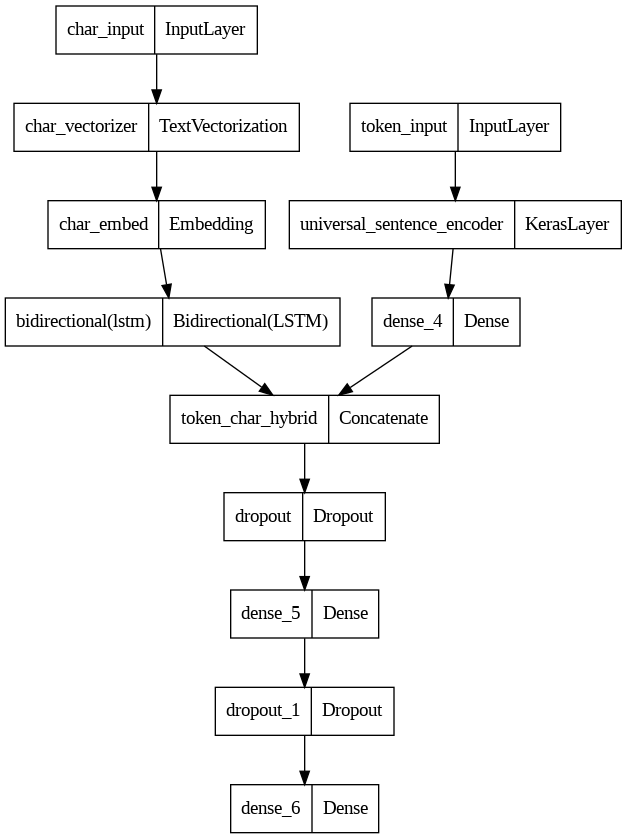

In [ ]:
# plot hybrid token and character model
from tensorflow.keras.utils import plot_model
plot_model(model_4)

Now that's a good looking model. Let's compile it just as we have the rest of our models.

> 🔑 **Note:** Section 4.2 of [*Neural Networks for Joint Sentence Classification in Medical Paper Abstracts*](https://arxiv.org/pdf/1612.05251.pdf) mentions using the SGD (Stochastic Gradient Descent) optimizer, however, to stay consistent with our other models, we're going to use the Adam optimizer. As an exercise, you could try using the [`tf.keras.optimizers.SGD`](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/SGD) instead of [`tf.keras.optimizers.Adam`](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam) and compare the results.

In [ ]:
# compile token char model
model_4.compile(loss='categorical_crossentropy',
                optimizer='adam',
                metrics=['accuracy'])

And again, to keep our experiments fast, we'll fit our token-character hybrid model on 10% of the training and validate on 10% of validation batches. However, the difference with this model is that it requires two inputs, token-level sequences, and character-level sequences.

We can do this by creating a `tf.data.Dataset` with a tuple as it's first input, for example:
* `((token_data, char_data), (label))`

Let's see it in action.

**Combining token and character data into a `tf.data` dataset**

In [ ]:
# combine chars and tokens into a dataset
train_char_token_data = tf.data.Dataset.from_tensor_slices((train_sentences, train_chars)) # make data
train_char_token_labels = tf.data.Dataset.from_tensor_slices(train_labels_one_hot) # make labels
train_char_token_dataset = tf.data.Dataset.zip((train_char_token_data, train_char_token_labels)) # combine data and labels

# Prefetch and batch train data
train_char_token_dataset = train_char_token_dataset.batch(32).prefetch(tf.data.AUTOTUNE)

# repeat same steps with validation data
val_char_token_data = tf.data.Dataset.from_tensor_slices((val_sentences, val_chars))
val_char_token_labels = tf.data.Dataset.from_tensor_slices(val_labels_one_hot)
val_char_token_dataset = tf.data.Dataset.zip((val_char_token_data, val_char_token_labels))

val_char_token_dataset = val_char_token_dataset.batch(32).prefetch(tf.data.AUTOTUNE)

In [ ]:
# check out training char and token embedding dataset
train_char_token_dataset, val_char_token_dataset

(<_PrefetchDataset element_spec=((TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None)), TensorSpec(shape=(None, 5), dtype=tf.float64, name=None))>,
 <_PrefetchDataset element_spec=((TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None)), TensorSpec(shape=(None, 5), dtype=tf.float64, name=None))>)

**Fitting a model on token and character-level sequences**

In [ ]:
# fit the model on tokens and chars
model_4_history = model_4.fit(train_char_token_dataset,
                              steps_per_epoch=int(0.1 * len(train_char_token_dataset)),
                              epochs=3,
                              validation_data=val_char_token_dataset,
                              validation_steps=int(0.1 * len(val_char_token_dataset)))

Epoch 1/3
562/562 [==============================] - 30s 43ms/step - loss: 0.9701 - accuracy: 0.6157 - val_loss: 0.7852 - val_accuracy: 0.6932
Epoch 2/3
562/562 [==============================] - 21s 37ms/step - loss: 0.7956 - accuracy: 0.6895 - val_loss: 0.7151 - val_accuracy: 0.7287
Epoch 3/3
562/562 [==============================] - 24s 42ms/step - loss: 0.7693 - accuracy: 0.7051 - val_loss: 0.6879 - val_accuracy: 0.7424


Nice! Our token-character hybrid model has come to life!

To make predictions with it, since it takes multiple inputs, we can pass the `predict()` method a tuple of token-level sequences and character-level sequences.

We can then evaluate the predictions as we've done before.

In [ ]:
# make predictions using the token-character model hybrid
model_4_pred_probs = model_4.predict(val_char_token_dataset)
model_4_pred_probs

945/945 [==============================] - 20s 20ms/step


array([[4.3441254e-01, 3.4797046e-01, 5.0080251e-03, 2.0504847e-01,
        7.5604212e-03],
       [3.1666672e-01, 5.1441437e-01, 3.6301906e-03, 1.6220531e-01,
        3.0834663e-03],
       [2.6303303e-01, 1.1671013e-01, 4.2195756e-02, 5.4205090e-01,
        3.6010247e-02],
       ...,
       [4.8561330e-04, 7.3047015e-03, 6.6068999e-02, 1.8612176e-04,
        9.2595458e-01],
       [1.2888229e-02, 8.4831387e-02, 2.5132191e-01, 5.5260384e-03,
        6.4543241e-01],
       [1.9532754e-01, 4.0705708e-01, 3.1887400e-01, 2.3323838e-02,
        5.5417474e-02]], dtype=float32)

In [ ]:
# turn prediction probabilities in to prediction classes
model_4_preds = tf.argmax(model_4_pred_probs, axis=1)
model_4_preds

<tf.Tensor: shape=(30212,), dtype=int64, numpy=array([0, 1, 3, ..., 4, 4, 1])>

In [ ]:
# get results of token-char hybrid model
model_4_results = calculate_results(y_true=val_labels_encoded,
                                    y_pred=model_4_preds)
model_4_results

{'accuracy': 73.47742618826956,
 'precision': 0.7346182206903871,
 'recall': 0.7347742618826956,
 'f1': 0.7311011567951835}

## Model 5: Transfer Learning with pretrained token embeddings + character embeddings + positional embeddings

It seems like combining token embeddings and characters embeddings gave our model a little performance boost.

But there's one more piece of the puzzle we can add in.

What if we engineered our own features into the model?

Meaning, what if we took our own knowledge about the data and encoded it in a numerical way to give our model more information about our samples?

The process of applying your own knowledge to build features as input to a model is called **feature engineering**.

Can you think of something important about the sequences we're trying to classify?

If you were to look at an abstract, would you expect the sentences to appear in order? Or does it make sense if they were to appear sequentially? For example, sequences labelled as `CONCLUSIONS` at the beginning and sequences labelled as `OBJECTIVE` at the end?

Abstracts typically in a sequential order, such as:
* `OBJECTIVE`...
* `METHODS`...
* `METHODS`...
* `METHODS`...
* `RESULTS`...
* `CONCLUSIONS`...

Or
* `BACKGROUND`...
* `OBJECTIVE`...
* `METHODS`...
* `METHODS`...
* `RESULTS`...
* `RESULTS`...
* `CONCLUSIONS`...
* `CONCLUSIONS`...

Ofcourse, we can't engineer sequences labels themselve into the training data (we don't have these at test time), but we can encode the order of a set of sequences in an abstract.

For example,
* `Sentence 1 of 10`...
* `Sentence 2 of 10`...
* `Sentence 3 of 10`...
* `Sentence 4 of 10`...
* ...

You might've noticed this when we created our `preprocess_text_with_line_numbers()` function. When we read in a text file of abstracts, we counted the number of lines in an abstract as well as the number of each line itself.

Doing this lead to the `"line_number"` and `"total_lines"` columns of our DataFrames.

In [ ]:
# Inspect training dataframe
train_df.head()

,target,text,line_number,total_lines
0,OBJECTIVE,to investigate the efficacy of @ weeks of dail...,0,11
1,METHODS,a total of @ patients with primary knee oa wer...,1,11
2,METHODS,outcome measures included pain reduction and i...,2,11
3,METHODS,pain was assessed using the visual analog pain...,3,11
4,METHODS,secondary outcome measures included the wester...,4,11


The `"line_number"` and `"total_lines"` columns are features which didn't necessarily come with the training data but can be passed to our model as a **positional embedding**. In other words, the positional embedding is where the sentence appears in an abstract.

We can use these featires because they will be available at test time.

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/09-engineered-features-at-test-time.png)

*Since abstracts typically have a sequential order about them (for example, background, objective, methods, results, conclusion). It makes sense to add the line number of where a particular sentece occurs to our model. The beautiful thing is, these features will be available at test time (we can just count the number of sentences in an abstract and the number of each one).*

Meaning, if we were to predict the labels of sequences in an abstract our model has had never seen, we could count the number of lines and then track the position of each individual line and pass it to our model.

> 🛠️ **Exercise:** Another way of creating our positional embedding feature would be to combine the `"lne_number"` and `"total_lines"` columns into one, for example a `"line_position"` column may contain values like `1_of_11`, `2_of_11`, etc. Where `1_of_11` would be the first line in an abstract 11 sentences long. After going through the following steps, you might want to revisit this positional embedding stage and see how a combined column of `"line_position"` goes against two separate columns.

**Create positional embeddings**

Okay, enough talk about positional embeddings, let's create them.

Since our `"line_number"` and `"total_line"` columns are already numerical we could pass them as they are to our model.

But to avoid our model thinking a line the `"line_number"=5` is five times greater than a line with `"line_number"=1`, we'll use one-hot enoding to encode our `"line_number"` and `"total_lines"` features.

To do this, we can use the [`tf.one_hot`](https://www.tensorflow.org/api_docs/python/tf/one_hot) utility.

`tf.one_hot` returns a one-hot encoded tensor. It accepts an array (or tensor) as input and the `depth` paramter determines the dimension of the returned tensor.

To figure our what we should set the `depth` paramter to, let's investigate the distribution of the `"line_number"`, column.

> 🔑 **Note:** When it comes to one-hot encoding our features, Scikit-Learn's [`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) class is another viable option here.

In [ ]:
# how many different line numbers are there?
train_df['line_number'].value_counts()

,count
line_number,
0,15000
1,15000
2,15000
3,15000
4,14992
5,14949
6,14758
7,14279
8,13346


<Axes: ylabel='Frequency'>

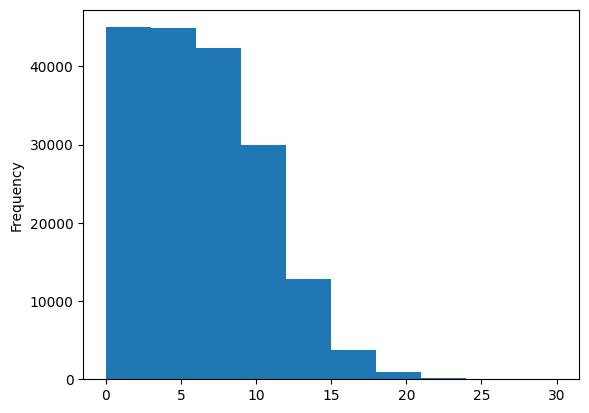

In [ ]:
# check the distribution of "line_number" column
train_df.line_number.plot.hist()

Looking at the distribution of the `"line_number"` column, it looks like the majority of lines have a position of 15 or less.

Knowing this, let's set the `depth` paramter of `tf.one_hot` to 15.

In [ ]:
# use tensorflow to create one-hot encoded tensors of our "line_number" column
train_line_numbers_one_hot = tf.one_hot(train_df['line_number'].to_numpy(), depth=15)
val_line_numbers_one_hot = tf.one_hot(val_df['line_number'].to_numpy(), depth=15)
test_line_numbers_one_hot = tf.one_hot(test_df['line_number'].to_numpy(), depth=15)

Setting the `depth` paramter of `tf.one_hot` to 15 means any sample with a `"line_number"` value of iver 15 gets set to a tensor of all 0's, where as any sample with a `"line_number"` of under 15 gets turned into a tensor of all 0's but with a 1 at the index equal to the `"line_number"` value.

> 🔑 **Note:** We could create a one-hot tensor which has room for all of the potential values of `"line_number"` (`depth=30`), however, this would end up in a tneosr of doouble the size of our current one (`depth=15`) where the vast majority of values are 0. Plus, only ~2,000/180,000 samples have a `"line_number"` value of over 15. So we would not be gaining much information about our data for doubline our feature space. This kind of problem is called the **curse of dimensionality**. However, since we're working with deep model, it might be worth trying to throw as much information at the model as possible and seeing what happens. I'll leave exploring values of the `depth` parameter as an extension.

In [ ]:
# check one-hot encoded "line_number" feature samples
train_line_numbers_one_hot.shape, train_line_numbers_one_hot[:20]

(TensorShape([180040, 15]),
 <tf.Tensor: shape=(20, 15), dtype=float32, numpy=
 array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0.

We can do the same as we've done for our `"line_number"` column with the `"total_lines"` column. First, let's find an appropriate value for the `depth` paramter of `tf.one_hot`.

In [ ]:
# how many different numbers of lines are there?
train_df['total_lines'].value_counts()

,count
total_lines,
11,24468
10,23639
12,22113
9,19400
13,18438
14,14610
8,12285
15,10768
7,7464


<Axes: ylabel='Frequency'>

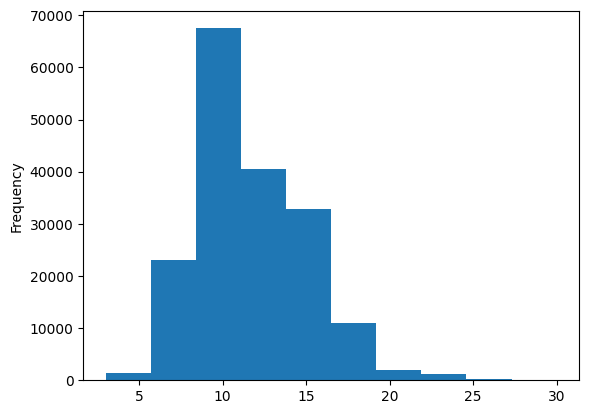

In [ ]:
# check the distribution of total lines
train_df.total_lines.plot.hist()

Looking at the distribution of our `"total_lines"` column, a value of 20 looks like it covers the majority of samples. We can confirm this with [`np.percentile()`](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html).

In [ ]:
# check the coverage of a "total_lines" value of 20
np.percentile(train_df.total_lines, 98) # a value of 20 covers 98% of samples

np.float64(20.0)

Beautiful! Plenty of coverage. Let's one-hot encode our `"total_lines"` column just as we did our `"line_number"` column

In [ ]:
# use tensorflow to create one-hot encoded tensors of our "total_lines" column
train_total_lines_one_hot = tf.one_hot(train_df['total_lines'].to_numpy(), depth=20)
val_total_lines_one_hot = tf.one_hot(val_df['total_lines'].to_numpy(), depth=20)
test_total_lines_one_hot = tf.one_hot(test_df['total_lines'].to_numpy(), depth=20)

# check shape and samples of total line one-hot tensor
train_total_lines_one_hot.shape, train_total_lines_one_hot[:10]

(TensorShape([180040, 20]),
 <tf.Tensor: shape=(10, 20), dtype=float32, numpy=
 array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0

## Building a tribrid embedding model

Woohoo! Positional embedding tensors ready.

It's time to build the biggest model we've built yet. One which icorporates token embeddings, character embeddings and our newly created posiitonal embeddings.

We'll be venturing into uncovered territory but there will be nothing here you haven't practiced before.

More specifically we're going to go through the following steps:
1. Create a token-level model (similar to `model_1`)

2. Create a character-level model (similar to `model_3` wihth a slight modification to reflect the paper).

3. Create a `"line_number"` model (takes in one-hot encoded `"line_number"`tensor and passes it through a non-linear layer).

4. Create a `"total_lines"` model (takes in one-hot encoded `"total_lines"` tensor and passes it through a non-linear layer).

5. Combine (using [`layers.Concatenate`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Concatenate)) the outputs of 1 and 2 into a token-character hybrid embedding and pass it series if output to Figure 1 and section 4.2 of [*Neural Networks for Joint Sentence Classification in Medical Paper Abstracts*](https://arxiv.org/pdf/1612.05251.pdf).

6. Combine (using [`layers.Concatenate`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Concatenate)) the outputs of 3, 4 and 5 into a token-character-positional tribrid embedding.

7. Create an output layer to accept the tribrid embedding and output predicted label probabilties.

8. Combine the inputs of 1, 2, 3, 4 and outputs of 7 into a [`tf.keras.Model`](https://www.tensorflow.org/api_docs/python/tf/keras/Model).

Woah! That's alot... but nothing we're not capable of. Let's code it.

In [ ]:
# 1. Token inputs
token_inputs = layers.Input(shape=[], dtype='string', name='token_inputs')
token_embeddings = tf_hub_embedding_layer(token_inputs)
token_outputs = layers.Dense(128, activation='relu')(token_embeddings)
token_model = tf.keras.Model(inputs=token_inputs,
                             outputs=token_outputs)

# 2. Char inputs
char_inputs = layers.Input(shape=(1,), dtype='string', name='char_inputs')
char_vectors = char_vectorizer(char_inputs)
char_embeddings = char_embed(char_vectors)
char_bi_lstm = layers.Bidirectional(layers.LSTM(32))(char_embeddings)
char_model = tf.keras.Model(inputs=char_inputs,
                            outputs=char_bi_lstm)

# 3. Line numbers inputs
line_number_inputs = layers.Input(shape=(15,), dtype=tf.int32, name='line_number_input')
x = layers.Dense(32, activation='relu')(line_number_inputs)
line_number_model = tf.keras.Model(inputs=line_number_inputs,
                                   outputs=x)

# 4. Total lines inputs
total_lines_inputs = layers.Input(shape=(20,), dtype=tf.int32, name='total_lines_input')
y = layers.Dense(32, activation='relu')(total_lines_inputs)
total_line_model = tf.keras.Model(inputs=total_lines_inputs,
                                  outputs=y)

# 5. Combine a token and char embedding into a hybrid embedding
combined_embeddings = layers.Concatenate(name='tokne_char_hybrid_embedding')([token_model.output,
                                                                              char_model.output])
z = layers.Dense(256, activation='relu')(combined_embeddings)
z = layers.Dropout(0.5)(z)

# 6. Combine positional embeddings with combined token and char embeddings into a tribrid embedding
z = layers.Concatenate(name='token_char_positional_embedding')([line_number_model.output,
                                                                total_line_model.output,
                                                                z])

# 7. Create output layer
output_layer = layers.Dense(5, activation='softmax', name='output_layer')(z)

# 8. Put together model
model_5 = tf.keras.Model(inputs=[line_number_model.input,
                                 total_line_model.input,
                                 token_model.input,
                                 char_model.input],
                         outputs=output_layer)

There's a lot going on here... let's visualize what's happening with a summary by plotting our model.

In [ ]:
# get a summary of our token, char and positional embedding model
model_5.summary()

Model: "model_8"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 char_inputs (InputLayer)    [(None, 1)]                  0         []                            
                                                                                                  
 token_inputs (InputLayer)   [(None,)]                    0         []                            
                                                                                                  
 char_vectorizer (TextVecto  (None, 290)                  0         ['char_inputs[0][0]']         
 rization)                                                                                        
                                                                                                  
 universal_sentence_encoder  (None, 512)                  2567978   ['token_inputs[0][0]']  

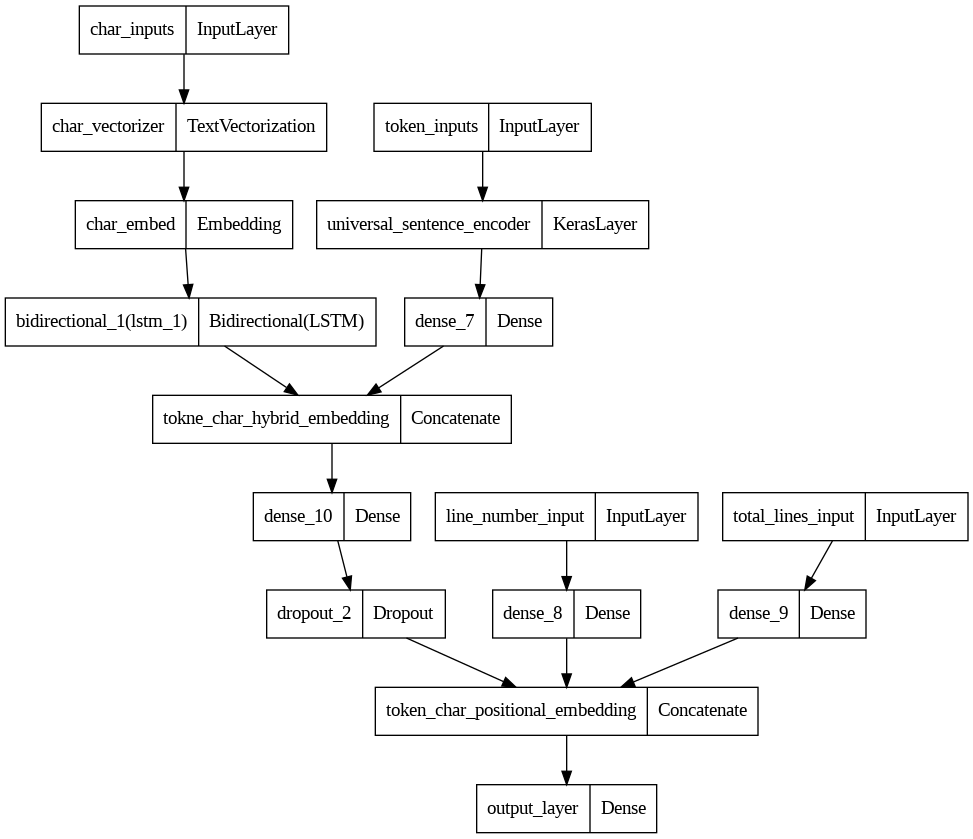

In [ ]:
# plot the token, char and positional embedding model
from tensorflow.keras.utils import plot_model
plot_model(model_5)

Visualizing the model makes it much easier to understant.

Essentially what we're doing is trying to encode as much information about our sequences as possible into various embeddings (the inputs to our model) so our model has the best chance to figure out what label belongs to a sequence (the outputs of our model).

You'll notice our model is looking very similar to the model shown in Figure 1 of [*Neural Networks for Joint Sentence Classification in Medical Paper Abstracts*](https://arxiv.org/pdf/1612.05251.pdf). However, a few differences still remain:
* We're using pretrained TensorFlow Hub token embeddings instead of GloVe embeddings.


* We're using a Dense layer on top of our token-character hybrid embeddings instead of a bi-LSTM layer.

* Section 3.1.3 of the paper mentions a label sequence optimization layer (which helps make sure sequence labels come out in a respectable order) but it isn't shown in Figure 1. To makeup for the lack of this layer in our model we've created the positional embedding layers.

* Section 4.2 of the paper mentions the token and character embeddings are updated during training, our pretrained TensorFlow Hub embeddings remain frozen.

* The paper uses the [`SGD`](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/SGD) optimizer, we're going to stick [`Adam`](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam).

All of the differences above are potential extensional of this project.

In [ ]:
# Check which layers of our model are trainable
for layer in model_5.layers:
  print(layer, layer.trainable)

<tf_keras.src.engine.input_layer.InputLayer object at 0x7f994c329160> True
<tf_keras.src.engine.input_layer.InputLayer object at 0x7f99c3c240e0> True
<tf_keras.src.layers.preprocessing.text_vectorization.TextVectorization object at 0x7f9944190aa0> True
<tensorflow_hub.keras_layer.KerasLayer object at 0x7f9a581448f0> False
<tf_keras.src.layers.core.embedding.Embedding object at 0x7f9944180da0> True
<tf_keras.src.layers.core.dense.Dense object at 0x7f9a78f8acc0> True
<tf_keras.src.layers.rnn.bidirectional.Bidirectional object at 0x7f99c3c19a90> True
<tf_keras.src.layers.merging.concatenate.Concatenate object at 0x7f99c3b0d100> True
<tf_keras.src.engine.input_layer.InputLayer object at 0x7f994414e2d0> True
<tf_keras.src.engine.input_layer.InputLayer object at 0x7f99441808c0> True
<tf_keras.src.layers.core.dense.Dense object at 0x7f99c3b0eb40> True
<tf_keras.src.layers.core.dense.Dense object at 0x7f99d7271d60> True
<tf_keras.src.layers.core.dense.Dense object at 0x7f99c3c19910> True
<tf_k

Now our model is constructed, let's compile it.

This time, we're going to introduce a new paramter to our loss function called `label_smoothing`. Label Smoothing helps to regularize our model (prevent overfitting) by making sure it doesn't get too focused on applying one particular label to a sample.

For example, instead of having an output prediction of
* `[0.0, 0.0, 1.0, 0.0, 0.0]` for a sample (the model is very confident correct label is index 2).

It's predictions will get smoothed to be something like:
* `[0.01, 0.01, 0.096, 0.01, 0.01]` giving a small activation to each of the other labels, in turn, hopefully improving generalization.

> 📖 **Resource:** For more on label smoothing, see the great blog post by PyImageSearch, [*Label smoothing with Keras, TensorFlow and Deep Learning*](https://www.pyimagesearch.com/2019/12/30/label-smoothing-with-keras-tensorflow-and-deep-learning/).

In [ ]:
# compile token, char, positional embedding model
model_5.compile(loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2), # add label smoothing (examples which are really confident get smoothed a little)
                optimizer='adam',
                metrics=['accuracy'])

**Create tribrid embedding datasets and fit a tribrid model**

Model Completed!

Again, to keep our experiments swift, let's fit on 20,000 samples for 3 epochs.

This time our model requires four feature inputs:
1. Train line numbers one-hot tensor (`train_line_numbers_one_hot`)

2. Train total lines one-hot tensor (`train_total_lines_one_hot`)

3. Token-level sequences tensor (`train_sentences`)

3. Char-level sequences tensor (`train_chars`)

We can pass these as tuples to our `tf.data.Dataset.from_tensor_slices()` method to create appropriately shaped and batched `PrefetchedDataset`'s.

In [ ]:
# Create training and validation datasets (all four kinds of inputs)
train_pos_char_token_data = tf.data.Dataset.from_tensor_slices((train_line_numbers_one_hot, # line numbers
                                                                train_total_lines_one_hot, # total lines
                                                                train_sentences, # train tokens
                                                                train_chars)) # train chars
train_pos_char_token_labels = tf.data.Dataset.from_tensor_slices(train_labels_one_hot) # train labels
train_pos_char_token_dataset = tf.data.Dataset.zip((train_pos_char_token_data,
                                                    train_pos_char_token_labels)) # combine data and labels
train_pos_char_token_dataset = train_pos_char_token_dataset.batch(32).prefetch(tf.data.AUTOTUNE) # turn into batches and prefetch appropriately

# validation dataset
val_pos_char_token_data = tf.data.Dataset.from_tensor_slices((val_line_numbers_one_hot,
                                                              val_total_lines_one_hot,
                                                              val_sentences,
                                                              val_chars))
val_pos_char_token_labels = tf.data.Dataset.from_tensor_slices(val_labels_one_hot)
val_pos_char_token_dataset = tf.data.Dataset.zip((val_pos_char_token_data,
                                                  val_pos_char_token_labels))
val_pos_char_token_dataset = val_pos_char_token_dataset.batch(32).prefetch(tf.data.AUTOTUNE) # turn into batches and prefetch appropriately

# check input shape
train_pos_char_token_dataset, val_pos_char_token_dataset

(<_PrefetchDataset element_spec=((TensorSpec(shape=(None, 15), dtype=tf.float32, name=None), TensorSpec(shape=(None, 20), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None)), TensorSpec(shape=(None, 5), dtype=tf.float64, name=None))>,
 <_PrefetchDataset element_spec=((TensorSpec(shape=(None, 15), dtype=tf.float32, name=None), TensorSpec(shape=(None, 20), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None)), TensorSpec(shape=(None, 5), dtype=tf.float64, name=None))>)

In [ ]:
# fit the token, char and positional embedding model
history_model_5 = model_5.fit(train_pos_char_token_dataset,
                              steps_per_epoch=int(0.1 * len(train_pos_char_token_dataset)),
                              epochs=3,
                              validation_data=val_pos_char_token_dataset,
                              validation_steps=int(0.1 * len(val_pos_char_token_dataset)))

Epoch 1/3
562/562 [==============================] - 30s 43ms/step - loss: 1.0926 - accuracy: 0.7260 - val_loss: 0.9808 - val_accuracy: 0.8088
Epoch 2/3
562/562 [==============================] - 21s 38ms/step - loss: 0.9655 - accuracy: 0.8158 - val_loss: 0.9478 - val_accuracy: 0.8301
Epoch 3/3
562/562 [==============================] - 23s 40ms/step - loss: 0.9473 - accuracy: 0.8273 - val_loss: 0.9384 - val_accuracy: 0.8285


In [ ]:
model_5.evaluate(val_pos_char_token_dataset)

945/945 [==============================] - 20s 21ms/step - loss: 0.9362 - accuracy: 0.8328


[0.9362407922744751, 0.8327816724777222]

Tribrid model trained! Time to make some predictions with it and evaluate them just as we've done before.

In [ ]:
# make predictions with token-char-positional hybrid model
model_5_pred_probs = model_5.predict(val_pos_char_token_dataset, verbose=1)
model_5_pred_probs

945/945 [==============================] - 22s 22ms/step


array([[0.48239505, 0.11745935, 0.01366615, 0.3653947 , 0.02108479],
       [0.54470354, 0.08208103, 0.04196871, 0.32071403, 0.0105327 ],
       [0.28299057, 0.1055183 , 0.09925117, 0.44361433, 0.06862568],
       ...,
       [0.03768469, 0.10058441, 0.03873038, 0.0316515 , 0.791349  ],
       [0.02975975, 0.339529  , 0.07446126, 0.02451269, 0.5317373 ],
       [0.2623449 , 0.5635688 , 0.07831779, 0.04628739, 0.04948116]],
      dtype=float32)

In [ ]:
# turn prediction probabilties into prediction classes
model_5_preds = tf.argmax(model_5_pred_probs, axis=1)
model_5_preds

<tf.Tensor: shape=(30212,), dtype=int64, numpy=array([0, 0, 3, ..., 4, 4, 1])>

In [ ]:
# calculate results of token-char-posiional hybrid model
model_5_results = calculate_results(y_true=val_labels_encoded,
                                    y_pred=model_5_preds)
model_5_results

{'accuracy': 83.27816761551702,
 'precision': 0.8317677427287499,
 'recall': 0.8327816761551702,
 'f1': 0.8319765983086386}

## Compare model results

Far out, we've come a long way. From baseline model to training a model containing three different kinds of embeddings.

Now it's time to compare each model's performance against each other.

We'll also be able to compare our model's to the [*PubMed 200k RCT: a Dataset for Sequential Sentence Classification in Medical Abstracts*](https://arxiv.org/pdf/1710.06071.pdf) paper.

Since all of our model results are in dictionaries, let's combine them into a pandas DataFrame to visualize them.

In [ ]:
# combine model results into a DataFrame
all_model_results = pd.DataFrame({'baseline': baseline_results,
                                  'custom_token_embed_conv1d': model_1_results,
                                  'pretrained_token_embed': model_2_results,
                                  'custom_char_embed_conv1d': model_3_results,
                                  'hybrid_char_token_embed': model_4_results,
                                  'tribrid_pos_char_token_embed': model_5_results,})
all_model_results = all_model_results.transpose()
all_model_results

,accuracy,precision,recall,f1
baseline,72.183238,0.718647,0.721832,0.698925
custom_token_embed_conv1d,78.707136,0.784310,0.787071,0.784687
pretrained_token_embed,71.517940,0.715538,0.715179,0.712271
custom_char_embed_conv1d,64.821925,0.642751,0.648219,0.636656
hybrid_char_token_embed,73.477426,0.734618,0.734774,0.731101
tribrid_pos_char_token_embed,83.278168,0.831768,0.832782,0.831977


In [ ]:
# reduce the accuracy to the same scale as other metrics
all_model_results['accuracy'] = all_model_results['accuracy']/100

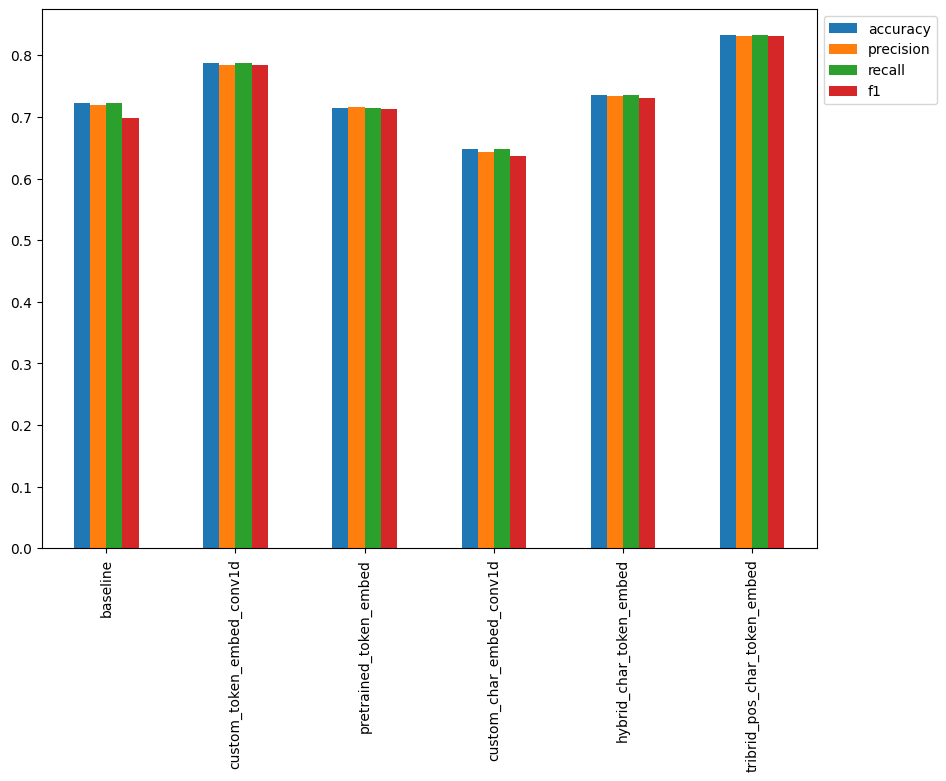

In [ ]:
# plot and compare all of he model results
all_model_results.plot(kind='bar', figsize=(10, 7)).legend(bbox_to_anchor=(1.0, 1.0))

Since the [*PubMed 200k RCT: a Dataset for Sequential Sentence Classification in Medical Abstracts*](https://arxiv.org/pdf/1710.06071.pdf) paper compares their tested models F1-scores on the test dataset, let's take a look at our model's F1-scores.

> 🔑 **Note:** We could've made these comparisons in TensorBoard using the [`TensorBoard`](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/TensorBoard) callback during training.

<Axes: >

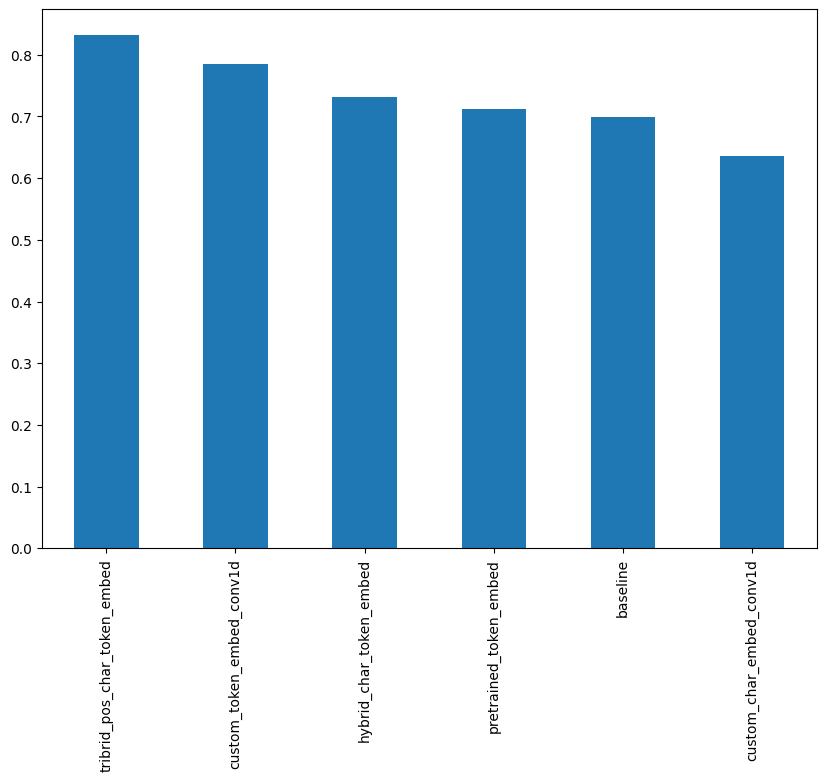

In [ ]:
# sort model results by f1-score
all_model_results.sort_values("f1", ascending=False)['f1'].plot(kind='bar', figsize=(10, 7))

Nice! Based on F1-scores, it looks like our tribrid embedding model performs the best by a fair margin.

Thoughm in comparision to the results reported in Table 3 of the [*PubMed 200k RCT: a Daataset for Sequential Sentence Classification in Medical Abstracts*](https://arxiv.org/pdf/1710.06071.pdf) paper, our model's F1-score is still underperforming (the authors model achieves an F1-score of 90.0 om the 20k RCT dataset versus our F1-score of ~82.6).

There are some things to note about this difference:
* Our models (with an exception for the baseline) have been trained on ~18,000 (10% of batches) samples of sequences and labels rather than the full ~180,000 in the 20k RCT dataset.

  * This is often the case in machine learning experiments though, make sure training works on a smaller number of samples, then upscale when needed (an extension to this project will be training a model on the full dataset).

* Our model's prediction performance levels have been evaluated on the validation dataset not the test dataset (we'll evaluate our best model on the test dataset shortly).

## Save and load best performing model

Since, we've been through a fair few experiments, it's a good idea to save our best performing model without having to retrain it.

We can save our best performing model by calling the [`save()`](https://www.tensorflow.org/guide/keras/save_and_serialize#the_short_answer_to_saving_loading) on it.

In [ ]:
# save best performing model to SavedModel format (default till Keras 2)
# model_5.save('skimlit_tribrid_model') # model will be saved to path specified by string

Optional: If you're using Google Colab, you might want to copy your saved model to Google Drive (or download it) for more permanent storage (Google Colab files disappear after you disconnect).

In [ ]:
# Example of copying saved model from Google Colab to Drive (requires Google Drive to be mounted)
!cp skimlit_tribrid_model -r /content/drive/MyDrive/models

cp: cannot stat 'skimlit_tribrid_model': No such file or directory


Like all good cooking shows, we've got a pretrained model (exactly the same kind of model we built `model_5` [saved and stored in Google Drive](https://drive.google.com/file/d/1quaeTYEzwolI0dXv98S9GEXOTVu9Akfk/view?usp=share_link) and [Google Storage](https://storage.googleapis.com/ztm_tf_course/skimlit/skimlit_tribrid_model.zip).

So to make sure we're all using the same model for evaluation, we'll download and load it in.

And when loading in our model, since it uses a couple of [custom objects](https://www.tensorflow.org/guide/keras/save_and_serialize#custom_objects) (our TensorFlow Hub layer and `TextVectorization` layer), we'll have to load it in by specifying them in the `custom_objects` parameter of [`tf.keras.models.load_model()`](https://www.tensorflow.org/api_docs/python/tf/keras/models/load_model).

In [ ]:
# Download pretrained model from Google Storage
!wget https://storage.googleapis.com/ztm_tf_course/skimlit/skimlit_tribrid_model.zip
!mkdir skimlit_gs_model
!unzip skimlit_tribrid_model.zip -d skimlit_gs_model

--2026-08-21 08:32:50--  https://storage.googleapis.com/ztm_tf_course/skimlit/skimlit_tribrid_model.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.68.207, 172.253.118.207, 142.251.10.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.68.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 962182847 (918M) [application/zip]
Saving to: ‘skimlit_tribrid_model.zip’

skimlit_tribrid_mod 100%[===================>] 917.61M  22.1MB/s    in 46s     

2026-08-21 08:33:37 (19.8 MB/s) - ‘skimlit_tribrid_model.zip’ saved [962182847/962182847]

Archive:  skimlit_tribrid_model.zip
   creating: skimlit_gs_model/skimlit_tribrid_model/
  inflating: skimlit_gs_model/skimlit_tribrid_model/keras_metadata.pb  
   creating: skimlit_gs_model/skimlit_tribrid_model/assets/
 extracting: skimlit_gs_model/skimlit_tribrid_model/fingerprint.pb  
   creating: skimlit_gs_model/skimlit_tribrid_model/variables/
  inflating: skimlit_gs_model/ski

In [ ]:
# Import TensorFlow model dependencies (if needed) - https://github.com/tensorflow/tensorflow/issues/38250
import tensorflow_hub as hub
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

model_path = 'skimlit_gs_model/skimlit_tribrid_model/'

# load downloaded model from Google storage
loaded_model = tf.keras.models.load_model(model_path)#,
                                          # Note: with TensorFlow 2.5+ if your SavedModel has a keras_metadata.pb file
                                          # (created when using model.save()), you shouldn't need the custom_objects
                                          # parameter. I'm leaving the code below here in case you do.
                                          # custom_objects={"TextVectorization": TextVectorization, # required for char vectorization
                                          #                 "KerasLayer": hub.KerasLayer}) # required for token embedding

## Make predictions and evaluate them against the truth labels

To makesure our model is saved and loaded correctly, let's make predictions with it, evaluate them and then compare them to prediction results we calculated earlier.

In [ ]:
# make predictions with the loaded model on the validation set
loaded_pred_probs = loaded_model.predict(val_pos_char_token_dataset, verbose=1)
loaded_preds = tf.argmax(loaded_pred_probs, axis=1)
loaded_preds[:10]

945/945 [==============================] - 21s 21ms/step


<tf.Tensor: shape=(10,), dtype=int64, numpy=array([0, 0, 3, 2, 2, 4, 4, 4, 4, 1])>

In [ ]:
# evaluate loaded model's predictions
loaded_model_results = calculate_results(val_labels_encoded,
                                         loaded_preds)
loaded_model_results

{'accuracy': 83.03323182841254,
 'precision': 0.8290556618130785,
 'recall': 0.8303323182841255,
 'f1': 0.8294263092000485}

Now let's compare our loaded model's predictions with the predicted results we obtained before saving our model.

In [ ]:
# compare loaded model results with original trained model results (should be quite close)
np.isclose(list(model_5_results.values()), list(loaded_model_results.values()), rtol=1e-02)

array([ True,  True,  True,  True])

It's worth noting that loading in a SavedModel unfreezes all layers (makes them all trainable). So, if you want to freeze any layers, you'll have to set their trainable attribute to `False`.

In [ ]:
# check loaded model summary (note: the number of trainable parameters)
loaded_model.summary()

Model: "model_8"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 char_inputs (InputLayer)    [(None, 1)]                  0         []                            
                                                                                                  
 token_inputs (InputLayer)   [(None,)]                    0         []                            
                                                                                                  
 char_vectorizer (TextVecto  (None, 290)                  0         ['char_inputs[0][0]']         
 rization)                                                                                        
                                                                                                  
 universal_sentence_encoder  (None, 512)                  2567978   ['token_inputs[0][0]']  

## Evaluate model on test dataset

To make our model's performance more compareable with the results represeted in Table 3 of the [*PubMed 200 RCT: a Dataset for Sequential Sentence Classifcation in Medical Abstracts*](https://arxiv.org/pdf/1710.06071.pdf) paper, let's make predictions on the test dataset and evaluate them.

In [ ]:
# create test dataset batch and prefetched
test_pos_char_token_data = tf.data.Dataset.from_tensor_slices((test_line_numbers_one_hot,
                                                               test_total_lines_one_hot,
                                                               test_sentences,
                                                               test_chars))
test_pos_char_token_labels = tf.data.Dataset.from_tensor_slices(test_labels_one_hot)
test_pos_char_token_dataset = tf.data.Dataset.zip((test_pos_char_token_data, test_pos_char_token_labels))
test_pos_char_token_dataset = test_pos_char_token_dataset.batch(32).prefetch(tf.data.AUTOTUNE)

# check shapes
test_pos_char_token_dataset

<_PrefetchDataset element_spec=((TensorSpec(shape=(None, 15), dtype=tf.float32, name=None), TensorSpec(shape=(None, 20), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None)), TensorSpec(shape=(None, 5), dtype=tf.float64, name=None))>

In [ ]:
# make predictions on the test dataset
test_pred_probs = loaded_model.predict(test_pos_char_token_dataset,
                                       verbose=1)
test_preds = tf.argmax(test_pred_probs, axis=1)
test_preds[:10]

942/942 [==============================] - 21s 22ms/step


<tf.Tensor: shape=(10,), dtype=int64, numpy=array([3, 3, 2, 2, 4, 4, 4, 1, 1, 0])>

In [ ]:
# evaluate loaded model on test predictions
loaded_model_test_results = calculate_results(test_labels_encoded,
                                              test_preds)
loaded_model_test_results

{'accuracy': 82.57176041148166,
 'precision': 0.8242659626849546,
 'recall': 0.8257176041148167,
 'f1': 0.8247141207593822}

It seems our best model (so far) still has some ways to go to matcht the performance of the results in the paper (their model get's 90.0 F1-score on the test dataset, where as ours gets ~82.1 F1-score).

However, as we discussed before our model has only been trained on 20,000 out of the total ~180,000 sequences in the RCT 20k dataset. We also haven't fine-tuned our pretrained embeddings (the paper fine tunes GloVe embeddings). So there are a couple of extensions we coult try to improve our results.

## Find most wrong

One of the best ways to navigate where your model is going wrong (or potentially where your data is wrong) is to visualize the 'most wrong' predictions.

The most wrong predictions are samples where the model has made a predictions with a high probability but has gotten in wrong (the model's prediction disagrees with the ground truth label).

Looking at the most wrong predictions can give us valuable information on how to improve further models or fix the labels in our data.

Let's write some code to help us visualize the most wrong predictions from the test dataset.

First we'll convert all our integer based test predictions into their string-based class names.

In [ ]:
%%time
# get list of class names of test predictions
test_pred_classes = [label_encoder.classes_[pred] for pred in test_preds]
test_pred_classes[:10]

CPU times: user 17.8 s, sys: 957 ms, total: 18.8 s
Wall time: 16.5 s


['OBJECTIVE',
 'OBJECTIVE',
 'METHODS',
 'METHODS',
 'RESULTS',
 'RESULTS',
 'RESULTS',
 'CONCLUSIONS',
 'CONCLUSIONS',
 'BACKGROUND']

Now we will enrich our test DataFrame with a few values:
* A `"prediction"` (string) column containing our model's predictions for a given sample.

* A `"pred_prob"` (float) column containing the model's maximum prediction probability for a given sample.

* A `"correct"` (bool) column indicate whether or not the model's prediction matches the sample's target label.

In [ ]:
# create predction enriched test columns
test_df['prediction'] = test_pred_classes # create column with test prediction class names
test_df['pred_prob'] = tf.reduce_max(test_pred_probs, axis=1).numpy() # get the maximum prediction probability
test_df['correct'] = test_df['prediction'] == test_df['target'] # create a binary column for whether the prediction is right or not
test_df.head(20)

,target,text,line_number,total_lines,prediction,pred_prob,correct
0,BACKGROUND,this study analyzed liver function abnormaliti...,0,8,OBJECTIVE,0.523885,False
1,RESULTS,a post hoc analysis was conducted with the use...,1,8,OBJECTIVE,0.351917,False
2,RESULTS,liver function tests ( lfts ) were measured at...,2,8,METHODS,0.802459,False
3,RESULTS,survival analyses were used to assess the asso...,3,8,METHODS,0.652782,False
4,RESULTS,the percentage of patients with abnormal lfts ...,4,8,RESULTS,0.665070,True
5,RESULTS,when mean hemodynamic profiles were compared i...,5,8,RESULTS,0.881815,True
6,RESULTS,multivariable analyses revealed that patients ...,6,8,RESULTS,0.529839,True
7,CONCLUSIONS,abnormal lfts are common in the adhf populatio...,7,8,CONCLUSIONS,0.568003,True
8,CONCLUSIONS,elevated meld-xi scores are associated with po...,8,8,CONCLUSIONS,0.461431,True
9,BACKGROUND,minimally invasive endovascular aneurysm repai...,0,12,BACKGROUND,0.537819,True


Looking good! Having our data like this, makes it very easy to manipulate and view in different ways.

How about we sert our DataFrame to find the samples with the highest `"pred_prob"` and where the prediction was wrong (`"correct" == False`)?

In [ ]:
# find top 100 most wrong samples (note: 100 is an arbitrary number, you could go through all of them if you want)
top_100_wrong = test_df[test_df['correct'] == False].sort_values('pred_prob', ascending=False)[:100]
top_100_wrong

,target,text,line_number,total_lines,prediction,pred_prob,correct
13874,CONCLUSIONS,symptom outcomes will be assessed and estimate...,4,6,METHODS,0.946719,False
8545,METHODS,pretest-posttest .,1,11,BACKGROUND,0.934974,False
16347,BACKGROUND,to evaluate the effects of the lactic acid bac...,0,12,OBJECTIVE,0.930986,False
2388,RESULTS,the primary endpoint is the cumulative three-y...,4,13,METHODS,0.928262,False
10452,BACKGROUND,to validate the association between accommodat...,0,10,OBJECTIVE,0.918880,False
...,...,...,...,...,...,...,...
12134,RESULTS,we conducted a population-based case-control s...,2,16,METHODS,0.840899,False
2605,RESULTS,"circulating epc ( cells positive for cd@ , cd@...",4,10,METHODS,0.840442,False
19223,METHODS,"of the @ dogs receiving placebo , @ ( @ % ) vo...",7,10,RESULTS,0.840310,False
20003,CONCLUSIONS,most subjects with bronchospasm responded to r...,9,11,RESULTS,0.839986,False


Great (or not so grest)! Now we have got a subset of our model's most wrong predictions, let's write some code to visualize them.

In [ ]:
# Investigate top wrong preds
for row in top_100_wrong[0:10].itertuples(): # adjust indexes to view different samples
  _, target, text, line_number, total_lines, prediction, pred_prob, _ = row
  print(f"Target: {target}, Pred: {prediction}, Prob: {pred_prob}, Line number: {line_number}, Total lines: {total_lines}\n")
  print(f"Text:\n{text}\n")
  print("-----\n")

Target: CONCLUSIONS, Pred: METHODS, Prob: 0.9467191696166992, Line number: 4, Total lines: 6

Text:
symptom outcomes will be assessed and estimates of cost-effectiveness made .

-----

Target: METHODS, Pred: BACKGROUND, Prob: 0.9349740743637085, Line number: 1, Total lines: 11

Text:
pretest-posttest .

-----

Target: BACKGROUND, Pred: OBJECTIVE, Prob: 0.9309859275817871, Line number: 0, Total lines: 12

Text:
to evaluate the effects of the lactic acid bacterium lactobacillus salivarius on caries risk factors .

-----

Target: RESULTS, Pred: METHODS, Prob: 0.9282616972923279, Line number: 4, Total lines: 13

Text:
the primary endpoint is the cumulative three-year hiv incidence .

-----

Target: BACKGROUND, Pred: OBJECTIVE, Prob: 0.918879508972168, Line number: 0, Total lines: 10

Text:
to validate the association between accommodation and visual asthenopia by measuring objective accommodative amplitude with the optical quality analysis system ( oqas , visiometrics , terrassa , spain ) 

What do you notice about the most wrong predictions? Does the model make silly mistakes? Or are some of the labels incorrect/ambiguous (e.g. a line in an abstract could potentially be labelled `OBJECTIVE` or `BACKGROUND` and make sense).

A next step here would be if there are a fair few samples with inconsistent labels, you could go through your training dataset, update labels and then retrain a model. The process of using a model to help improve/investigate your dataset's labels is often referred to as **active learning**.

## Make example predictions

Okay, we've made some predictions on the test dataset, now's time to really test our model out.

To do so, we're going to get some data from the wild and see how our model performs.

In other words, we're going to find an RCT abstract from PubMed, preprocess the test so it works with our model, then pass each sequence in the wild abstract through our model to see what label it predicts.

For an appropriate sample, we'll need to search PubMed for RCTs (randomized controlled trials) without abstracts which have been split up (on exploring PubMed you'll notice many of the abstracts are already performatted into separate sections, this helps dramatically with readability).

Goign throough various PubMed studies, I managed to find the following unstructured abstract from [*RCT of a manualized social treatment for high-functioning autism spectrum disorders*](https://pubmed.ncbi.nlm.nih.gov/20232240/):

>This RCT examined the efficacy of a manualized social intervention for children with HFASDs. Participants were randomly assigned to treatment or wait-list conditions. Treatment included instruction and therapeutic activities targeting social skills, face-emotion recognition, interest expansion, and interpretation of non-literal language. A response-cost program was applied to reduce problem behaviors and foster skills acquisition. Significant treatment effects were found for five of seven primary outcome measures (parent ratings and direct child measures). Secondary measures based on staff ratings (treatment group only) corroborated gains reported by parents. High levels of parent, child and staff satisfaction were reported, along with high levels of treatment fidelity. Standardized effect size estimates were primarily in the medium and large ranges and favored the treatment group.

Looking at the large chunk of text can seem quite intimidating. Now imagine you're a medical researcher trying to skim through the literature to find a study relevant to your work.

Sounds like quite the challenge right?

Enter SkimLit 🤓🔥!

Let's see what our best model so far (`model_5`) makes of the above extract.

But wait...

As you might've guessed the above abstract hasn't been formatted in the same structure as the data our model has been trained on. Therefore, before we can make a prediction on it, we need to preprocess it just as we have our other sequences.

More specifically, for each abstract, we'll need to:
1. Split it into-sentences (lines).
2. Split it into characters.
3. Find the number of each line
4. Find the total number of lines.

Starting with number 1, there are a couple of ways to split our abstracts into actual sentences. A simple one would be to use Python's inbuilt `split()` string method, splitting the abstract wherever a fullstop appears. However, can you imagine where this might go wrong?

Another more advanced option would be to leverage [spaCy's](https://spacy.io/) (a very powerful NLP library) [`sentencizer`](https://spacy.io/usage/linguistic-features#sbd) class. Which is an easy to use sentence splitter based on spaCy's English Language model.

I've prepared some abstracts from PubMed RCT papers to try our model on, we can download them [from GitHub](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/skimlit_example_abstracts.json).

In [ ]:
import json
# Download and open example abstracts (copy and pasted from PubMed)
!wget https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/skimlit_example_abstracts.json

with open("skimlit_example_abstracts.json", "r") as f:
  example_abstracts = json.load(f)

example_abstracts

--2026-09-02 10:50:53--  https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/skimlit_example_abstracts.json
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6737 (6.6K) [text/plain]
Saving to: ‘skimlit_example_abstracts.json’

skimlit_example_abs 100%[===================>]   6.58K  --.-KB/s    in 0s      

2026-09-02 10:50:54 (69.7 MB/s) - ‘skimlit_example_abstracts.json’ saved [6737/6737]



[{'abstract': 'This RCT examined the efficacy of a manualized social intervention for children with HFASDs. Participants were randomly assigned to treatment or wait-list conditions. Treatment included instruction and therapeutic activities targeting social skills, face-emotion recognition, interest expansion, and interpretation of non-literal language. A response-cost program was applied to reduce problem behaviors and foster skills acquisition. Significant treatment effects were found for five of seven primary outcome measures (parent ratings and direct child measures). Secondary measures based on staff ratings (treatment group only) corroborated gains reported by parents. High levels of parent, child and staff satisfaction were reported, along with high levels of treatment fidelity. Standardized effect size estimates were primarily in the medium and large ranges and favored the treatment group.',
  'source': 'https://pubmed.ncbi.nlm.nih.gov/20232240/',
  'details': 'RCT of a manualiz

In [ ]:
import pandas as pd
# see what our example abstracts look like
abstracts = pd.DataFrame(example_abstracts)
abstracts

,abstract,source,details
0,This RCT examined the efficacy of a manualized...,https://pubmed.ncbi.nlm.nih.gov/20232240/,RCT of a manualized social treatment for high-...
1,Postpartum depression (PPD) is the most preval...,https://pubmed.ncbi.nlm.nih.gov/28012571/,Formatting removed (can be used to compare mod...
2,"Mental illness, including depression, anxiety ...",https://pubmed.ncbi.nlm.nih.gov/28942748/,Effect of nutrition on mental health
3,Hepatitis C virus (HCV) and alcoholic liver di...,https://pubmed.ncbi.nlm.nih.gov/22244707/,Baclofen promotes alcohol abstinence in alcoho...


Now We've downloaded some example abstracts, let's see how one of them goes with our trained model.

First, we'll need to parse it using spaCy to turn it from a big chunk of text into sentences.

In [ ]:
# Create sentencizer
from spacy.lang.en import English
nlp = English() # setup English sentence parser

sentencizer = nlp.add_pipe('sentencizer') # create sentence splitting pipeline object

# create 'doc' of parsed sequences, change index for a different abstract
doc = nlp(example_abstracts[0]['abstract'])
abstract_lines = [str(sent) for sent in list(doc.sents)] # return detected sentences from doc in a string type (not spaCy token type)
abstract_lines

['This RCT examined the efficacy of a manualized social intervention for children with HFASDs.',
 'Participants were randomly assigned to treatment or wait-list conditions.',
 'Treatment included instruction and therapeutic activities targeting social skills, face-emotion recognition, interest expansion, and interpretation of non-literal language.',
 'A response-cost program was applied to reduce problem behaviors and foster skills acquisition.',
 'Significant treatment effects were found for five of seven primary outcome measures (parent ratings and direct child measures).',
 'Secondary measures based on staff ratings (treatment group only) corroborated gains reported by parents.',
 'High levels of parent, child and staff satisfaction were reported, along with high levels of treatment fidelity.',
 'Standardized effect size estimates were primarily in the medium and large ranges and favored the treatment group.']

Beautiful! It looks like spaCy has split the sentences in the abstract correctly. However, it shoudl be noted, there may be more complex abstracts which don't get split perfectly into separate sentences (such as the example in [*Baclofen promotes alchohol abstinence in alchohol dependent cirrhotic patients with hepititis C virus (HCV) infection*](https://pubmed.ncbi.nlm.nih.gov/22244707/)), in this case, more custom splitting teechniques would have to be investigated.

Now our abstract has been split into sentences, how about we write some code to count line numbers as well as total lines.

To do so, we can leverage some of the functionality of our `preprocess_text_with_line_numbers()` function.

In [ ]:
# get total number of lines
total_lines_in_sample = len(abstract_lines)

# go through each line in abstract and create a list of dictionaries containing features for each line
sample_lines = []
for i, line in enumerate(abstract_lines):
  sample_dict = {}
  sample_dict['text'] = str(line)
  sample_dict['line_number'] = i
  sample_dict['total_lines'] = total_lines_in_sample - 1
  sample_lines.append(sample_dict)

sample_lines

[{'text': 'This RCT examined the efficacy of a manualized social intervention for children with HFASDs.',
  'line_number': 0,
  'total_lines': 7},
 {'text': 'Participants were randomly assigned to treatment or wait-list conditions.',
  'line_number': 1,
  'total_lines': 7},
 {'text': 'Treatment included instruction and therapeutic activities targeting social skills, face-emotion recognition, interest expansion, and interpretation of non-literal language.',
  'line_number': 2,
  'total_lines': 7},
 {'text': 'A response-cost program was applied to reduce problem behaviors and foster skills acquisition.',
  'line_number': 3,
  'total_lines': 7},
 {'text': 'Significant treatment effects were found for five of seven primary outcome measures (parent ratings and direct child measures).',
  'line_number': 4,
  'total_lines': 7},
 {'text': 'Secondary measures based on staff ratings (treatment group only) corroborated gains reported by parents.',
  'line_number': 5,
  'total_lines': 7},
 {'text'

Now we've got `"line_number"` and `"total_lines"` values, we can one-hot encode them with `tf.one_hot` just like we did with our training dataset (using the same values for the `depth` parameter).

In [ ]:
# get all line_number values from sample abstract
test_abstract_line_numbers = [line['line_number'] for line in sample_lines]

# one hot encode to same depth as training data, so model accepts right input shape
test_abstract_line_numbers_one_hot = tf.one_hot(test_abstract_line_numbers, depth=15)
test_abstract_line_numbers_one_hot

<tf.Tensor: shape=(8, 15), dtype=float32, numpy=
array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.]],
      dtype=float32)>

In [ ]:
# get all total_lines values from sample abstract
test_abstract_total_lines = [line['total_lines'] for line in sample_lines]

# one-hot encode to same depth as training data, so model accepts right input shape
test_abstract_total_lines_one_hot = tf.one_hot(test_abstract_total_lines, depth=20)
test_abstract_total_lines_one_hot

<tf.Tensor: shape=(8, 20), dtype=float32, numpy=
array([[0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.]], dtype=float32)>

We can also use our `split_chars()` function to split our abstract lines into characters.

In [ ]:
# split abstract lines into characters
abstract_chars = [split_chars(sentence) for sentence in abstract_lines]
abstract_chars

['T h i s   R C T   e x a m i n e d   t h e   e f f i c a c y   o f   a   m a n u a l i z e d   s o c i a l   i n t e r v e n t i o n   f o r   c h i l d r e n   w i t h   H F A S D s .',
 'P a r t i c i p a n t s   w e r e   r a n d o m l y   a s s i g n e d   t o   t r e a t m e n t   o r   w a i t - l i s t   c o n d i t i o n s .',
 'T r e a t m e n t   i n c l u d e d   i n s t r u c t i o n   a n d   t h e r a p e u t i c   a c t i v i t i e s   t a r g e t i n g   s o c i a l   s k i l l s ,   f a c e - e m o t i o n   r e c o g n i t i o n ,   i n t e r e s t   e x p a n s i o n ,   a n d   i n t e r p r e t a t i o n   o f   n o n - l i t e r a l   l a n g u a g e .',
 'A   r e s p o n s e - c o s t   p r o g r a m   w a s   a p p l i e d   t o   r e d u c e   p r o b l e m   b e h a v i o r s   a n d   f o s t e r   s k i l l s   a c q u i s i t i o n .',
 'S i g n i f i c a n t   t r e a t m e n t   e f f e c t s   w e r e   f o u n d   f o r   f i v e   o f   s e v e n   p 

Alright, now we've preprocessed our wild RCT abstract into all of the same features our model was trained on, we can pass these features to our model and make sequence label predictions!

In [ ]:
# make predictions on sample abstract features
%%time
test_abstract_pred_probs = loaded_model.predict(x=(test_abstract_line_numbers_one_hot,
                                                   test_abstract_total_lines_one_hot,
                                                   tf.constant(abstract_lines),
                                                   tf.constant(abstract_chars)))
test_abstract_pred_probs

1/1 [==============================] - 2s 2s/step
CPU times: user 1.72 s, sys: 136 ms, total: 1.86 s
Wall time: 2.49 s


array([[0.2644824 , 0.1105424 , 0.01762424, 0.5750657 , 0.03228524],
       [0.06927066, 0.03808297, 0.7078093 , 0.09543166, 0.08940544],
       [0.13772689, 0.04937518, 0.546797  , 0.1634129 , 0.10268807],
       [0.09659056, 0.17111638, 0.52574396, 0.07601641, 0.13053276],
       [0.04459697, 0.08888113, 0.45675457, 0.04623033, 0.36353704],
       [0.03265214, 0.14626428, 0.517485  , 0.04088319, 0.2627154 ],
       [0.03290154, 0.17796211, 0.07166824, 0.02870874, 0.6887593 ],
       [0.01843721, 0.13495173, 0.32084194, 0.03389723, 0.49187192]],
      dtype=float32)

In [ ]:
# turn prediction probabilites into prediction calasses
test_abstract_preds = tf.argmax(test_abstract_pred_probs, axis=1)
test_abstract_preds

<tf.Tensor: shape=(8,), dtype=int64, numpy=array([3, 2, 2, 2, 2, 2, 4, 4])>

Now we've got the predicted sequence label for each line in our sample abstract, let's write some code to visualize each sentence with its predicted label.

In [ ]:
# turn prediction class integers into string class names
test_abstract_pred_classes = [label_encoder.classes_[i] for i in test_abstract_preds]
test_abstract_pred_classes

['OBJECTIVE',
 'METHODS',
 'METHODS',
 'METHODS',
 'METHODS',
 'METHODS',
 'RESULTS',
 'RESULTS']

In [ ]:
# visualize abstract lines and predicted sequence labels
for i, line in enumerate(abstract_lines):
  print(f"{test_abstract_pred_classes[i]}: {line}")

OBJECTIVE: This RCT examined the efficacy of a manualized social intervention for children with HFASDs.
METHODS: Participants were randomly assigned to treatment or wait-list conditions.
METHODS: Treatment included instruction and therapeutic activities targeting social skills, face-emotion recognition, interest expansion, and interpretation of non-literal language.
METHODS: A response-cost program was applied to reduce problem behaviors and foster skills acquisition.
METHODS: Significant treatment effects were found for five of seven primary outcome measures (parent ratings and direct child measures).
METHODS: Secondary measures based on staff ratings (treatment group only) corroborated gains reported by parents.
RESULTS: High levels of parent, child and staff satisfaction were reported, along with high levels of treatment fidelity.
RESULTS: Standardized effect size estimates were primarily in the medium and large ranges and favored the treatment group.


Nice! Isn't that much easier to read? I mean, it looks like our model's predictions could be improved, but how cool is that?

Imagine implementing our model to the backend of the PubMed website to format any unstructured RCT abstract on the site.

Or there could even be a browser extension, called "SkimLit" which would add structure (powered by our model) to any unstructured RCT abtract.

And if showed your medical researcher friend, and they thought the predictions weren't up to standard, there could be a button saying "is this label correct?... if not, what should it be?". That way the dataset, along with our model's future predictions, could be improved over time.

Of course, there are many more ways we could go to improve the model, the usuability, the preprocessing functionality (e.g. functionizing our sample abstract preprocessing pipeline) but I'll leave these for the exercises/extensions.

> 🤔 **Question:** How can we be sure the results of our test example from the wild are truly wild? Is there something we should check about the sample we're testing on?

# Structura project implementation

## Old architecture

In [ ]:
import tensorflow as tf
import pandas as pd

In [ ]:
class Keras2SavedModelWrapper(tf.keras.layers.Layer):
  """
  A custom layer to load a Keras 2 SavedModel and properly unpack
  dictionary inputs into the keyword arguments the graph expects.
  """
  def __init__(self, model_path, **kwargs):
    super().__init__(**kwargs)
    # load the raw saved model graph, explicitly placing on CPU
    with tf.device('/CPU:0'): # Ensure tf.saved_model.load happens on CPU
      self.loaded_model = tf.saved_model.load(model_path)
    self.serving_fn = self.loaded_model.signatures['serving_default']

  def call(self, inputs):
    # unpack the dictionary using ** so the graph
    # recives the exact keyword arguments it strictly requires.
    with tf.device('/CPU:0'): # Ensure the call operation also runs on CPU
      return self.serving_fn(**inputs)

In [ ]:
def load_model(model_path):
  """
  Loads in a saved TensorFlow model from a specified path.
  """
  # defining identical input tensors with matching shapes, dtypes and names
  line_number_input = tf.keras.layers.Input(shape=(15,), dtype=tf.int32, name='line_number_input')
  total_lines_input = tf.keras.layers.Input(shape=(20,), dtype=tf.int32, name='total_lines_input')
  token_inputs = tf.keras.layers.Input(shape=(), dtype=tf.string, name='token_inputs')
  char_inputs = tf.keras.layers.Input(shape=(1,), dtype=tf.string, name='char_inputs')

  # packaging my inputs into a directory matching my Keras 2 layer names
  # the tensorflow graph maps its execution endpoints via these names
  graph_inputs = {
      'line_number_input': line_number_input,
      'total_lines_input': total_lines_input,
      'token_inputs': token_inputs,
      'char_inputs': char_inputs
  }

  # loading the SavedModel directory as a functional block, ensuring all components are loaded to CPU
  with tf.device('/CPU:0'):
    tf_sm_layer = Keras2SavedModelWrapper(model_path)

  # extracting the output tensor from the graph by explicitly passing keyword arguments
  graph_outputs = tf_sm_layer(graph_inputs)

  final_predictions = graph_outputs['output_layer']

  # building the complete model
  model = tf.keras.Model(
      inputs=[line_number_input, total_lines_input, token_inputs, char_inputs],
      outputs=final_predictions
  )

  return model

In [ ]:
!cp -r /content/drive/MyDrive/models/skimlit_tribrid_model /content

In [ ]:
%%time

# Get a list of all physical GPUs
gpus = tf.config.list_physical_devices('GPU')

# If GPUs are available, disable them to force CPU usage
if gpus:
    try:
        tf.config.set_visible_devices([], 'GPU')
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(f"Visible GPUs after disabling: {logical_gpus}")
    except RuntimeError as e:
        # Visible devices must be set at program startup
        print(e)
else:
    print("No GPU devices found, defaulting to CPU.")

loaded_model = load_model('/content/skimlit_tribrid_model')
loaded_model

No GPU devices found, defaulting to CPU.
CPU times: user 9.72 s, sys: 3.92 s, total: 13.6 s
Wall time: 17.4 s


<Functional name=functional, built=True>

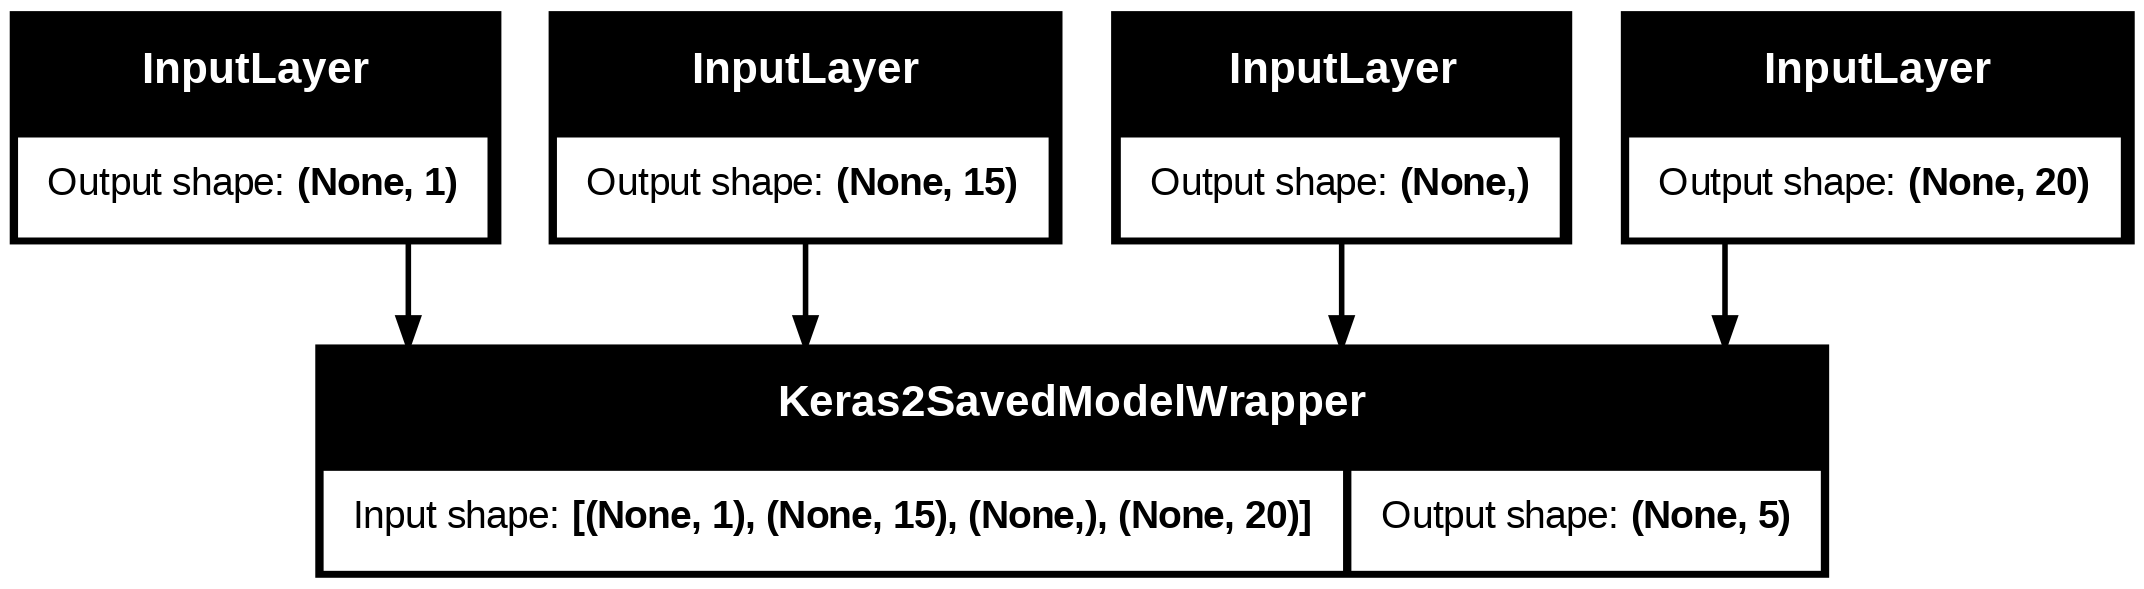

In [ ]:
tf.keras.utils.plot_model(loaded_model, show_shapes=True)

In [ ]:
loaded_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ char_inputs         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ line_number_input   │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_inputs        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ total_lines_input   │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ keras2_saved_model… │ (None, 5)         │          0 │ char_inputs[0][0… │
│ (Keras2SavedModelW… │                   │            │ line_number_inpu… │
│                     │                   │            │ token_inputs[0][… │
│                     │                   │            │ total_lines_inpu… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def split_chars(text):
  return " ".join(list(text))

In [ ]:
from spacy.lang.en import English

def preprocess_text(text):
  # -----------( SENTENCIZER )-----------
  nlp = English() # setup English sentence parser
  sentencizer = nlp.add_pipe('sentencizer') # create sentencizer splitting pipeline object

  # creating a 'doc' of parsed sequences
  doc = nlp(text)
  abstract_lines = [str(sent) for sent in list(doc.sents)] # return detected sentences from doc in a string type (not spaCy token type)

  # TOTAL NUMBER OF LINES
  total_lines_in_abstract = len(abstract_lines)

  # going through each line in abstract and creating a list of dictionaries containing features for each line
  lines = []
  for i, line in enumerate(abstract_lines):
    line_dict = {}
    line_dict['text'] = str(line)
    line_dict['line_number'] = i
    line_dict['total_lines'] = total_lines_in_abstract - 1
    lines.append(line_dict)

  # -----------( LINE NUMBERS AND TOTAL LINES )-----------
  # getting all line_number values from text abstract
  abstract_line_numbers = [line['line_number'] for line in lines]

  # one-hot encode to same depth as training data
  abstract_line_numbers_one_hot = tf.one_hot(abstract_line_numbers, depth=15)

  # getting all total_lines vales from text abstract
  abstract_total_lines = [line['total_lines'] for line in lines]

  # one-hot encode them to same depth as training data
  abstract_total_lines_one_hot = tf.one_hot(abstract_total_lines, depth=20)

  # -----------( SPLITTING INTO CHARACTERS )-----------
  # split abstract lines into characters
  abstract_chars = [split_chars(line) for line in abstract_lines]

  return abstract_line_numbers_one_hot, abstract_total_lines_one_hot, abstract_lines, abstract_chars

In [ ]:
%%time

test_abstract_line_numbers_one_hot, test_abstract_total_lines_one_hot, abstract_lines, abstract_chars = preprocess_text(example_abstracts[0]['abstract'])

with tf.device('/CPU:0'): # Explicitly run prediction on CPU
  test_abstract_model_pred_probs = loaded_model.predict(x=(test_abstract_line_numbers_one_hot,
                                                           test_abstract_total_lines_one_hot,
                                                           tf.constant(abstract_lines),
                                                           tf.constant(abstract_chars)))
test_abstract_model_pred_probs

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
CPU times: user 363 ms, sys: 3.77 ms, total: 367 ms
Wall time: 399 ms


array([[0.2815094 , 0.09579521, 0.01504179, 0.5806676 , 0.02698597],
       [0.07586037, 0.03160472, 0.6977856 , 0.10007522, 0.09467401],
       [0.13814154, 0.05567466, 0.5319083 , 0.18239197, 0.09188347],
       [0.0967809 , 0.16149607, 0.49703202, 0.08266992, 0.16202113],
       [0.05566771, 0.09497927, 0.4331363 , 0.05079339, 0.3654233 ],
       [0.03779025, 0.11535647, 0.5269998 , 0.04531605, 0.2745374 ],
       [0.03468331, 0.20740935, 0.07121984, 0.03016678, 0.6565207 ],
       [0.0197223 , 0.12475758, 0.25488058, 0.03461497, 0.56602454]],
      dtype=float32)

In [ ]:
def output_formatting(model_pred_probs, abstract_lines, class_names):

  # turning prediction probabilites into prediction classes
  abstract_preds = tf.argmax(model_pred_probs, axis=1)

  # turning prediction class integers into string class names
  abstract_pred_classes = [class_names[i] for i in abstract_preds]

  formatted_lines = []
  for i, line in enumerate(abstract_lines):
    formatted_line = {}
    formatted_line['label'] = abstract_pred_classes[i]
    formatted_line['text'] = line
    formatted_lines.append(formatted_line)

  return formatted_lines

In [ ]:
with open('class_names.txt', 'w') as f:
  f.write('\n'.join(class_names))

In [ ]:
# openning file and extracting names into a list
with open('class_names.txt', 'r') as f:
  class_names2 = f.read().splitlines()

print(class_names2)

['BACKGROUND', 'CONCLUSIONS', 'METHODS', 'OBJECTIVE', 'RESULTS']


In [ ]:
formatted_output = output_formatting(test_abstract_model_pred_probs, abstract_lines, class_names2)
formatted_output

[{'label': 'OBJECTIVE',
  'text': 'This RCT examined the efficacy of a manualized social intervention for children with HFASDs.'},
 {'label': 'METHODS',
  'text': 'Participants were randomly assigned to treatment or wait-list conditions.'},
 {'label': 'METHODS',
  'text': 'Treatment included instruction and therapeutic activities targeting social skills, face-emotion recognition, interest expansion, and interpretation of non-literal language.'},
 {'label': 'METHODS',
  'text': 'A response-cost program was applied to reduce problem behaviors and foster skills acquisition.'},
 {'label': 'METHODS',
  'text': 'Significant treatment effects were found for five of seven primary outcome measures (parent ratings and direct child measures).'},
 {'label': 'METHODS',
  'text': 'Secondary measures based on staff ratings (treatment group only) corroborated gains reported by parents.'},
 {'label': 'RESULTS',
  'text': 'High levels of parent, child and staff satisfaction were reported, along with hig

## Model Conversion and optimization

In [ ]:
import tensorflow as tf

saved_model_dir = '/content/skimlit_tribrid_model'
converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_dir)

# We removed converter.optimizations - this prevents FlexStringLower from crashing

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]

print("Starting conversion...")
tflite_model = converter.convert()

with open("skimlit_unquantized.tflite", "wb") as f:
    f.write(tflite_model)

Starting conversion...


In [ ]:
from pathlib import Path
def load_tflite_model():
  # CURR_DIR = Path(__file__).resolve().parent
  # model_path = str(CURR_DIR / "skimlit_unquantized.tflite")

  # initialize the interpreter
  interpreter = tf.lite.Interpreter(
      model_path='/content/skimlit_unquantized.tflite',
  )

  # allocate memory for the model's tensors
  interpreter.allocate_tensors()

  return interpreter

In [ ]:
import numpy as np

def predict_with_tflite(interpreter, line_numbers, total_lines, tokens, chars):

  # get input and output memory indices
  input_details = interpreter.get_input_details()
  output_details = interpreter.get_output_details()

  # convert raw inputs to strictly types NumPy arrays
  line_numbers_np = np.array(line_numbers, dtype=np.int32)
  total_lines_np = np.array(total_lines, dtype=np.int32)

  # TFLite expects strings as 'object' dtype in numpy
  tokens_np = np.array(tokens, dtype=object)
  chars_np = np.array(chars, dtype=object)

  # helper function to find input by name, resize it for the batch amd set the data
  def set_tflite_input(name_keyword, numpy_data):
    for detail in input_details:
      if name_keyword in detail['name']:
        # resize the tensor to match current batch size
        interpreter.resize_tensor_input(detail['index'], numpy_data.shape)

        # must re-allocate memory after resizing
        interpreter.allocate_tensors()

        # feed the actual data into the interpreter
        interpreter.set_tensor(detail['index'], numpy_data)
        return


  # mapt and set the 4 inputs
  # we use keywords to bypass any 'serving_default_' prefixes TFLite might have added
  set_tflite_input('line_number', line_numbers_np)
  set_tflite_input('total_lines', total_lines_np)
  set_tflite_input('token', tokens_np)
  set_tflite_input('char', chars_np)

  # run inference
  interpreter.invoke()

  # extract predictions
  output_index = output_details[0]['index']
  probabilities = interpreter.get_tensor(output_index)

  return probabilities

In [ ]:
interpreter = load_tflite_model()

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
example_abstracts[0]['abstract']

'This RCT examined the efficacy of a manualized social intervention for children with HFASDs. Participants were randomly assigned to treatment or wait-list conditions. Treatment included instruction and therapeutic activities targeting social skills, face-emotion recognition, interest expansion, and interpretation of non-literal language. A response-cost program was applied to reduce problem behaviors and foster skills acquisition. Significant treatment effects were found for five of seven primary outcome measures (parent ratings and direct child measures). Secondary measures based on staff ratings (treatment group only) corroborated gains reported by parents. High levels of parent, child and staff satisfaction were reported, along with high levels of treatment fidelity. Standardized effect size estimates were primarily in the medium and large ranges and favored the treatment group.'

In [ ]:
test_abstract_line_numbers_one_hot, test_abstract_total_lines_one_hot, abstract_lines, abstract_chars = preprocess_text(example_abstracts[0]['abstract'])

In [ ]:
preds = predict_with_tflite(interpreter, test_abstract_line_numbers_one_hot, test_abstract_total_lines_one_hot, abstract_lines, abstract_chars)
preds

RuntimeError: Select TensorFlow op(s), included in the given model, is(are) not supported by this interpreter. Make sure you apply/link the Flex delegate before inference. For the Android, it can be resolved by adding "org.tensorflow:tensorflow-lite-select-tf-ops" dependency. See instructions: https://www.tensorflow.org/lite/guide/ops_selectNode number 2 (FlexStringLower) failed to prepare.

## New lightweight architecture for structura

In [ ]:
max_tokens

68000

In [ ]:
!pip install --upgrade keras keras-hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 28.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 13.1 MB/s eta 0:00:00
  Attempting uninstall: kagglesdk
    Found existing installation: kagglesdk 0.1.37
    Uninstalling kagglesdk-0.1.37:
      Successfully uninstalled kagglesdk-0.1.37
  Attempting uninstall: keras
    Found existing installation: keras 3.13.2
    Uninstalling keras-3.13.2:
      Successfully uninstalled keras-3.13.2
  Attempting uninstall: keras-hub
    Found existing installation: keras-hub 0.26.0
    Uninstalling keras-hub-0.26.0:
      Successfully uninstalled keras-hub-0.26.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.32.0 which is incompatible.


## Dataset loading and creation

In [ ]:
!git clone https://github.com/Franck-Dernoncourt/pubmed-rct.git
!ls pubmed-rct

Cloning into 'pubmed-rct'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 39 (delta 8), reused 5 (delta 5), pack-reused 25 (from 1)
Receiving objects: 100% (39/39), 177.08 MiB | 16.11 MiB/s, done.
Resolving deltas: 100% (15/15), done.
Updating files: 100% (13/13), done.
PubMed_200k_RCT
PubMed_200k_RCT_numbers_replaced_with_at_sign
PubMed_20k_RCT
PubMed_20k_RCT_numbers_replaced_with_at_sign
README.md


In [ ]:
# check what files are in the PubMed_20k dataset
!ls pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/

dev.txt  test.txt  train.txt


In [ ]:
# start by using the 20k dataset
data_dir = 'pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/'

In [ ]:
# check all of the filenames in the target directory
import os
filenames = [data_dir + filename for filename in os.listdir(data_dir)]
filenames

['pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/train.txt',
 'pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/dev.txt',
 'pubmed-rct/PubMed_20k_RCT_numbers_replaced_with_at_sign/test.txt']

In [ ]:
# create function to read the lines of a document
def get_lines(filename):
  """
  Reads filename (a text file) and returns the lines of text as a list.

  Args:
    filename: a string containing the target filepath to read.

  Returns:
    A list of strings with one string per line from the target fielname.
    for example:
    ["this is the first line of filename",
     "this is the second line of filename",
     "..."]
  """
  with open(filename, "r") as f:
    return f.readlines()

In [ ]:
train_lines = get_lines(data_dir + 'train.txt')
train_lines[:20] # the while first example of an abstract + a little more of the next one

['###24293578\n',
 'OBJECTIVE\tTo investigate the efficacy of @ weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at @ weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .\n',
 'METHODS\tA total of @ patients with primary knee OA were randomized @:@ ; @ received @ mg/day of prednisolone and @ received placebo for @ weeks .\n',
 'METHODS\tOutcome measures included pain reduction and improvement in function scores and systemic inflammation markers .\n',
 'METHODS\tPain was assessed using the visual analog pain scale ( @-@ mm ) .\n',
 'METHODS\tSecondary outcome measures included the Western Ontario and McMaster Universities Osteoarthritis Index scores , patient global assessment ( PGA ) of the severity of knee OA , and @-min walk distance ( @MWD ) .\n',
 'METHODS\tSerum levels of interleukin @ ( IL-@ ) , IL-@ , tumor necrosis factor ( TNF ) - , and 

In [ ]:
def preprocess_text_with_line_numbers(filename):
  """
  Returns a list of dictionaries of abstract line data.

  Takes in filename, reads its contents and sorts through each line,
  extracting things like the target label, the text of the sentence,
  how many sentences are in the current abstarct and what sentence number
  the target line is.

  Args:
    filename: a string of the target text file to read and extract line
    data from.

  Returns:
    A list of dictionaries each containing a line from an abstract,
    the line's label, the line's position in the abstract and the total number
    of lines in the abstract where the line is from. For example:

    [{'target': 'CONCLUSION',
      'text': 'The study couldn't have gone better, turns out people are kinder than you think',
      'line_nuber': 8,
      'total_lines': 8}]
  """
  input_lines = get_lines(filename) # get all lines from filename
  abstract_lines = "" # create an empty abstract
  abstract_samples = [] # create an empty list of abstracts

  # loop through each line in target file
  for line in input_lines:
    if line.startswith("###"): # check to see if line is an ID line
      abstract_id = line
      abstract_lines = "" # reset the abstract string

    elif line.isspace(): # check to see if line is a new line
      abstract_line_split = abstract_lines.splitlines() # split abstract into separate lines

      # iterate through each line in abstract and count them at the same time
      for abstract_line_number, abstract_line in enumerate(abstract_line_split):
        line_data = {} # create empty dict to store data from line

        target_text_split = abstract_line.split('\t') # split target label from text

        line_data['target'] = target_text_split[0] # get the target label
        line_data['text'] = target_text_split[1].lower() # get target text and lower it
        line_data['line_number'] = abstract_line_number # what number line does the line appear in the abstract?
        line_data['total_lines'] = len(abstract_line_split) - 1 # how many total lines are in the abstract? (start from 0)

        abstract_samples.append(line_data) # add line data to abstract samples list

    else: # if the above conditions aren't fulfilled, the line contains a labelled sentence
        abstract_lines += line

  return abstract_samples

In [ ]:
# get data from file and preprocess it
%%time
train_samples = preprocess_text_with_line_numbers(data_dir + 'train.txt')
val_samples = preprocess_text_with_line_numbers(data_dir + 'dev.txt') # dev is another name for validation set
test_samples = preprocess_text_with_line_numbers(data_dir + 'test.txt')
len(train_samples), len(val_samples), len(test_samples)

CPU times: user 648 ms, sys: 105 ms, total: 753 ms
Wall time: 885 ms


(180040, 30212, 30135)

In [ ]:
import pandas as pd
train_df = pd.DataFrame(train_samples)
val_df = pd.DataFrame(val_samples)
test_df = pd.DataFrame(test_samples)
train_df.head(14)

,target,text,line_number,total_lines
0,OBJECTIVE,to investigate the efficacy of @ weeks of dail...,0,11
1,METHODS,a total of @ patients with primary knee oa wer...,1,11
2,METHODS,outcome measures included pain reduction and i...,2,11
3,METHODS,pain was assessed using the visual analog pain...,3,11
4,METHODS,secondary outcome measures included the wester...,4,11
5,METHODS,"serum levels of interleukin @ ( il-@ ) , il-@ ...",5,11
6,RESULTS,there was a clinically relevant reduction in t...,6,11
7,RESULTS,the mean difference between treatment arms ( @...,7,11
8,RESULTS,"further , there was a clinically relevant redu...",8,11
9,RESULTS,these differences remained significant at @ we...,9,11


In [ ]:
# convert abstract text lines into lists
train_sentences = train_df['text'].tolist()
val_sentences = val_df['text'].tolist()
test_sentences = test_df['text'].tolist()

len(train_sentences), len(val_sentences), len(test_sentences)

(180040, 30212, 30135)

In [ ]:
# one hot encode labels
from sklearn.preprocessing import OneHotEncoder

one_hot_encoder = OneHotEncoder(sparse_output=False)

train_labels_one_hot = one_hot_encoder.fit_transform(train_df['target'].to_numpy().reshape(-1, 1))
val_labels_one_hot = one_hot_encoder.transform(val_df['target'].to_numpy().reshape(-1, 1))
test_labels_one_hot = one_hot_encoder.transform(test_df['target'].to_numpy().reshape(-1, 1))

# check what training labels look like
train_labels_one_hot

array([[0., 0., 0., 1., 0.],
       [0., 0., 1., 0., 0.],
       [0., 0., 1., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.]])

In [ ]:
# extract labels ('target' columns) and encode them into integers
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

train_labels_encoded = label_encoder.fit_transform(train_df['target'].to_numpy())
val_labels_encoded = label_encoder.transform(val_df['target'].to_numpy())
test_labels_encoded = label_encoder.transform(test_df['target'].to_numpy())

# check what training labels look like
train_labels_encoded

array([3, 2, 2, ..., 4, 1, 1])

In [ ]:
# get class names and number of classes from LabelEncoder instance
num_classes = len(label_encoder.classes_)
class_names = label_encoder.classes_
num_classes, class_names

(5,
 array(['BACKGROUND', 'CONCLUSIONS', 'METHODS', 'OBJECTIVE', 'RESULTS'],
       dtype=object))

In [ ]:
import numpy as np
# how long is each sentence on average?
sent_lengths = [len(sentence.split()) for sentence in train_sentences]
avg_sent_len = np.mean(sent_lengths)
max_sent_len = np.max(sent_lengths)
min_sent_len = np.min(sent_lengths)

avg_sent_len, max_sent_len, min_sent_len # returns min, avg and max sentence lengths (in tokens)

(np.float64(26.338269273494777), np.int64(296), np.int64(1))

In [ ]:
# how long of a sentence convers 95% of the lengths?
output_seq_len = int(np.percentile(sent_lengths, 95))
output_seq_len

55

In [ ]:
# make function to split sentences into characters
def split_chars(text):
  return " ".join(list(text))

In [ ]:
# split sequence-level data splits into character-level data splits
train_chars = [split_chars(sentence) for sentence in train_sentences]
val_chars = [split_chars(sentence) for sentence in val_sentences]
test_chars = [split_chars(sentence) for sentence in test_sentences]

print(train_chars[0])

t o   i n v e s t i g a t e   t h e   e f f i c a c y   o f   @   w e e k s   o f   d a i l y   l o w - d o s e   o r a l   p r e d n i s o l o n e   i n   i m p r o v i n g   p a i n   ,   m o b i l i t y   ,   a n d   s y s t e m i c   l o w - g r a d e   i n f l a m m a t i o n   i n   t h e   s h o r t   t e r m   a n d   w h e t h e r   t h e   e f f e c t   w o u l d   b e   s u s t a i n e d   a t   @   w e e k s   i n   o l d e r   a d u l t s   w i t h   m o d e r a t e   t o   s e v e r e   k n e e   o s t e o a r t h r i t i s   (   o a   )   .


In [ ]:
# what's the average character length?
char_lens = [len(sentence) for sentence in train_sentences]
mean_char_len = np.mean(char_lens)
min_char_len = np.min(char_lens)
max_char_len = np.max(char_lens)

mean_char_len, min_char_len, max_char_len

(np.float64(149.3662574983337), np.int64(1), np.int64(1386))

In [ ]:
import numpy as np
# find what character length covers 95% of sequences
output_seq_char_len = int(np.percentile(char_lens, 95))
output_seq_char_len

290

In [ ]:
# get all keyboard characters for char-level embedding
import string
alphabet = string.ascii_lowercase + string.digits + string.punctuation
alphabet

'abcdefghijklmnopqrstuvwxyz0123456789!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [ ]:
from tensorflow.keras.layers import TextVectorization
# create char-level token vectorization instance
NUM_CHAR_TOKENS = len(alphabet) + 2 # num characters in alphabet + space + OOV token
char_vectorizer = TextVectorization(max_tokens=NUM_CHAR_TOKENS,
                                    output_sequence_length=output_seq_char_len,
                                    standardize='lower_and_strip_punctuation',
                                    name='char_vectorizer')

# adapt character vectorizer to training characters
char_vectorizer.adapt(train_chars)

In [ ]:
# check character vocabulary characteristics
char_vocab = char_vectorizer.get_vocabulary()

print(f"Number of different characters in character vocab: {len(char_vocab)}")
print(f" 5 most common characters: {char_vocab[:5]}")
print(f'5 least common characters: {char_vocab[-5:]}')

Number of different characters in character vocab: 28
 5 most common characters: ['', '[UNK]', np.str_('e'), np.str_('t'), np.str_('i')]
5 least common characters: [np.str_('k'), np.str_('x'), np.str_('z'), np.str_('q'), np.str_('j')]


In [ ]:
import random
# test out character vectorizer
random_train_chars = random.choice(train_chars)

print(f"Charified text:\n{random_train_chars}")
print(f"\nLength of chars: {len(random_train_chars)}")

vectorized_chars = char_vectorizer([random_train_chars])
print(f'\nVectorized chars:\n{vectorized_chars}')
print(f'\nLength of vectorized chars: {len(vectorized_chars[0])}')

Charified text:
w e   e n r o l l e d   m o t h e r s   o f   h e a l t h y   n e w b o r n s   f r o m   t h e s e   c l i n i c s   a t   t h e   h o s p i t a l   o f   b i r t h   .

Length of chars: 169

Vectorized chars:
[[20  2  2  6  8  7 12 12  2 10 15  7  3 13  2  8  9  7 17 13  2  5 12  3
  13 19  6  2 20 22  7  8  6  9 17  8  7 15  3 13  2  9  2 11 12  4  6  4
  11  9  5  3  3 13  2 13  7  9 14  4  3  5 12  7 17 22  4  8  3 13  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0  0  0  

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
# crete char embedding layer
char_embed = layers.Embedding(input_dim=NUM_CHAR_TOKENS, # number of different characters
                              output_dim=25, # embedding dimension of each character (same as Figure 1 in https://arxiv.org/pdf/1612.05251.pdf)
                              mask_zero=False, # don't use masks (this messes up model_5 if set to True)
                              name='char_embed')

# test out character embedding layer
print(f"Charified text (before vectorization and embedding):\n{random_train_chars}\n")

char_embed_example = char_embed(char_vectorizer([random_train_chars]))

print(f"Embedded chars (after vectorization and embedding):\n{char_embed_example}\n")
print(f"Character embedding shape: {char_embed_example.shape}")

Charified text (before vectorization and embedding):
w e   e n r o l l e d   m o t h e r s   o f   h e a l t h y   n e w b o r n s   f r o m   t h e s e   c l i n i c s   a t   t h e   h o s p i t a l   o f   b i r t h   .

Embedded chars (after vectorization and embedding):
[[[ 0.0467     -0.01716632 -0.02977263 ... -0.01758214  0.00683339
    0.04769147]
  [ 0.02538014  0.00291048  0.01396555 ... -0.00222061  0.01143765
   -0.04431057]
  [ 0.02538014  0.00291048  0.01396555 ... -0.00222061  0.01143765
   -0.04431057]
  ...
  [-0.04244682 -0.03152712 -0.02304305 ... -0.00739133  0.0002506
    0.01773104]
  [-0.04244682 -0.03152712 -0.02304305 ... -0.00739133  0.0002506
    0.01773104]
  [-0.04244682 -0.03152712 -0.02304305 ... -0.00739133  0.0002506
    0.01773104]]]

Character embedding shape: (1, 290, 25)


In [ ]:
# use tensorflow to create one-hot encoded tensors of our "line_number" column
train_line_numbers_one_hot = tf.one_hot(train_df['line_number'].to_numpy(), depth=15)
val_line_numbers_one_hot = tf.one_hot(val_df['line_number'].to_numpy(), depth=15)
test_line_numbers_one_hot = tf.one_hot(test_df['line_number'].to_numpy(), depth=15)

In [ ]:
# use tensorflow to create one-hot encoded tensors of our "total_lines" column
train_total_lines_one_hot = tf.one_hot(train_df['total_lines'].to_numpy(), depth=20)
val_total_lines_one_hot = tf.one_hot(val_df['total_lines'].to_numpy(), depth=20)
test_total_lines_one_hot = tf.one_hot(test_df['total_lines'].to_numpy(), depth=20)

# check shape and samples of total line one-hot tensor
train_total_lines_one_hot.shape, train_total_lines_one_hot[:10]

(TensorShape([180040, 20]),
 <tf.Tensor: shape=(10, 20), dtype=float32, numpy=
 array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0

In [ ]:
# Create training and validation datasets (all four kinds of inputs)
train_pos_char_token_data = tf.data.Dataset.from_tensor_slices((train_line_numbers_one_hot, # line numbers
                                                                train_total_lines_one_hot, # total lines
                                                                train_sentences, # train tokens
                                                                train_chars)) # train chars
train_pos_char_token_labels = tf.data.Dataset.from_tensor_slices(train_labels_one_hot) # train labels
train_pos_char_token_dataset = tf.data.Dataset.zip((train_pos_char_token_data,
                                                    train_pos_char_token_labels)) # combine data and labels
train_pos_char_token_dataset = train_pos_char_token_dataset.batch(32).prefetch(tf.data.AUTOTUNE) # turn into batches and prefetch appropriately

# validation dataset
val_pos_char_token_data = tf.data.Dataset.from_tensor_slices((val_line_numbers_one_hot,
                                                              val_total_lines_one_hot,
                                                              val_sentences,
                                                              val_chars))
val_pos_char_token_labels = tf.data.Dataset.from_tensor_slices(val_labels_one_hot)
val_pos_char_token_dataset = tf.data.Dataset.zip((val_pos_char_token_data,
                                                  val_pos_char_token_labels))
val_pos_char_token_dataset = val_pos_char_token_dataset.batch(32).prefetch(tf.data.AUTOTUNE) # turn into batches and prefetch appropriately

# check input shape
train_pos_char_token_dataset, val_pos_char_token_dataset

(<_PrefetchDataset element_spec=((TensorSpec(shape=(None, 15), dtype=tf.float32, name=None), TensorSpec(shape=(None, 20), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None)), TensorSpec(shape=(None, 5), dtype=tf.float64, name=None))>,
 <_PrefetchDataset element_spec=((TensorSpec(shape=(None, 15), dtype=tf.float32, name=None), TensorSpec(shape=(None, 20), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None)), TensorSpec(shape=(None, 5), dtype=tf.float64, name=None))>)

In [ ]:
# validation dataset
test_pos_char_token_data = tf.data.Dataset.from_tensor_slices((test_line_numbers_one_hot,
                                                               test_total_lines_one_hot,
                                                               test_sentences,
                                                               test_chars))
test_pos_char_token_labels = tf.data.Dataset.from_tensor_slices(test_labels_one_hot)
test_pos_char_token_dataset = tf.data.Dataset.zip((test_pos_char_token_data,
                                                   test_pos_char_token_labels))
test_pos_char_token_dataset = test_pos_char_token_dataset.batch(32).prefetch(tf.data.AUTOTUNE) # turn into batches and prefetch appropriately

test_pos_char_token_dataset

<_PrefetchDataset element_spec=((TensorSpec(shape=(None, 15), dtype=tf.float32, name=None), TensorSpec(shape=(None, 20), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None)), TensorSpec(shape=(None, 5), dtype=tf.float64, name=None))>

## Model training

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
import keras_hub
import zipfile
from pathlib import Path
import os

## Model 1

In [ ]:
# 1. Token inputs
token_inputs = layers.Input(shape=(), dtype='string', name='token_inputs')

# load the ultra-lightweight MiniLM TextEmbedder
embedder = hub.models.TextEmbedder.from_preset(
    'all_minilm_l6_v2_en',
    trainable=False,
    name='token_embedder'
)

# freezing the embedder
embedder.trainable = False

preprocessed_tokens = embedder.preprocessor(token_inputs)

# passing raw text through the embedder to get 384-dimensional vectors
token_embeddings = embedder(preprocessed_tokens)

# output dense layer, compressing the 384 dimensiosn down to 128 to get 384-dimensional vectors
token_outputs = layers.Dense(128, activation='relu')(token_embeddings)

token_model = tf.keras.Model(inputs=token_inputs,
                             outputs=token_outputs)

# 2. Char inputs
char_inputs = layers.Input(shape=(1,), dtype='string', name='char_inputs')
char_vectors = char_vectorizer(char_inputs)
char_embeddings = char_embed(char_vectors)
char_bi_lstm = layers.Bidirectional(layers.LSTM(32))(char_embeddings)
char_model = tf.keras.Model(inputs=char_inputs,
                            outputs=char_bi_lstm)

# 3. Line numbers inputs
line_number_inputs = layers.Input(shape=(15,), dtype=tf.int32, name='line_number_input')
x = layers.Dense(32, activation='relu')(line_number_inputs)
line_number_model = tf.keras.Model(inputs=line_number_inputs,
                                   outputs=x)

# 4. Total lines inputs
total_lines_inputs = layers.Input(shape=(20,), dtype=tf.int32, name='total_lines_input')
y = layers.Dense(32, activation='relu')(total_lines_inputs)
total_line_model = tf.keras.Model(inputs=total_lines_inputs,
                                  outputs=y)

# 5. Combine a token and char embedding into a hybrid embedding
combined_embeddings = layers.Concatenate(name='tokne_char_hybrid_embedding')([token_model.output,
                                                                              char_model.output])
z = layers.Dense(256, activation='relu')(combined_embeddings)
z = layers.Dropout(0.5)(z)

# 6. Combine positional embeddings with combined token and char embeddings into a tribrid embedding
z = layers.Concatenate(name='token_char_positional_embedding')([line_number_model.output,
                                                                total_line_model.output,
                                                                z])

# 7. Create output layer
output_layer = layers.Dense(5, activation='softmax', name='output_layer')(z)

# 8. Put together model
model_1 = tf.keras.Model(inputs=[line_number_model.input,
                                 total_line_model.input,
                                 token_model.input,
                                 char_model.input],
                         outputs=output_layer)

100%|██████████| 667/667 [00:00<00:00, 1.68MB/s]
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'token_embedder', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


100%|██████████| 226k/226k [00:00<00:00, 1.09MB/s]


In [ ]:
# compile token, char, positional embedding model
model_1.compile(loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2), # add label smoothing (examples which are really confident get smoothed a little)
                optimizer='adam',
                metrics=['accuracy'])

In [ ]:
# fit the token, char and positional embedding model
history_model_1 = model_1.fit(train_pos_char_token_dataset,
                              steps_per_epoch=int(0.1 * len(train_pos_char_token_dataset)),
                              epochs=5,
                              validation_data=val_pos_char_token_dataset,
                              validation_steps=int(0.1 * len(val_pos_char_token_dataset)))

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


562/562 ━━━━━━━━━━━━━━━━━━━━ 142s 224ms/step - accuracy: 0.7028 - loss: 1.1256 - val_accuracy: 0.8168 - val_loss: 0.9779
Epoch 2/5
562/562 ━━━━━━━━━━━━━━━━━━━━ 121s 215ms/step - accuracy: 0.8127 - loss: 0.9760 - val_accuracy: 0.8258 - val_loss: 0.9592
Epoch 3/5
562/562 ━━━━━━━━━━━━━━━━━━━━ 121s 215ms/step - accuracy: 0.8167 - loss: 0.9592 - val_accuracy: 0.8444 - val_loss: 0.9347
Epoch 4/5
562/562 ━━━━━━━━━━━━━━━━━━━━ 121s 215ms/step - accuracy: 0.8296 - loss: 0.9456 - val_accuracy: 0.8348 - val_loss: 0.9289
Epoch 5/5
562/562 ━━━━━━━━━━━━━━━━━━━━ 121s 215ms/step - accuracy: 0.8345 - loss: 0.9393 - val_accuracy: 0.8398 - val_loss: 0.9294


In [ ]:
model_1.evaluate(val_pos_char_token_dataset)

945/945 ━━━━━━━━━━━━━━━━━━━━ 152s 161ms/step - accuracy: 0.8362 - loss: 0.9314


[0.9314207434654236, 0.836190938949585]

In [ ]:
model_1.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_inputs        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_inputs         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bert_text_embedder… │ [(None, 256),     │          0 │ token_inputs[0][… │
│ (BertTextEmbedderP… │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_vectorizer     │ (None, 290)       │          0 │ char_inputs[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_embedder      │ (None, 384)       │ 22,713,216 │ bert_text_embedd… │
│ (BertTextEmbedder)  │                   │            │ bert_text_embedd… │
│                     │                   │            │ bert_text_embedd… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_embed          │ (None, 290, 25)   │      1,750 │ char_vectorizer[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     49,280 │ token_embedder[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     14,848 │ char_embed[0][0]  │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tokne_char_hybrid_… │ (None, 192)       │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ line_number_input   │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ total_lines_input   │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │     49,408 │ tokne_char_hybri… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        512 │ line_number_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        672 │ total_lines_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 256)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_char_positio… │ (None, 320)       │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dense_2[0][0],    │
│                     │                   │            │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_layer        │ (None, 5)         │      1,605 │ token_char_posit… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 23,067,443 (88.00 MB)

 Trainable params: 118,075 (461.23 KB)

 Non-trainable params: 22,713,216 (86.64 MB)

 Optimizer params: 236,152 (922.47 KB)

In [ ]:
model_1.save("structura_minilm.keras")

## Model 2 (Model1 architecture trained on full dataset with same training settings)

In [ ]:
# 1. Token inputs
token_inputs = layers.Input(shape=(), dtype='string', name='token_inputs')

# load the ultra-lightweight MiniLM TextEmbedder
embedder = hub.models.TextEmbedder.from_preset(
    'all_minilm_l6_v2_en',
    trainable=False,
    name='token_embedder'
)

# freezing the embedder
embedder.trainable = False

preprocessed_tokens = embedder.preprocessor(token_inputs)

# passing raw text through the embedder to get 384-dimensional vectors
token_embeddings = embedder(preprocessed_tokens)

# output dense layer, compressing the 384 dimensiosn down to 128 to get 384-dimensional vectors
token_outputs = layers.Dense(128, activation='relu')(token_embeddings)

token_model = tf.keras.Model(inputs=token_inputs,
                             outputs=token_outputs)

# 2. Char inputs
char_inputs = layers.Input(shape=(1,), dtype='string', name='char_inputs')
char_vectors = char_vectorizer(char_inputs)
char_embeddings = char_embed(char_vectors)
char_bi_lstm = layers.Bidirectional(layers.LSTM(32))(char_embeddings)
char_model = tf.keras.Model(inputs=char_inputs,
                            outputs=char_bi_lstm)

# 3. Line numbers inputs
line_number_inputs = layers.Input(shape=(15,), dtype=tf.int32, name='line_number_input')
x = layers.Dense(32, activation='relu')(line_number_inputs)
line_number_model = tf.keras.Model(inputs=line_number_inputs,
                                   outputs=x)

# 4. Total lines inputs
total_lines_inputs = layers.Input(shape=(20,), dtype=tf.int32, name='total_lines_input')
y = layers.Dense(32, activation='relu')(total_lines_inputs)
total_line_model = tf.keras.Model(inputs=total_lines_inputs,
                                  outputs=y)

# 5. Combine a token and char embedding into a hybrid embedding
combined_embeddings = layers.Concatenate(name='tokne_char_hybrid_embedding')([token_model.output,
                                                                              char_model.output])
z = layers.Dense(256, activation='relu')(combined_embeddings)
z = layers.Dropout(0.5)(z)

# 6. Combine positional embeddings with combined token and char embeddings into a tribrid embedding
z = layers.Concatenate(name='token_char_positional_embedding')([line_number_model.output,
                                                                total_line_model.output,
                                                                z])

# 7. Create output layer
output_layer = layers.Dense(5, activation='softmax', name='output_layer')(z)

# 8. Put together model
model_2 = tf.keras.Model(inputs=[line_number_model.input,
                                 total_line_model.input,
                                 token_model.input,
                                 char_model.input],
                         outputs=output_layer)

In [ ]:
# compile token, char, positional embedding model
model_2.compile(loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2), # add label smoothing (examples which are really confident get smoothed a little)
                optimizer='adam',
                metrics=['accuracy'])

In [ ]:
# fit the token, char and positional embedding model
history_model_2 = model_2.fit(train_pos_char_token_dataset,
                              epochs=5,
                              validation_data=val_pos_char_token_dataset,
                              validation_steps=int(0.1 * len(val_pos_char_token_dataset)))

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


5627/5627 ━━━━━━━━━━━━━━━━━━━━ 1092s 192ms/step - accuracy: 0.8197 - loss: 0.9584 - val_accuracy: 0.8481 - val_loss: 0.9095
Epoch 2/5
5627/5627 ━━━━━━━━━━━━━━━━━━━━ 1071s 190ms/step - accuracy: 0.8514 - loss: 0.9125 - val_accuracy: 0.8544 - val_loss: 0.8981
Epoch 3/5
5627/5627 ━━━━━━━━━━━━━━━━━━━━ 1075s 191ms/step - accuracy: 0.8606 - loss: 0.9006 - val_accuracy: 0.8620 - val_loss: 0.8959
Epoch 4/5
5627/5627 ━━━━━━━━━━━━━━━━━━━━ 1068s 190ms/step - accuracy: 0.8657 - loss: 0.8934 - val_accuracy: 0.8640 - val_loss: 0.8862
Epoch 5/5
5627/5627 ━━━━━━━━━━━━━━━━━━━━ 1073s 191ms/step - accuracy: 0.8701 - loss: 0.8872 - val_accuracy: 0.8664 - val_loss: 0.8832


In [ ]:
model_2.evaluate(val_pos_char_token_dataset)

945/945 ━━━━━━━━━━━━━━━━━━━━ 150s 159ms/step - accuracy: 0.8647 - loss: 0.8849


[0.8848952651023865, 0.8646895289421082]

In [ ]:
model_2.save('/content/drive/MyDrive/models/structura_minilm_full_dataaset.keras')

## Model 3 (Early stopping and ReduceLR callbacks)

In [ ]:
# 1. Token inputs
token_inputs = layers.Input(shape=(), dtype='string', name='token_inputs')

# load the ultra-lightweight MiniLM TextEmbedder
embedder = hub.models.TextEmbedder.from_preset(
    'all_minilm_l6_v2_en',
    trainable=False,
    name='token_embedder'
)

# freezing the embedder
embedder.trainable = False

preprocessed_tokens = embedder.preprocessor(token_inputs)

# passing raw text through the embedder to get 384-dimensional vectors
token_embeddings = embedder(preprocessed_tokens)

# output dense layer, compressing the 384 dimensiosn down to 128 to get 384-dimensional vectors
token_outputs = layers.Dense(128, activation='relu')(token_embeddings)

token_model = tf.keras.Model(inputs=token_inputs,
                             outputs=token_outputs)

# 2. Char inputs
char_inputs = layers.Input(shape=(1,), dtype='string', name='char_inputs')
char_vectors = char_vectorizer(char_inputs)
char_embeddings = char_embed(char_vectors)
char_bi_lstm = layers.Bidirectional(layers.LSTM(32))(char_embeddings)
char_model = tf.keras.Model(inputs=char_inputs,
                            outputs=char_bi_lstm)

# 3. Line numbers inputs
line_number_inputs = layers.Input(shape=(15,), dtype=tf.int32, name='line_number_input')
x = layers.Dense(32, activation='relu')(line_number_inputs)
line_number_model = tf.keras.Model(inputs=line_number_inputs,
                                   outputs=x)

# 4. Total lines inputs
total_lines_inputs = layers.Input(shape=(20,), dtype=tf.int32, name='total_lines_input')
y = layers.Dense(32, activation='relu')(total_lines_inputs)
total_line_model = tf.keras.Model(inputs=total_lines_inputs,
                                  outputs=y)

# 5. Combine a token and char embedding into a hybrid embedding
combined_embeddings = layers.Concatenate(name='tokne_char_hybrid_embedding')([token_model.output,
                                                                              char_model.output])
z = layers.Dense(256, activation='relu')(combined_embeddings)
z = layers.Dropout(0.5)(z)

# 6. Combine positional embeddings with combined token and char embeddings into a tribrid embedding
z = layers.Concatenate(name='token_char_positional_embedding')([line_number_model.output,
                                                                total_line_model.output,
                                                                z])

# 7. Create output layer
output_layer = layers.Dense(5, activation='softmax', name='output_layer')(z)

# 8. Put together model
model_3 = tf.keras.Model(inputs=[line_number_model.input,
                                 total_line_model.input,
                                 token_model.input,
                                 char_model.input],
                         outputs=output_layer)

100%|██████████| 667/667 [00:00<00:00, 1.79MB/s]


100%|██████████| 3.08k/3.08k [00:00<00:00, 8.59MB/s]
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'token_embedder', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


In [ ]:
# compile token, char, positional embedding model
model_3.compile(loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2), # add label smoothing (examples which are really confident get smoothed a little)
                optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
                metrics=['accuracy'])

In [ ]:
# early stopping callback
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True # Always keeps the best epoch
)

# reduce_lr scheduler
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [ ]:
# fit the token, char and positional embedding model
history_model_3 = model_3.fit(train_pos_char_token_dataset,
                              steps_per_epoch=int(0.1 * len(train_pos_char_token_dataset)),
                              epochs=25,
                              validation_data=val_pos_char_token_dataset,
                              validation_steps=int(0.1 * len(val_pos_char_token_dataset)),
                              callbacks=[early_stopping, reduce_lr])

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


562/562 ━━━━━━━━━━━━━━━━━━━━ 132s 213ms/step - accuracy: 0.7263 - loss: 1.0954 - val_accuracy: 0.8132 - val_loss: 0.9782 - learning_rate: 0.0010
Epoch 2/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 116s 206ms/step - accuracy: 0.8114 - loss: 0.9751 - val_accuracy: 0.8248 - val_loss: 0.9544 - learning_rate: 0.0010
Epoch 3/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 142s 253ms/step - accuracy: 0.8186 - loss: 0.9567 - val_accuracy: 0.8381 - val_loss: 0.9348 - learning_rate: 0.0010
Epoch 4/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 116s 207ms/step - accuracy: 0.8311 - loss: 0.9457 - val_accuracy: 0.8394 - val_loss: 0.9303 - learning_rate: 0.0010
Epoch 5/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 115s 205ms/step - accuracy: 0.8347 - loss: 0.9399 - val_accuracy: 0.8361 - val_loss: 0.9320 - learning_rate: 0.0010
Epoch 6/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 116s 206ms/step - accuracy: 0.8268 - loss: 0.9450 - val_accuracy: 0.8484 - val_loss: 0.9188 - learning_rate: 0.0010
Epoch 7/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 116s 206ms/step - accuracy: 0.8379 

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


562/562 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.8400 - loss: 0.9392 - val_accuracy: 0.8501 - val_loss: 0.9087 - learning_rate: 0.0010
Epoch 12/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 116s 207ms/step - accuracy: 0.8407 - loss: 0.9274 - val_accuracy: 0.8584 - val_loss: 0.9065 - learning_rate: 0.0010
Epoch 13/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 116s 207ms/step - accuracy: 0.8529 - loss: 0.9090 - val_accuracy: 0.8604 - val_loss: 0.9003 - learning_rate: 5.0000e-04
Epoch 14/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 116s 206ms/step - accuracy: 0.8515 - loss: 0.9102 - val_accuracy: 0.8617 - val_loss: 0.8983 - learning_rate: 5.0000e-04
Epoch 15/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 115s 205ms/step - accuracy: 0.8574 - loss: 0.9076 - val_accuracy: 0.8590 - val_loss: 0.8988 - learning_rate: 5.0000e-04
Epoch 16/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 116s 206ms/step - accuracy: 0.8588 - loss: 0.9058 - val_accuracy: 0.8634 - val_loss: 0.8997 - learning_rate: 5.0000e-04
Epoch 17/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 115s 205ms/step

In [ ]:
model_3.evaluate(val_pos_char_token_dataset)

945/945 ━━━━━━━━━━━━━━━━━━━━ 147s 155ms/step - accuracy: 0.8640 - loss: 0.8933


[0.8933116793632507, 0.8640275597572327]

In [ ]:
model_3.save('/content/drive/MyDrive/models/structura_minilm_earlystop_reduLR_10p_dataaset.keras')

In [ ]:
model_3.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_inputs        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_inputs         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bert_text_embedder… │ [(None, 256),     │          0 │ token_inputs[0][… │
│ (BertTextEmbedderP… │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_vectorizer     │ (None, 290)       │          0 │ char_inputs[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_embedder      │ (None, 384)       │ 22,713,216 │ bert_text_embedd… │
│ (BertTextEmbedder)  │                   │            │ bert_text_embedd… │
│                     │                   │            │ bert_text_embedd… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_embed          │ (None, 290, 25)   │      1,750 │ char_vectorizer[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     49,280 │ token_embedder[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     14,848 │ char_embed[0][0]  │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tokne_char_hybrid_… │ (None, 192)       │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ line_number_input   │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ total_lines_input   │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │     49,408 │ tokne_char_hybri… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        512 │ line_number_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        672 │ total_lines_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 256)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_char_positio… │ (None, 320)       │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dense_2[0][0],    │
│                     │                   │            │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_layer        │ (None, 5)         │      1,605 │ token_char_posit… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 23,067,443 (88.00 MB)

 Trainable params: 118,075 (461.23 KB)

 Non-trainable params: 22,713,216 (86.64 MB)

 Optimizer params: 236,152 (922.47 KB)

## Model 4 (Fine-Tuning the miniLM layer)

In [ ]:

def load_structura_model():
    """
    Extracts assets from the .keras archive, reconstructs the model architecture,
    and loads the trained weights directly from the internal .h5 file.
    """
    CURR_DIR = Path.cwd()
    keras_file_path = '/content/drive/MyDrive/models/structura_minilm_earlystop_reduLR_10p_dataaset.keras'
    extract_dir = CURR_DIR / "model_extract"

    os.makedirs(extract_dir, exist_ok=True)

    # 1. EXTRACT VOCABULARIES & WEIGHTS FROM ZIP
    with zipfile.ZipFile(keras_file_path, "r") as z:
        bert_vocab_path = z.extract(
            "assets/layers/bert_text_embedder_preprocessor/tokenizer/vocabulary.txt",
            extract_dir
        )
        char_vocab_path = z.extract(
            "assets/layers/text_vectorization/vocabulary.txt",
            extract_dir
        )
        weights_path = z.extract("model.weights.h5", extract_dir)

    # 2. RECONSTRUCT TOKEN BRANCH (MINILM)
    token_inputs = layers.Input(shape=(), dtype=tf.string, name='token_inputs')

    tokenizer = keras_hub.tokenizers.BertTokenizer(
        vocabulary=bert_vocab_path,
        lowercase=True,
        strip_accents=False,
        split=True,
        suffix_indicator="##",
        oov_token="[UNK]"
    )

    preprocessor = keras_hub.models.BertTextEmbedderPreprocessor(
        tokenizer=tokenizer,
        sequence_length=256,
        truncate="round_robin"
    )

    backbone = keras_hub.models.BertBackbone.from_preset("all_minilm_l6_v2_en")

    embedder = keras_hub.models.BertTextEmbedder(
        backbone=backbone,
        preprocessor=preprocessor,
        pooling_mode="mean",
        normalize=True,
        name="token_embedder"
    )
    embedder.trainable = False

    preprocessed_tokens = embedder.preprocessor(token_inputs)
    token_embeddings = embedder(preprocessed_tokens)
    token_outputs = layers.Dense(128, activation='relu', name='dense')(token_embeddings)
    token_model = tf.keras.Model(inputs=token_inputs, outputs=token_outputs, name='token_model')

    # 3. RECONSTRUCT CHARACTER BRANCH
    char_inputs = layers.Input(shape=(1,), dtype=tf.string, name='char_inputs')

    with open(char_vocab_path, "r", encoding="utf-8") as f:
        char_vocab = [line.strip() for line in f if line.strip()]

    char_vectorizer = layers.TextVectorization(
        name="text_vectorization",
        output_mode="int"
    )
    char_vectorizer.set_vocabulary(char_vocab)

    char_vectors = char_vectorizer(char_inputs)

    char_embed = layers.Embedding(
        input_dim=70,
        output_dim=25,
        name="embedding"
    )
    char_embeddings = char_embed(char_vectors)

    char_bi_lstm = layers.Bidirectional(
        layers.LSTM(32),
        name="bidirectional"
    )(char_embeddings)

    char_model = tf.keras.Model(inputs=char_inputs, outputs=char_bi_lstm, name='char_model')

    # 4. RECONSTRUCT POSITIONAL BRANCHES
    line_number_inputs = layers.Input(shape=(15,), dtype=tf.int32, name='line_number_input')
    x = layers.Dense(32, activation='relu', name='dense_1')(line_number_inputs)
    line_number_model = tf.keras.Model(inputs=line_number_inputs, outputs=x, name='line_number_model')

    total_lines_inputs = layers.Input(shape=(20,), dtype=tf.int32, name='total_lines_input')
    y = layers.Dense(32, activation='relu', name='dense_2')(total_lines_inputs)
    total_line_model = tf.keras.Model(inputs=total_lines_inputs, outputs=y, name='total_line_model')

    # 5. COMBINE BRANCHES & CLASSIFICATION HEAD
    combined_embeddings = layers.Concatenate(
        name='tokne_char_hybrid_embedding'
    )([token_model.output, char_model.output])

    z = layers.Dense(256, activation='relu', name='dense_3')(combined_embeddings)
    z = layers.Dropout(0.5, name='dropout')(z)

    z = layers.Concatenate(
        name='token_char_positional_embedding'
    )([line_number_model.output, total_line_model.output, z])

    output_layer = layers.Dense(5, activation='softmax', name='output_layer')(z)

    # 6. REASSEMBLE FULL MODEL
    model_4_reconstructed = tf.keras.Model(
        inputs=[
            line_number_model.input,
            total_line_model.input,
            token_model.input,
            char_model.input
        ],
        outputs=output_layer,
        name='model_4'
    )

    # 7. RESTORE TRAINED WEIGHTS
    model_4_reconstructed.load_weights(weights_path, skip_mismatch=True)

    return model_4_reconstructed

In [ ]:
model_4_ft = load_structura_model()

# unfreezing the embedder
model_4_ft.get_layer('token_embedder').trainable = True

# recompile with the micro-learning rate
model_4_ft.compile(
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2),
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5, clipnorm=1.0),
    metrics=['accuracy']
)

# set up the callbacks again
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [ ]:
# resume training
history_model_4_ft = model_4_ft.fit(
    train_pos_char_token_dataset,
    steps_per_epoch=int(0.1 * len(train_pos_char_token_dataset)),
    epochs=25,
    validation_data=val_pos_char_token_dataset,
    validation_steps=int(0.1 * len(val_pos_char_token_dataset)),
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['pooled_dense/kernel', 'pooled_dense/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


562/562 ━━━━━━━━━━━━━━━━━━━━ 288s 453ms/step - accuracy: 0.8594 - loss: 0.9016 - val_accuracy: 0.8800 - val_loss: 0.8730 - learning_rate: 2.0000e-05
Epoch 2/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 262s 465ms/step - accuracy: 0.8829 - loss: 0.8725 - val_accuracy: 0.8853 - val_loss: 0.8629 - learning_rate: 2.0000e-05
Epoch 3/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 248s 441ms/step - accuracy: 0.8797 - loss: 0.8670 - val_accuracy: 0.8900 - val_loss: 0.8534 - learning_rate: 2.0000e-05
Epoch 4/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 247s 439ms/step - accuracy: 0.8861 - loss: 0.8633 - val_accuracy: 0.8853 - val_loss: 0.8550 - learning_rate: 2.0000e-05
Epoch 5/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 246s 438ms/step - accuracy: 0.8865 - loss: 0.8608 - val_accuracy: 0.8876 - val_loss: 0.8489 - learning_rate: 2.0000e-05
Epoch 6/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 247s 439ms/step - accuracy: 0.8823 - loss: 0.8660 - val_accuracy: 0.8949 - val_loss: 0.8446 - learning_rate: 2.0000e-05
Epoch 7/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 248s 441ms/

In [ ]:
model_4_ft.evaluate(val_pos_char_token_dataset)

945/945 ━━━━━━━━━━━━━━━━━━━━ 147s 155ms/step - accuracy: 0.8945 - loss: 0.8415


[0.8414673209190369, 0.8944790363311768]

In [ ]:
model_4_ft.save('/content/drive/MyDrive/models/structura_minilm_10p_dataaset_ft.keras')

In [ ]:
model_4_ft.summary()

Model: "model_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_inputs        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_inputs         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bert_text_embedder… │ [(None, 256),     │          0 │ token_inputs[0][… │
│ (BertTextEmbedderP… │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, None)      │          0 │ char_inputs[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_embedder      │ (None, 384)       │ 22,713,216 │ bert_text_embedd… │
│ (BertTextEmbedder)  │                   │            │ bert_text_embedd… │
│                     │                   │            │ bert_text_embedd… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 25)  │      1,750 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     49,280 │ token_embedder[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     14,848 │ embedding[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tokne_char_hybrid_… │ (None, 192)       │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ line_number_input   │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ total_lines_input   │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │     49,408 │ tokne_char_hybri… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        512 │ line_number_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        672 │ total_lines_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_char_positio… │ (None, 320)       │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dense_2[0][0],    │
│                     │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_layer        │ (None, 5)         │      1,605 │ token_char_posit… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 68,493,875 (261.28 MB)

 Trainable params: 22,831,291 (87.09 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 45,662,584 (174.19 MB)

## Model 5 (Using Conv1D layer in character embedding instead of biLSTM)

In [ ]:
# 1. Token inputs
token_inputs = layers.Input(shape=(), dtype='string', name='token_inputs')

# load the ultra-lightweight MiniLM TextEmbedder
embedder = hub.models.TextEmbedder.from_preset(
    'all_minilm_l6_v2_en',
    trainable=False,
    name='token_embedder'
)

# freezing the embedder
embedder.trainable = False

preprocessed_tokens = embedder.preprocessor(token_inputs)

# passing raw text through the embedder to get 384-dimensional vectors
token_embeddings = embedder(preprocessed_tokens)

# output dense layer, compressing the 384 dimensiosn down to 128 to get 384-dimensional vectors
token_outputs = layers.Dense(128, activation='relu')(token_embeddings)

token_model = tf.keras.Model(inputs=token_inputs,
                             outputs=token_outputs)

# 2. Char inputs
char_inputs = layers.Input(shape=(1,), dtype='string', name='char_inputs')
char_vectors = char_vectorizer(char_inputs)

char_embed = layers.Embedding(
    input_dim=70,
    output_dim=25,
    name='embedding'
)
char_embeddings = char_embed(char_vectors)

x = layers.Conv1D(
    filters=64,
    kernel_size=5,
    padding='same',
    activation='relu',
    name='char_conv1d'
)(char_embeddings)

char_conv_output = layers.GlobalMaxPooling1D(name='char_global_max_pooling')(x)

char_model = tf.keras.Model(inputs=char_inputs,
                            outputs=char_conv_output,
                            name='char_model')

# 3. Line numbers inputs
line_number_inputs = layers.Input(shape=(15,), dtype=tf.int32, name='line_number_input')
x = layers.Dense(32, activation='relu')(line_number_inputs)
line_number_model = tf.keras.Model(inputs=line_number_inputs,
                                   outputs=x)

# 4. Total lines inputs
total_lines_inputs = layers.Input(shape=(20,), dtype=tf.int32, name='total_lines_input')
y = layers.Dense(32, activation='relu')(total_lines_inputs)
total_line_model = tf.keras.Model(inputs=total_lines_inputs,
                                  outputs=y)

# 5. Combine a token and char embedding into a hybrid embedding
combined_embeddings = layers.Concatenate(name='tokne_char_hybrid_embedding')([token_model.output,
                                                                              char_model.output])
z = layers.Dense(256, activation='relu')(combined_embeddings)
z = layers.Dropout(0.5)(z)

# 6. Combine positional embeddings with combined token and char embeddings into a tribrid embedding
z = layers.Concatenate(name='token_char_positional_embedding')([line_number_model.output,
                                                                total_line_model.output,
                                                                z])

# 7. Create output layer
output_layer = layers.Dense(5, activation='softmax', name='output_layer')(z)

# 8. Put together model
model_5 = tf.keras.Model(inputs=[line_number_model.input,
                                 total_line_model.input,
                                 token_model.input,
                                 char_model.input],
                         outputs=output_layer)

100%|██████████| 667/667 [00:00<00:00, 1.05MB/s]


100%|██████████| 3.08k/3.08k [00:00<00:00, 2.23MB/s]
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'token_embedder', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


In [ ]:
embedder.trainable

False

In [ ]:
model_5.compile(
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2),
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
    metrics=['accuracy']
)

history_model_5 = model_5.fit(
    train_pos_char_token_dataset,
    steps_per_epoch=int(0.1 * len(train_pos_char_token_dataset)),
    epochs=3,
    validation_data=val_pos_char_token_dataset,
    validation_steps=int(0.1 * len(val_pos_char_token_dataset))
)

Epoch 1/3


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


562/562 ━━━━━━━━━━━━━━━━━━━━ 143s 217ms/step - accuracy: 0.7067 - loss: 1.1157 - val_accuracy: 0.8049 - val_loss: 0.9816
Epoch 2/3
562/562 ━━━━━━━━━━━━━━━━━━━━ 116s 206ms/step - accuracy: 0.8017 - loss: 0.9791 - val_accuracy: 0.8201 - val_loss: 0.9532
Epoch 3/3
562/562 ━━━━━━━━━━━━━━━━━━━━ 120s 213ms/step - accuracy: 0.8182 - loss: 0.9569 - val_accuracy: 0.8295 - val_loss: 0.9344


In [ ]:
model_5.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ char_inputs         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_inputs        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_vectorizer     │ (None, 290)       │          0 │ char_inputs[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bert_text_embedder… │ [(None, 256),     │          0 │ token_inputs[0][… │
│ (BertTextEmbedderP… │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 290, 25)   │      1,750 │ char_vectorizer[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_embedder      │ (None, 384)       │ 22,713,216 │ bert_text_embedd… │
│ (BertTextEmbedder)  │                   │            │ bert_text_embedd… │
│                     │                   │            │ bert_text_embedd… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_conv1d         │ (None, 290, 64)   │      8,064 │ embedding[0][0]   │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     49,280 │ token_embedder[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_global_max_po… │ (None, 64)        │          0 │ char_conv1d[0][0] │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tokne_char_hybrid_… │ (None, 192)       │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ char_global_max_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ line_number_input   │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ total_lines_input   │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │     49,408 │ tokne_char_hybri… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        512 │ line_number_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        672 │ total_lines_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 256)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_char_positio… │ (None, 320)       │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dense_2[0][0],    │
│                     │                   │            │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 23,047,091 (87.92 MB)

 Trainable params: 111,291 (434.73 KB)

 Non-trainable params: 22,713,216 (86.64 MB)

 Optimizer params: 222,584 (869.47 KB)

In [ ]:
model_5.evaluate(val_pos_char_token_dataset)

945/945 ━━━━━━━━━━━━━━━━━━━━ 139s 147ms/step - accuracy: 0.8339 - loss: 0.9335


[0.933485746383667, 0.8339070677757263]

Fine tuning

In [ ]:
# set up the callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [ ]:
embedder.trainable = True

model_5.compile(
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2),
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5, clipnorm=1.0),
    metrics=['accuracy']
)

history_model_5_ft = model_5.fit(
    train_pos_char_token_dataset,
    steps_per_epoch=int(0.1 * len(train_pos_char_token_dataset)),
    epochs=25,
    validation_data=val_pos_char_token_dataset,
    validation_steps=int(0.1 * len(val_pos_char_token_dataset)),
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['pooled_dense/kernel', 'pooled_dense/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


562/562 ━━━━━━━━━━━━━━━━━━━━ 269s 435ms/step - accuracy: 0.8511 - loss: 0.9210 - val_accuracy: 0.8753 - val_loss: 0.8864 - learning_rate: 2.0000e-05
Epoch 2/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 240s 428ms/step - accuracy: 0.8740 - loss: 0.8876 - val_accuracy: 0.8880 - val_loss: 0.8707 - learning_rate: 2.0000e-05
Epoch 3/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 239s 425ms/step - accuracy: 0.8766 - loss: 0.8763 - val_accuracy: 0.8793 - val_loss: 0.8703 - learning_rate: 2.0000e-05
Epoch 4/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 239s 425ms/step - accuracy: 0.8822 - loss: 0.8770 - val_accuracy: 0.8833 - val_loss: 0.8613 - learning_rate: 2.0000e-05
Epoch 5/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 239s 425ms/step - accuracy: 0.8803 - loss: 0.8733 - val_accuracy: 0.8920 - val_loss: 0.8556 - learning_rate: 2.0000e-05
Epoch 6/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 239s 426ms/step - accuracy: 0.8773 - loss: 0.8770 - val_accuracy: 0.8943 - val_loss: 0.8490 - learning_rate: 2.0000e-05
Epoch 7/25
562/562 ━━━━━━━━━━━━━━━━━━━━ 239s 426ms/

In [ ]:
model_5.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ char_inputs         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_inputs        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_vectorizer     │ (None, 290)       │          0 │ char_inputs[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bert_text_embedder… │ [(None, 256),     │          0 │ token_inputs[0][… │
│ (BertTextEmbedderP… │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 290, 25)   │      1,750 │ char_vectorizer[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_embedder      │ (None, 384)       │ 22,713,216 │ bert_text_embedd… │
│ (BertTextEmbedder)  │                   │            │ bert_text_embedd… │
│                     │                   │            │ bert_text_embedd… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_conv1d         │ (None, 290, 64)   │      8,064 │ embedding[0][0]   │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     49,280 │ token_embedder[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_global_max_po… │ (None, 64)        │          0 │ char_conv1d[0][0] │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tokne_char_hybrid_… │ (None, 192)       │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ char_global_max_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ line_number_input   │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ total_lines_input   │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │     49,408 │ tokne_char_hybri… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        512 │ line_number_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        672 │ total_lines_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 256)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_char_positio… │ (None, 320)       │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dense_2[0][0],    │
│                     │                   │            │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 68,473,523 (261.21 MB)

 Trainable params: 22,824,507 (87.07 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 45,649,016 (174.14 MB)

In [ ]:
model_5.evaluate(val_pos_char_token_dataset)

945/945 ━━━━━━━━━━━━━━━━━━━━ 136s 144ms/step - accuracy: 0.8915 - loss: 0.8480


[0.8479520678520203, 0.8915000557899475]

In [ ]:
model_5.save('/content/drive/MyDrive/models/structura_minilm_conv1d_10p_dataaset_ft.keras')

## Model 6 (fine tuning complete biLSTM architecture)

In [ ]:

def load_structura_model():
    """
    Extracts assets from the .keras archive, reconstructs the model architecture,
    and loads the trained weights directly from the internal .h5 file.
    """
    CURR_DIR = Path.cwd()
    keras_file_path = '/content/drive/MyDrive/models/structura_minilm_full_dataaset.keras'
    extract_dir = CURR_DIR / "model_extract"

    os.makedirs(extract_dir, exist_ok=True)

    # 1. EXTRACT VOCABULARIES & WEIGHTS FROM ZIP
    with zipfile.ZipFile(keras_file_path, "r") as z:
        bert_vocab_path = z.extract(
            "assets/layers/bert_text_embedder_preprocessor/tokenizer/vocabulary.txt",
            extract_dir
        )
        char_vocab_path = z.extract(
            "assets/layers/text_vectorization/vocabulary.txt",
            extract_dir
        )
        weights_path = z.extract("model.weights.h5", extract_dir)

    # 2. RECONSTRUCT TOKEN BRANCH (MINILM)
    token_inputs = layers.Input(shape=(), dtype=tf.string, name='token_inputs')

    tokenizer = keras_hub.tokenizers.BertTokenizer(
        vocabulary=bert_vocab_path,
        lowercase=True,
        strip_accents=False,
        split=True,
        suffix_indicator="##",
        oov_token="[UNK]"
    )

    preprocessor = keras_hub.models.BertTextEmbedderPreprocessor(
        tokenizer=tokenizer,
        sequence_length=256,
        truncate="round_robin"
    )

    backbone = keras_hub.models.BertBackbone.from_preset("all_minilm_l6_v2_en")

    embedder = keras_hub.models.BertTextEmbedder(
        backbone=backbone,
        preprocessor=preprocessor,
        pooling_mode="mean",
        normalize=True,
        name="token_embedder"
    )
    embedder.trainable = False

    preprocessed_tokens = embedder.preprocessor(token_inputs)
    token_embeddings = embedder(preprocessed_tokens)
    token_outputs = layers.Dense(128, activation='relu', name='dense')(token_embeddings)
    token_model = tf.keras.Model(inputs=token_inputs, outputs=token_outputs, name='token_model')

    # 3. RECONSTRUCT CHARACTER BRANCH
    char_inputs = layers.Input(shape=(1,), dtype=tf.string, name='char_inputs')

    with open(char_vocab_path, "r", encoding="utf-8") as f:
        char_vocab = [line.strip() for line in f if line.strip()]

    char_vectorizer = layers.TextVectorization(
        name="text_vectorization",
        output_mode="int"
    )
    char_vectorizer.set_vocabulary(char_vocab)

    char_vectors = char_vectorizer(char_inputs)

    char_embed = layers.Embedding(
        input_dim=70,
        output_dim=25,
        name="embedding"
    )
    char_embeddings = char_embed(char_vectors)

    char_bi_lstm = layers.Bidirectional(
        layers.LSTM(32),
        name="bidirectional"
    )(char_embeddings)

    char_model = tf.keras.Model(inputs=char_inputs, outputs=char_bi_lstm, name='char_model')

    # 4. RECONSTRUCT POSITIONAL BRANCHES
    line_number_inputs = layers.Input(shape=(15,), dtype=tf.int32, name='line_number_input')
    x = layers.Dense(32, activation='relu', name='dense_1')(line_number_inputs)
    line_number_model = tf.keras.Model(inputs=line_number_inputs, outputs=x, name='line_number_model')

    total_lines_inputs = layers.Input(shape=(20,), dtype=tf.int32, name='total_lines_input')
    y = layers.Dense(32, activation='relu', name='dense_2')(total_lines_inputs)
    total_line_model = tf.keras.Model(inputs=total_lines_inputs, outputs=y, name='total_line_model')

    # 5. COMBINE BRANCHES & CLASSIFICATION HEAD
    combined_embeddings = layers.Concatenate(
        name='tokne_char_hybrid_embedding'
    )([token_model.output, char_model.output])

    z = layers.Dense(256, activation='relu', name='dense_3')(combined_embeddings)
    z = layers.Dropout(0.5, name='dropout')(z)

    z = layers.Concatenate(
        name='token_char_positional_embedding'
    )([line_number_model.output, total_line_model.output, z])

    output_layer = layers.Dense(5, activation='softmax', name='output_layer')(z)

    # 6. REASSEMBLE FULL MODEL
    model_2_reconstructed = tf.keras.Model(
        inputs=[
            line_number_model.input,
            total_line_model.input,
            token_model.input,
            char_model.input
        ],
        outputs=output_layer,
        name='model_4'
    )

    # 7. RESTORE TRAINED WEIGHTS
    model_2_reconstructed.load_weights(weights_path, skip_mismatch=True)

    return model_2_reconstructed

In [ ]:
model_6 = load_structura_model()

model_6.get_layer('token_embedder').trainable = True

100%|██████████| 667/667 [00:00<00:00, 513kB/s]


100%|██████████| 86.9M/86.9M [00:03<00:00, 28.6MB/s]
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'token_embedder', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


In [ ]:
model_6.compile(
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2),
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5, clipnorm=1.0),
    metrics=['accuracy']
)

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_accuracy',
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

history_model_6 = model_6.fit(
    train_pos_char_token_dataset,
    epochs=25,
    validation_data=val_pos_char_token_dataset,
    validation_steps=int(0.1 * len(val_pos_char_token_dataset)),
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/25
5627/5627 ━━━━━━━━━━━━━━━━━━━━ 2486s 438ms/step - accuracy: 0.8867 - loss: 0.8596 - val_accuracy: 0.8902 - val_loss: 0.8437 - learning_rate: 2.0000e-05
Epoch 2/25
5627/5627 ━━━━━━━━━━━━━━━━━━━━ 2466s 438ms/step - accuracy: 0.9017 - loss: 0.8345 - val_accuracy: 0.8913 - val_loss: 0.8395 - learning_rate: 2.0000e-05
Epoch 3/25
5627/5627 ━━━━━━━━━━━━━━━━━━━━ 2464s 438ms/step - accuracy: 0.9125 - loss: 0.8184 - val_accuracy: 0.8936 - val_loss: 0.8346 - learning_rate: 2.0000e-05
Epoch 4/25
5627/5627 ━━━━━━━━━━━━━━━━━━━━ 2461s 437ms/step - accuracy: 0.9220 - loss: 0.8045 - val_accuracy: 0.8929 - val_loss: 0.8343 - learning_rate: 2.0000e-05
Epoch 5/25
5627/5627 ━━━━━━━━━━━━━━━━━━━━ 2459s 437ms/step - accuracy: 0.9309 - loss: 0.7917 - val_accuracy: 0.8922 - val_loss: 0.8370 - learning_rate: 2.0000e-05
Epoch 6/25
5627/5627 ━━━━━━━━━━━━━━━━━━━━ 2462s 438ms/step - accuracy: 0.9428 - loss: 0.7751 - val_accuracy: 0.8907 - val_loss: 0.8392 - learning_rate: 1.0000e-05


In [ ]:
model_6.evaluate(val_pos_char_token_dataset)

In [ ]:
model_6.summary()

In [ ]:
model_6.save('/content/drive/MyDrive/models/structura_minilm_full_dataaset_ft.keras')

## Stripping optimizer states to make the file size smaller for GitHub

In [ ]:
import zipfile
import os

LARGE_KERAS_FILE = '/content/structura_minilm_full_dataaset_ft.keras'
DEPLOY_KERAS_FILE = '/content/structura.keras'
EXTRACT_DIR = '/content/model_extract'

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(LARGE_KERAS_FILE, 'r') as z:
    bert_vocab_path = z.extract('assets/layers/bert_text_embedder_preprocessor/tokenizer/vocabulary.txt', EXTRACT_DIR)
    char_vocab_path = z.extract('assets/layers/text_vectorization/vocabulary.txt', EXTRACT_DIR)
    weights_path = z.extract('model.weights.h5', EXTRACT_DIR)

# RECONSTRUCT THE MODEL
token_inputs = layers.Input(shape=(), dtype=tf.string, name='token_inputs')
tokenizer = keras_hub.tokenizers.BertTokenizer(
    vocabulary=bert_vocab_path, lowercase=True, strip_accents=False,
    split=True, suffix_indicator="##", oov_token="[UNK]"
)
preprocessor = keras_hub.models.BertTextEmbedderPreprocessor(
    tokenizer=tokenizer, sequence_length=256, truncate="round_robin"
)
backbone = keras_hub.models.BertBackbone.from_preset("all_minilm_l6_v2_en")
embedder = keras_hub.models.BertTextEmbedder(
    backbone=backbone, preprocessor=preprocessor, pooling_mode="mean",
    normalize=True, name="token_embedder"
)
embedder.trainable = False
preprocessed_tokens = embedder.preprocessor(token_inputs)
token_embeddings = embedder(preprocessed_tokens)
token_outputs = layers.Dense(128, activation='relu', name='dense')(token_embeddings)
token_model = tf.keras.Model(inputs=token_inputs, outputs=token_outputs, name='token_model')

char_inputs = layers.Input(shape=(1,), dtype=tf.string, name='char_inputs')

# Ignore '[UNK]' when reading the file to prevent the duplication error
with open(char_vocab_path, "r", encoding="utf-8") as f:
    char_vocab = [line.strip() for line in f if line.strip() and line.strip() != '[UNK]']

char_vectorizer = layers.TextVectorization(name="text_vectorization", output_mode="int")
char_vectorizer.set_vocabulary(char_vocab)

char_vectors = char_vectorizer(char_inputs)
char_embed = layers.Embedding(input_dim=70, output_dim=25, name="embedding")
char_embeddings = char_embed(char_vectors)
char_bi_lstm = layers.Bidirectional(layers.LSTM(32), name="bidirectional")(char_embeddings)
char_model = tf.keras.Model(inputs=char_inputs, outputs=char_bi_lstm, name='char_model')

line_number_inputs = layers.Input(shape=(15,), dtype=tf.int32, name='line_number_input')
x = layers.Dense(32, activation='relu', name='dense_1')(line_number_inputs)
line_number_model = tf.keras.Model(inputs=line_number_inputs, outputs=x, name='line_number_model')

total_lines_inputs = layers.Input(shape=(20,), dtype=tf.int32, name='total_lines_input')
y = layers.Dense(32, activation='relu', name='dense_2')(total_lines_inputs)
total_line_model = tf.keras.Model(inputs=total_lines_inputs, outputs=y, name='total_line_model')

combined_embeddings = layers.Concatenate(name='tokne_char_hybrid_embedding')([token_model.output, char_model.output])
z = layers.Dense(256, activation='relu', name='dense_3')(combined_embeddings)
z = layers.Dropout(0.5, name='dropout')(z)
z = layers.Concatenate(name='token_char_positional_embedding')([line_number_model.output, total_line_model.output, z])
output_layer = layers.Dense(5, activation='softmax', name='output_layer')(z)

model_reconstructed = tf.keras.Model(
    inputs=[line_number_model.input, total_line_model.input, token_model.input, char_model.input],
    outputs=output_layer
)

# LOAD THE WEIGHTS
model_reconstructed.load_weights(weights_path, skip_mismatch=True)

# SAVE ONLY THE WEIGHTS
slim_weights_path = os.path.join(EXTRACT_DIR, 'model.weights.h5')
model_reconstructed.save_weights(slim_weights_path)

# REPACKING
print(f"Repacking into {DEPLOY_KERAS_FILE}...")
with zipfile.ZipFile(DEPLOY_KERAS_FILE, 'w', compression=zipfile.ZIP_DEFLATED) as z_out:
    # add the slim weights and rename it to 'model_weights.h5' inside the zip
    z_out.write(slim_weights_path, arcname='model.weights.h5')
    # add the vocab back
    z_out.write(bert_vocab_path, arcname='assets/layers/bert_text_embedder_preprocessor/tokenizer/vocabulary.txt')
    z_out.write(char_vocab_path, arcname='assets/layers/text_vectorization/vocabulary.txt')

print(f"Success! Deployement model {DEPLOY_KERAS_FILE} is ready for GitHub!")

Repacking into /content/structura.keras...
Success! Deployement model /content/structura.keras is ready for GitHub!


In [ ]:
model = load_structura_model()

In [ ]:
model.summary()

Model: "model_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_inputs        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_inputs         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bert_text_embedder… │ [(None, 256),     │          0 │ token_inputs[0][… │
│ (BertTextEmbedderP… │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, None)      │          0 │ char_inputs[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_embedder      │ (None, 384)       │ 22,713,216 │ bert_text_embedd… │
│ (BertTextEmbedder)  │                   │            │ bert_text_embedd… │
│                     │                   │            │ bert_text_embedd… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 25)  │      1,750 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     49,280 │ token_embedder[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     14,848 │ embedding[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tokne_char_hybrid_… │ (None, 192)       │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ line_number_input   │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ total_lines_input   │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │     49,408 │ tokne_char_hybri… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        512 │ line_number_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        672 │ total_lines_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_char_positio… │ (None, 320)       │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dense_2[0][0],    │
│                     │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_layer        │ (None, 5)         │      1,605 │ token_char_posit… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 22,831,291 (87.09 MB)

 Trainable params: 118,075 (461.23 KB)

 Non-trainable params: 22,713,216 (86.64 MB)

In [ ]:
model.compile(
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2),
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5, clipnorm=1.0),
    metrics=['accuracy']
)

In [ ]:
model.evaluate(test_pos_char_token_dataset)

  2/942 ━━━━━━━━━━━━━━━━━━━━ 2:10:15 8s/step - accuracy: 0.7969 - loss: 0.9921 

KeyboardInterrupt: 

In [ ]:
!wget https://raw.githubusercontent.com/AaryanGotad/Structura/main/ml_service/model/structura.keras

--2026-09-19 15:07:47--  https://raw.githubusercontent.com/AaryanGotad/Structura/main/ml_service/model/structura.keras
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 83836970 (80M) [application/octet-stream]
Saving to: ‘structura.keras.1’

structura.keras.1   100%[===================>]  79.95M   402MB/s    in 0.2s    

2026-09-19 15:07:49 (402 MB/s) - ‘structura.keras.1’ saved [83836970/83836970]



In [ ]:
from pathlib import Path
import os
import zipfile
import sys

import tensorflow as tf
from tensorflow.keras import layers
import keras_hub

In [ ]:
def load_structura_model():
    """
    Load the pre-trained Structura model weights from the specified Keras file.
    Assets and weights are extracted from the Keras file, and the model architecture is reconstructed.
    """
    # CURR_DIR = Path(__file__).resolve().parent
    keras_file_path = '/content/structura.keras'
    extract_dir = '/content/model_extract'

    os.makedirs(extract_dir, exist_ok=True)

    # 1. EXTRACT VOCABULARIES & WEIGHTS FROM ZIP
    with zipfile.ZipFile(keras_file_path, "r") as z:
        bert_vocab_path = z.extract(
            "assets/layers/bert_text_embedder_preprocessor/tokenizer/vocabulary.txt",
            extract_dir
        )
        char_vocab_path = z.extract(
            "assets/layers/text_vectorization/vocabulary.txt",
            extract_dir
        )
        weights_path = z.extract("model.weights.h5", extract_dir)

    # RECONSTRUCT TOKEN BRANCH (MINILM)
    token_inputs = layers.Input(shape=(), dtype=tf.string, name="token_inputs")

    tokenizer = keras_hub.tokenizers.BertTokenizer(
        vocabulary=bert_vocab_path,
        lowercase=True,
        strip_accents=True,
        split=True,
        suffix_indicator="##",
        oov_token="[UNK]",
    )

    preprocessor = keras_hub.models.BertTextEmbedderPreprocessor(
        tokenizer=tokenizer,
        sequence_length=256,
        truncate="round_robin"
    )

    backbone = keras_hub.models.BertBackbone.from_preset("all_minilm_l6_v2_en")

    embedder = keras_hub.models.BertTextEmbedder(
        backbone=backbone,
        preprocessor=preprocessor,
        pooling_mode="mean",
        normalize=True,
        name="token_embedder"
    )
    embedder.trainable = False

    preprocessed_tokens = embedder.preprocessor(token_inputs)
    token_embeddings = embedder(preprocessed_tokens)
    token_outputs = layers.Dense(128, activation="relu", name='dense')(token_embeddings)
    token_model = tf.keras.Model(
        inputs=token_inputs,
        outputs=token_outputs,
        name="token_model"
    )

    # RECONSTRUCT CHARACTER BRANCH
    char_inputs = layers.Input(shape=(1,), dtype=tf.string, name="char_inputs")

    with open(char_vocab_path, "r", encoding="utf-8") as f:
        char_vocab = [line.strip() for line in f if line.strip() and line.strip() != "[UNK]"]

    char_vectorizer = layers.TextVectorization(
        name='text_vectorization',
        output_mode='int',
    )
    char_vectorizer.set_vocabulary(char_vocab)

    char_vectors = char_vectorizer(char_inputs)
    char_embed = layers.Embedding(
        input_dim=70,
        output_dim=25,
        name='embedding'
    )
    char_embeddings = char_embed(char_vectors)

    char_bi_lstm = layers.Bidirectional(
        layers.LSTM(32),
        name='bidrectional'
    )(char_embeddings)

    char_model = tf.keras.Model(
        inputs=char_inputs,
        outputs=char_bi_lstm,
        name="char_model"
    )

    # RECONSTRUCT POSITIONAL BRANCHES
    line_number_inputs = layers.Input(shape=(15,), dtype=tf.int32, name="line_number_input")
    x = layers.Dense(32, activation="relu", name='dense_1')(line_number_inputs)
    line_number_model = tf.keras.Model(
        inputs=line_number_inputs,
        outputs=x,
        name="line_number_model"
    )

    total_lines_inputs = layers.Input(shape=(20,), dtype=tf.int32, name="total_lines_input")
    y = layers.Dense(32, activation="relu", name='dense_2')(total_lines_inputs)
    total_line_model = tf.keras.Model(
        inputs=total_lines_inputs,
        outputs=y,
        name="total_line_model"
    )

    # COMBINE BRANCHES & CLASSIFICATION HEAD
    combined_embeddings = layers.Concatenate(
        name="token_char_hybrid_embedding"
    )([token_model.output, char_model.output])

    z = layers.Dense(256, activation='relu', name='dense_3')(combined_embeddings)
    z = layers.Dropout(0.5, name='dropout')(z)

    z = layers.Concatenate(
        name='token_char_positional_embedding'
    )([line_number_model.output, total_line_model.output, z])

    output_layer = layers.Dense(5, activation='softmax', name='output_layer')(z)

    # REASSEMBLE FULL MODEL
    model = tf.keras.Model(
        inputs=[
            line_number_model.input,
            total_line_model.input,
            token_model.input,
            char_model.input
        ],
        outputs=output_layer,
        name="structura_model"
    )

    # RESTORE TRAINED WEIGHTS
    model.load_weights(weights_path, skip_mismatch=True)

    return model

In [ ]:
structura = load_structura_model()

BadZipFile: File is not a zip file

In [ ]:
!mv /content/structura.keras.1 /content/structura.keras
structura = load_structura_model()

100%|██████████| 667/667 [00:00<00:00, 501kB/s]


100%|██████████| 86.9M/86.9M [00:02<00:00, 36.1MB/s]


In [ ]:
structra_preds = structura.predict(test_pos_char_token_dataset)

942/942 ━━━━━━━━━━━━━━━━━━━━ 160s 155ms/step


In [ ]:
structura_preds_final = tf.argmax(structra_preds, axis=1)
structura_preds_final

<tf.Tensor: shape=(30135,), dtype=int64, numpy=array([3, 2, 2, ..., 4, 4, 1])>

In [ ]:
calculate_results(y_true=test_labels_encoded,
                  y_pred=structura_preds_final)

{'accuracy': 89.04264144682263,
 'precision': 0.8891034089368771,
 'recall': 0.8904264144682263,
 'f1': 0.8891953331713486}

# Confusion Matrix

In [ ]:

def load_structura_model():
    """
    Extracts assets from the .keras archive, reconstructs the model architecture,
    and loads the trained weights directly from the internal .h5 file.
    """
    CURR_DIR = Path.cwd()
    keras_file_path = '/content/drive/MyDrive/models/structura.keras'
    extract_dir = CURR_DIR / "model_extract"

    os.makedirs(extract_dir, exist_ok=True)

    # 1. EXTRACT VOCABULARIES & WEIGHTS FROM ZIP
    with zipfile.ZipFile(keras_file_path, "r") as z:
        bert_vocab_path = z.extract(
            "assets/layers/bert_text_embedder_preprocessor/tokenizer/vocabulary.txt",
            extract_dir
        )
        char_vocab_path = z.extract(
            "assets/layers/text_vectorization/vocabulary.txt",
            extract_dir
        )
        weights_path = z.extract("model.weights.h5", extract_dir)

    # 2. RECONSTRUCT TOKEN BRANCH (MINILM)
    token_inputs = layers.Input(shape=(), dtype=tf.string, name='token_inputs')

    tokenizer = keras_hub.tokenizers.BertTokenizer(
        vocabulary=bert_vocab_path,
        lowercase=True,
        strip_accents=False,
        split=True,
        suffix_indicator="##",
        oov_token="[UNK]"
    )

    preprocessor = keras_hub.models.BertTextEmbedderPreprocessor(
        tokenizer=tokenizer,
        sequence_length=256,
        truncate="round_robin"
    )

    backbone = keras_hub.models.BertBackbone.from_preset("all_minilm_l6_v2_en")

    embedder = keras_hub.models.BertTextEmbedder(
        backbone=backbone,
        preprocessor=preprocessor,
        pooling_mode="mean",
        normalize=True,
        name="token_embedder"
    )
    embedder.trainable = False

    preprocessed_tokens = embedder.preprocessor(token_inputs)
    token_embeddings = embedder(preprocessed_tokens)
    token_outputs = layers.Dense(128, activation='relu', name='dense')(token_embeddings)
    token_model = tf.keras.Model(inputs=token_inputs, outputs=token_outputs, name='token_model')

    # 3. RECONSTRUCT CHARACTER BRANCH
    char_inputs = layers.Input(shape=(1,), dtype=tf.string, name='char_inputs')

    with open(char_vocab_path, "r", encoding="utf-8") as f:
        char_vocab = [line.strip() for line in f if line.strip() and line.strip() != '[UNK]']

    char_vectorizer = layers.TextVectorization(
        name="text_vectorization",
        output_mode="int"
    )
    char_vectorizer.set_vocabulary(char_vocab)

    char_vectors = char_vectorizer(char_inputs)

    char_embed = layers.Embedding(
        input_dim=70,
        output_dim=25,
        name="embedding"
    )
    char_embeddings = char_embed(char_vectors)

    char_bi_lstm = layers.Bidirectional(
        layers.LSTM(32),
        name="bidirectional"
    )(char_embeddings)

    char_model = tf.keras.Model(inputs=char_inputs, outputs=char_bi_lstm, name='char_model')

    # 4. RECONSTRUCT POSITIONAL BRANCHES
    line_number_inputs = layers.Input(shape=(15,), dtype=tf.int32, name='line_number_input')
    x = layers.Dense(32, activation='relu', name='dense_1')(line_number_inputs)
    line_number_model = tf.keras.Model(inputs=line_number_inputs, outputs=x, name='line_number_model')

    total_lines_inputs = layers.Input(shape=(20,), dtype=tf.int32, name='total_lines_input')
    y = layers.Dense(32, activation='relu', name='dense_2')(total_lines_inputs)
    total_line_model = tf.keras.Model(inputs=total_lines_inputs, outputs=y, name='total_line_model')

    # 5. COMBINE BRANCHES & CLASSIFICATION HEAD
    combined_embeddings = layers.Concatenate(
        name='tokne_char_hybrid_embedding'
    )([token_model.output, char_model.output])

    z = layers.Dense(256, activation='relu', name='dense_3')(combined_embeddings)
    z = layers.Dropout(0.5, name='dropout')(z)

    z = layers.Concatenate(
        name='token_char_positional_embedding'
    )([line_number_model.output, total_line_model.output, z])

    output_layer = layers.Dense(5, activation='softmax', name='output_layer')(z)

    # 6. REASSEMBLE FULL MODEL
    model_2_reconstructed = tf.keras.Model(
        inputs=[
            line_number_model.input,
            total_line_model.input,
            token_model.input,
            char_model.input
        ],
        outputs=output_layer,
        name='model_4'
    )

    # 7. RESTORE TRAINED WEIGHTS
    model_2_reconstructed.load_weights(weights_path, skip_mismatch=True)

    return model_2_reconstructed

In [ ]:
model = load_structura_model()

100%|██████████| 667/667 [00:00<00:00, 1.11MB/s]


100%|██████████| 86.9M/86.9M [00:01<00:00, 53.3MB/s]


ValueError: You must call `compile()` before using the model.

In [ ]:
model.summary()

Model: "model_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_inputs        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ char_inputs         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bert_text_embedder… │ [(None, 256),     │          0 │ token_inputs[0][… │
│ (BertTextEmbedderP… │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, None)      │          0 │ char_inputs[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_embedder      │ (None, 384)       │ 22,713,216 │ bert_text_embedd… │
│ (BertTextEmbedder)  │                   │            │ bert_text_embedd… │
│                     │                   │            │ bert_text_embedd… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 25)  │      1,750 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     49,280 │ token_embedder[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     14,848 │ embedding[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tokne_char_hybrid_… │ (None, 192)       │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ line_number_input   │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ total_lines_input   │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │     49,408 │ tokne_char_hybri… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        512 │ line_number_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        672 │ total_lines_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_char_positio… │ (None, 320)       │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dense_2[0][0],    │
│                     │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_layer        │ (None, 5)         │      1,605 │ token_char_posit… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 22,831,291 (87.09 MB)

 Trainable params: 118,075 (461.23 KB)

 Non-trainable params: 22,713,216 (86.64 MB)

In [ ]:
model.compile(loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2),
              optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5, clipnorm=1.0),
              metrics=['accuracy'])

In [ ]:
model.evaluate(test_pos_char_token_dataset)

942/942 ━━━━━━━━━━━━━━━━━━━━ 145s 138ms/step - accuracy: 0.8904 - loss: 0.8499


[0.8498843908309937, 0.8904263973236084]

Generating predictions...
942/942 ━━━━━━━━━━━━━━━━━━━━ 134s 140ms/step


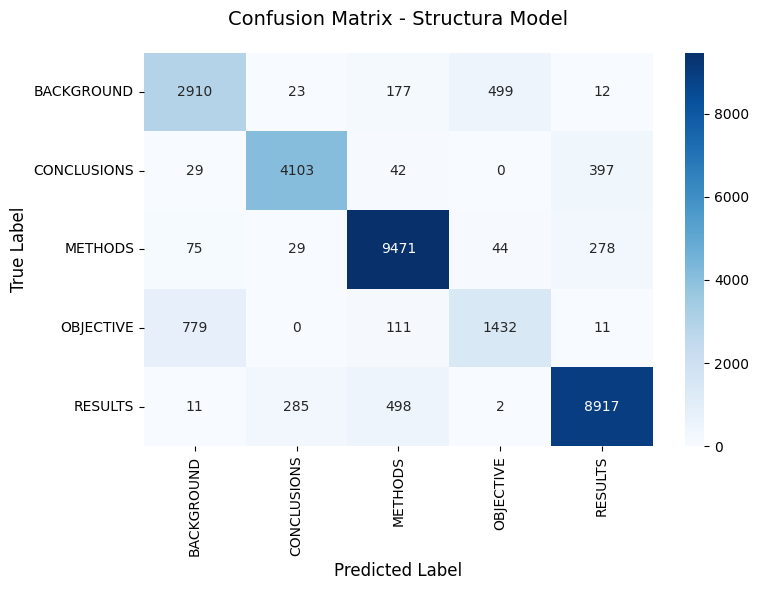

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved as confusion_matrix.png and download triggered!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from google.colab import files

# 1. Get predictions for test_pos_char_token_dataset
print("Generating predictions...")
pred_probs = model.predict(test_pos_char_token_dataset, verbose=1)
preds = np.argmax(pred_probs, axis=1)

# 2. Compute Confusion Matrix
cm = confusion_matrix(test_labels_encoded, preds)

# 3. Plot Confusion Matrix in Blue theme
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax
)
plt.title('Confusion Matrix - Structura Model', fontsize=14, pad=20)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()

# 4. Save the figure
plot_path = 'confusion_matrix.png'
plt.savefig(plot_path, dpi=300)
plt.show()

# 5. Download the saved image
files.download(plot_path)
print(f"Saved as {plot_path} and download triggered!")